# EDA — dengue nas nove capitais do Nordeste

Notebook reprodutível para descritivas, séries temporais, sazonalidade, STL, ADF/KPSS, ACF/PACF, Pearson/Spearman, CCF, Granger, VIF, faltantes e triagem de picos. O painel de entrada é `data/processed/painel_ne_dengue.parquet`, derivado de dados públicos InfoDengue/Mosqlimate 3rd IMDC 2026. O alvo é `casprov` (casos prováveis); a janela local vai de 2015-01-04 a 2026-03-08.

A documentação pública da base informa dengue por semana epidemiológica (SINAN/IBGE), clima ERA5 agregado por semana e população municipal DATASUS. A precipitação `precip_med` está em mm/h e não é acumulado semanal. [Dicionário oficial](https://sprint.mosqlimate.org/data/).

**Picos epidemiológicos não são removidos.** O corte IQR só sinaliza observações para conferência. A API Mosqlimate requer chave, enquanto os dados do pacote público já estão arquivados neste projeto.

In [1]:
from pathlib import Path
import sys
import subprocess
from IPython.display import display, Markdown, Image
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / 'src' / 'run_eda_capitais.py').exists():
    ROOT = Path.cwd().parent
assert (ROOT / 'data' / 'processed' / 'painel_capitais_eda.parquet').exists(), 'Base pública arquivada ausente; obtenha os arquivos descritos em https://sprint.mosqlimate.org/data/ e gere o painel parquet.'

# Executa a EDA completa e grava CSVs/PNGs e um relatório de interpretações.
subprocess.run([sys.executable, str(ROOT / 'src' / 'run_eda_capitais.py')], cwd=ROOT, check=True)
OUT = ROOT / 'reports' / 'eda_capitais'
print('Saídas:', OUT)

Saídas: C:\Users\Jp\Documents\ChatGPT\Projeto Final Disciplina _ Serie Temporais\entrega_professor\reports\eda_capitais


## Interpretação em linguagem simples

O relatório inclui a leitura e a decisão de modelagem para cada bloco de análise. A tabela `interpretacao_graficos.csv` traz notas individuais por figura/capital; os CSVs de testes também têm interpretações e decisões em cada linha.

# Análise exploratória — dengue nas capitais do Nordeste

## Base e escopo

A análise filtra a base pública InfoDengue/Mosqlimate arquivada localmente para as nove capitais. O recorte tem **9 capitais**, **5.256 linhas** e período de **04/01/2015 a 08/03/2026**. A unidade é capital × semana epidemiológica. Há 0 chaves capital-semana duplicadas.

O alvo é `casprov`, casos prováveis semanais. Incidência por 100 mil habitantes é apresentada como medida complementar. O rótulo `nivel_inc_mem == 2` indica incidência acima do limiar epidêmico do Moving Epidemics Method (MEM), conforme a documentação do InfoDengue/Mosqlimate. Os dados deste arquivo encerram em 8 de março de 2026; as análises não descrevem semanas posteriores.

### Origem dos dados

O arquivo público de dengue documenta casos prováveis como suspeitos menos descartados; o clima vem da reanálise ERA5/Copernicus organizada pelo Mosqlimate, e a população anual é de DATASUS/SVS. Links e períodos por fonte estão em `tables/fontes_e_periodos.csv`; as variáveis e unidades estão em `tables/dicionario_variaveis.csv`. A documentação oficial da base está em [Data documentation — 3rd IMDC](https://sprint.mosqlimate.org/data/), e a consulta municipal InfoDengue em [serviços da API](https://info.dengue.mat.br/services/api).

## Estatísticas descritivas

A proporção agregada de semanas com zero casos é 0,6%. Entre as semanas com valor positivo, mediana=47,0, P90=275,0 e P99=1.143,9 casos. As estatísticas por capital, incluindo dispersão, máximos, zeros, população e clima, estão em `tables/estatisticas_por_capital.csv`.

**Leitura para a modelagem:** as séries têm assimetria e picos; a mediana, os quantis e a proporção de zeros devem ser considerados junto com a média. Contagens e incidência respondem a perguntas diferentes, então as previsões de casos serão convertidas em incidência para analisar o limiar.

## Séries, agregado e sazonalidade

`figures/01_series_por_capital.png` mostra a trajetória semanal de cada capital. `figures/02_agregado_casos_incidencia.png` compara o total de casos e a incidência agregada, calculada como soma de casos dividida pela soma da população. `figures/03_sazonalidade_ano_capital.png` sobrepõe os perfis por semana epidemiológica e ano para distinguir um padrão anual recorrente de anos atípicos.

**Leitura para a modelagem:** picos sazonais recorrentes justificam um baseline sazonal de 52 semanas e variáveis de calendário. Diferenças entre capitais e entre anos apoiam modelos globais com identificador de cidade e validação temporal; não se deve pressupor um único perfil sazonal idêntico.

## Decomposição STL

A STL usa `log(1 + casos)` e período de 52 semanas para cada capital. Cada arquivo `figures/stl_<geocódigo>.png` separa tendência, sazonalidade anual e resíduo. A transformação reduz a influência visual de picos muito grandes, mas não os remove da base.

**Interpretação simples:** tendência resume mudanças graduais; sazonalidade resume o padrão que tende a reaparecer a cada ano; resíduo contém flutuações e eventos que esse padrão não explica. Um pico no resíduo pode ser um surto real. A decisão é comparar modelos com sazonalidade anual e manter semanas de pico para o treino e a avaliação.

## Estacionariedade: ADF e KPSS

Na série log(1+casos), ADF e KPSS concordam em estacionariedade em 8/9 capitais; concordam em não estacionariedade em 0/9. Nas demais, os resultados são discordantes/inconclusivos. Veja os p-valores e decisões por capital na tabela de testes.

ADF tem como hipótese nula uma raiz unitária; p<0,05 é evidência contra essa hipótese. KPSS tem como hipótese nula estacionariedade; p<0,05 é evidência contra estacionariedade. Por isso, a leitura conjunta ajuda a separar concordância de discordância. A tabela `tables/testes_estacionariedade.csv` inclui estatísticas, defasagens usadas, p-valores, interpretação e decisão para `log1p_nivel` e `log1p_diferenca_52` em cada capital.

**Decisão para a modelagem:** a necessidade de diferenciação não será decidida olhando a série de teste. Transformações e diferenças serão ajustadas dentro de cada janela de treino; modelos também serão comparados sem diferença quando os testes discordarem.

## Correlação, CCF, Granger e VIF

As matrizes Pearson e Spearman são calculadas separadamente dentro de cada capital; as figuras mostram a mediana entre cidades e as tabelas mantêm os resultados individuais. A CCF compara log(1+casos) na semana atual com clima observado 2–8 semanas antes. O Granger usa diferenças sazonais de 52 semanas e testa se o clima melhora a previsão bivariada de casos. Os p-valores de Granger não têm correção por múltiplos testes e não demonstram causalidade.

As figuras `06_matriz_pearson.png`, `06_matriz_spearman.png`, `07_ccf_clima_defasagens.png` e `08_vif_clima.png` e as tabelas `correlacoes_por_capital.csv`, `ccf_por_capital.csv`, `granger_por_capital.csv`, `vif_por_capital.csv` e `decisao_variaveis_defasagens.csv` documentam essas análises.

Candidatas que resultam da triagem (uma por variável climática):

- `precip_med`: Pearson mediano 0,201 e Spearman mediano 0,246; lag CCF candidato 3 semanas (mediana 0,282); 8 testes Granger com p<0,05 sem ajuste; VIF mediano 2,2.
- `rel_humid_med`: Pearson mediano 0,323 e Spearman mediano 0,319; lag CCF candidato 4 semanas (mediana 0,394); 11 testes Granger com p<0,05 sem ajuste; VIF mediano 5,1.
- `temp_med`: Pearson mediano -0,206 e Spearman mediano -0,202; lag CCF candidato 2 semanas (mediana -0,159); 9 testes Granger com p<0,05 sem ajuste; VIF mediano 9,6.

**Conclusão para a modelagem:** as defasagens climáticas com maior |CCF| mediana ficam registradas como candidatas, junto com o número de testes Granger significativos e o VIF mediano. Isso não autoriza escolher variáveis olhando o teste. A seleção final ocorre dentro do treino walk-forward; para um horizonte h, clima só entra se o lag for ≥ h ou se houver previsão climática disponível na origem.

### Diferença entre versões públicas de casos

A série `casprov` da extração InfoDengue e o arquivo histórico público têm 183 diferenças em 5256 semanas-capital (3,48%); maior diferença absoluta=159 casos. A auditoria por cidade está em `tables/auditoria_versoes_casos.csv`. Mantive `casprov` como alvo por consistência com a extração usada no alerta MEM e registrarei a data da extração; as diferenças refletem revisão/versão, não dados sintéticos.

## ACF e PACF

Os arquivos `figures/acf_pacf_<geocódigo>.png` mostram a autocorrelação (ACF) e a autocorrelação parcial (PACF) de `log(1 + casos)` até 52 semanas. Picos próximos a 52 semanas são compatíveis com dependência anual; picos nas primeiras semanas sugerem persistência de curto prazo. ACF/PACF orientam defasagens candidatas, mas não selecionam o modelo sozinhas.

**Decisão para a modelagem:** testar lags de casos de 1 a 8 semanas e 52 semanas como candidatos; a validação walk-forward decide quais ajudam. Para previsão de 4 semanas, recursos só entram quando seriam conhecidos na origem da previsão.

## Faltantes e outliers

Há 0 valores faltantes no alvo. Nas variáveis climáticas avaliadas, há 0 células ausentes (0,000% das células clima-capital-semana). A tabela `tables/faltantes_por_variavel_capital.csv` localiza ausências e distingue faltantes de zeros observados. Semanas ausentes não serão convertidas automaticamente em zero; se houver faltante climático, serão avaliados indicadores de ausência e imputação temporal/por série apenas no treino, com análise de sensibilidade.

A regra IQR sinalizou 575 valores altos para inspeção; 538 deles também coincidem com o indicador de surto MEM quando disponível. A lista está em `tables/picos_sinalizados_para_revisao.csv`. A regra estatística é apenas uma triagem: **nenhum pico foi removido ou winsorizado**. Só corrigiremos um registro se houver evidência verificável de erro de origem ou unidade. Assim, surtos observados permanecem na análise.

O gráfico `figures/05_picos_para_revisao.png` identifica os pontos sinalizados e os mantém desenhados. Extremos meteorológicos também serão conferidos com os intervalos plausíveis e com os valores da fonte antes de qualquer correção; não será feita exclusão automática.

## Limitações que afetam a leitura

A base é histórica e pode ser revisada pela fonte; termina em março de 2026. Casos prováveis são suspeitos menos descartados, agregados pela semana epidemiológica de início dos sintomas. Clima é reanálise horária ERA5 resumida por município e semana, não observação independente de uma estação por capital. `precip_med` é a taxa média semanal de precipitação em mm/h; ela não é precipitação total semanal. População vem da série municipal anual do DATASUS, carregada para frente sem usar anos futuros.

A documentação do pacote público de dados 3rd IMDC 2026 especifica os arquivos de dengue, clima ERA5 e população; a documentação da API Mosqlimate indica chave de usuário para a consulta ao datastore. A API antiga `alertcity` respondeu a uma consulta de teste para São Luís, mas a EDA usa os dados já baixados e mantém todos os arquivos originais no projeto.

## Arquivos

- Tabelas: `tables/fontes_e_periodos.csv`, `tables/dicionario_variaveis.csv`, `tables/estatisticas_por_capital.csv`, `tables/faltantes_por_variavel_capital.csv`, `tables/picos_sinalizados_para_revisao.csv`, `tables/testes_estacionariedade.csv`, `tables/stl_interpretacao.csv`, `tables/serie_agregada_capitais.csv`, `tables/perfil_sazonal_ano_semana.csv`, `tables/interpretacao_graficos.csv`, `tables/correlacoes_por_capital.csv`, `tables/ccf_por_capital.csv`, `tables/granger_por_capital.csv`, `tables/vif_por_capital.csv`, `tables/decisao_variaveis_defasagens.csv` e `tables/auditoria_versoes_casos.csv`.
- Figuras: séries por cidade, agregado, sazonalidade, mapa de faltantes, triagem de picos, matrizes Pearson/Spearman, CCF, VIF, nove STL e nove painéis ACF/PACF.

### 01_series_por_capital.png

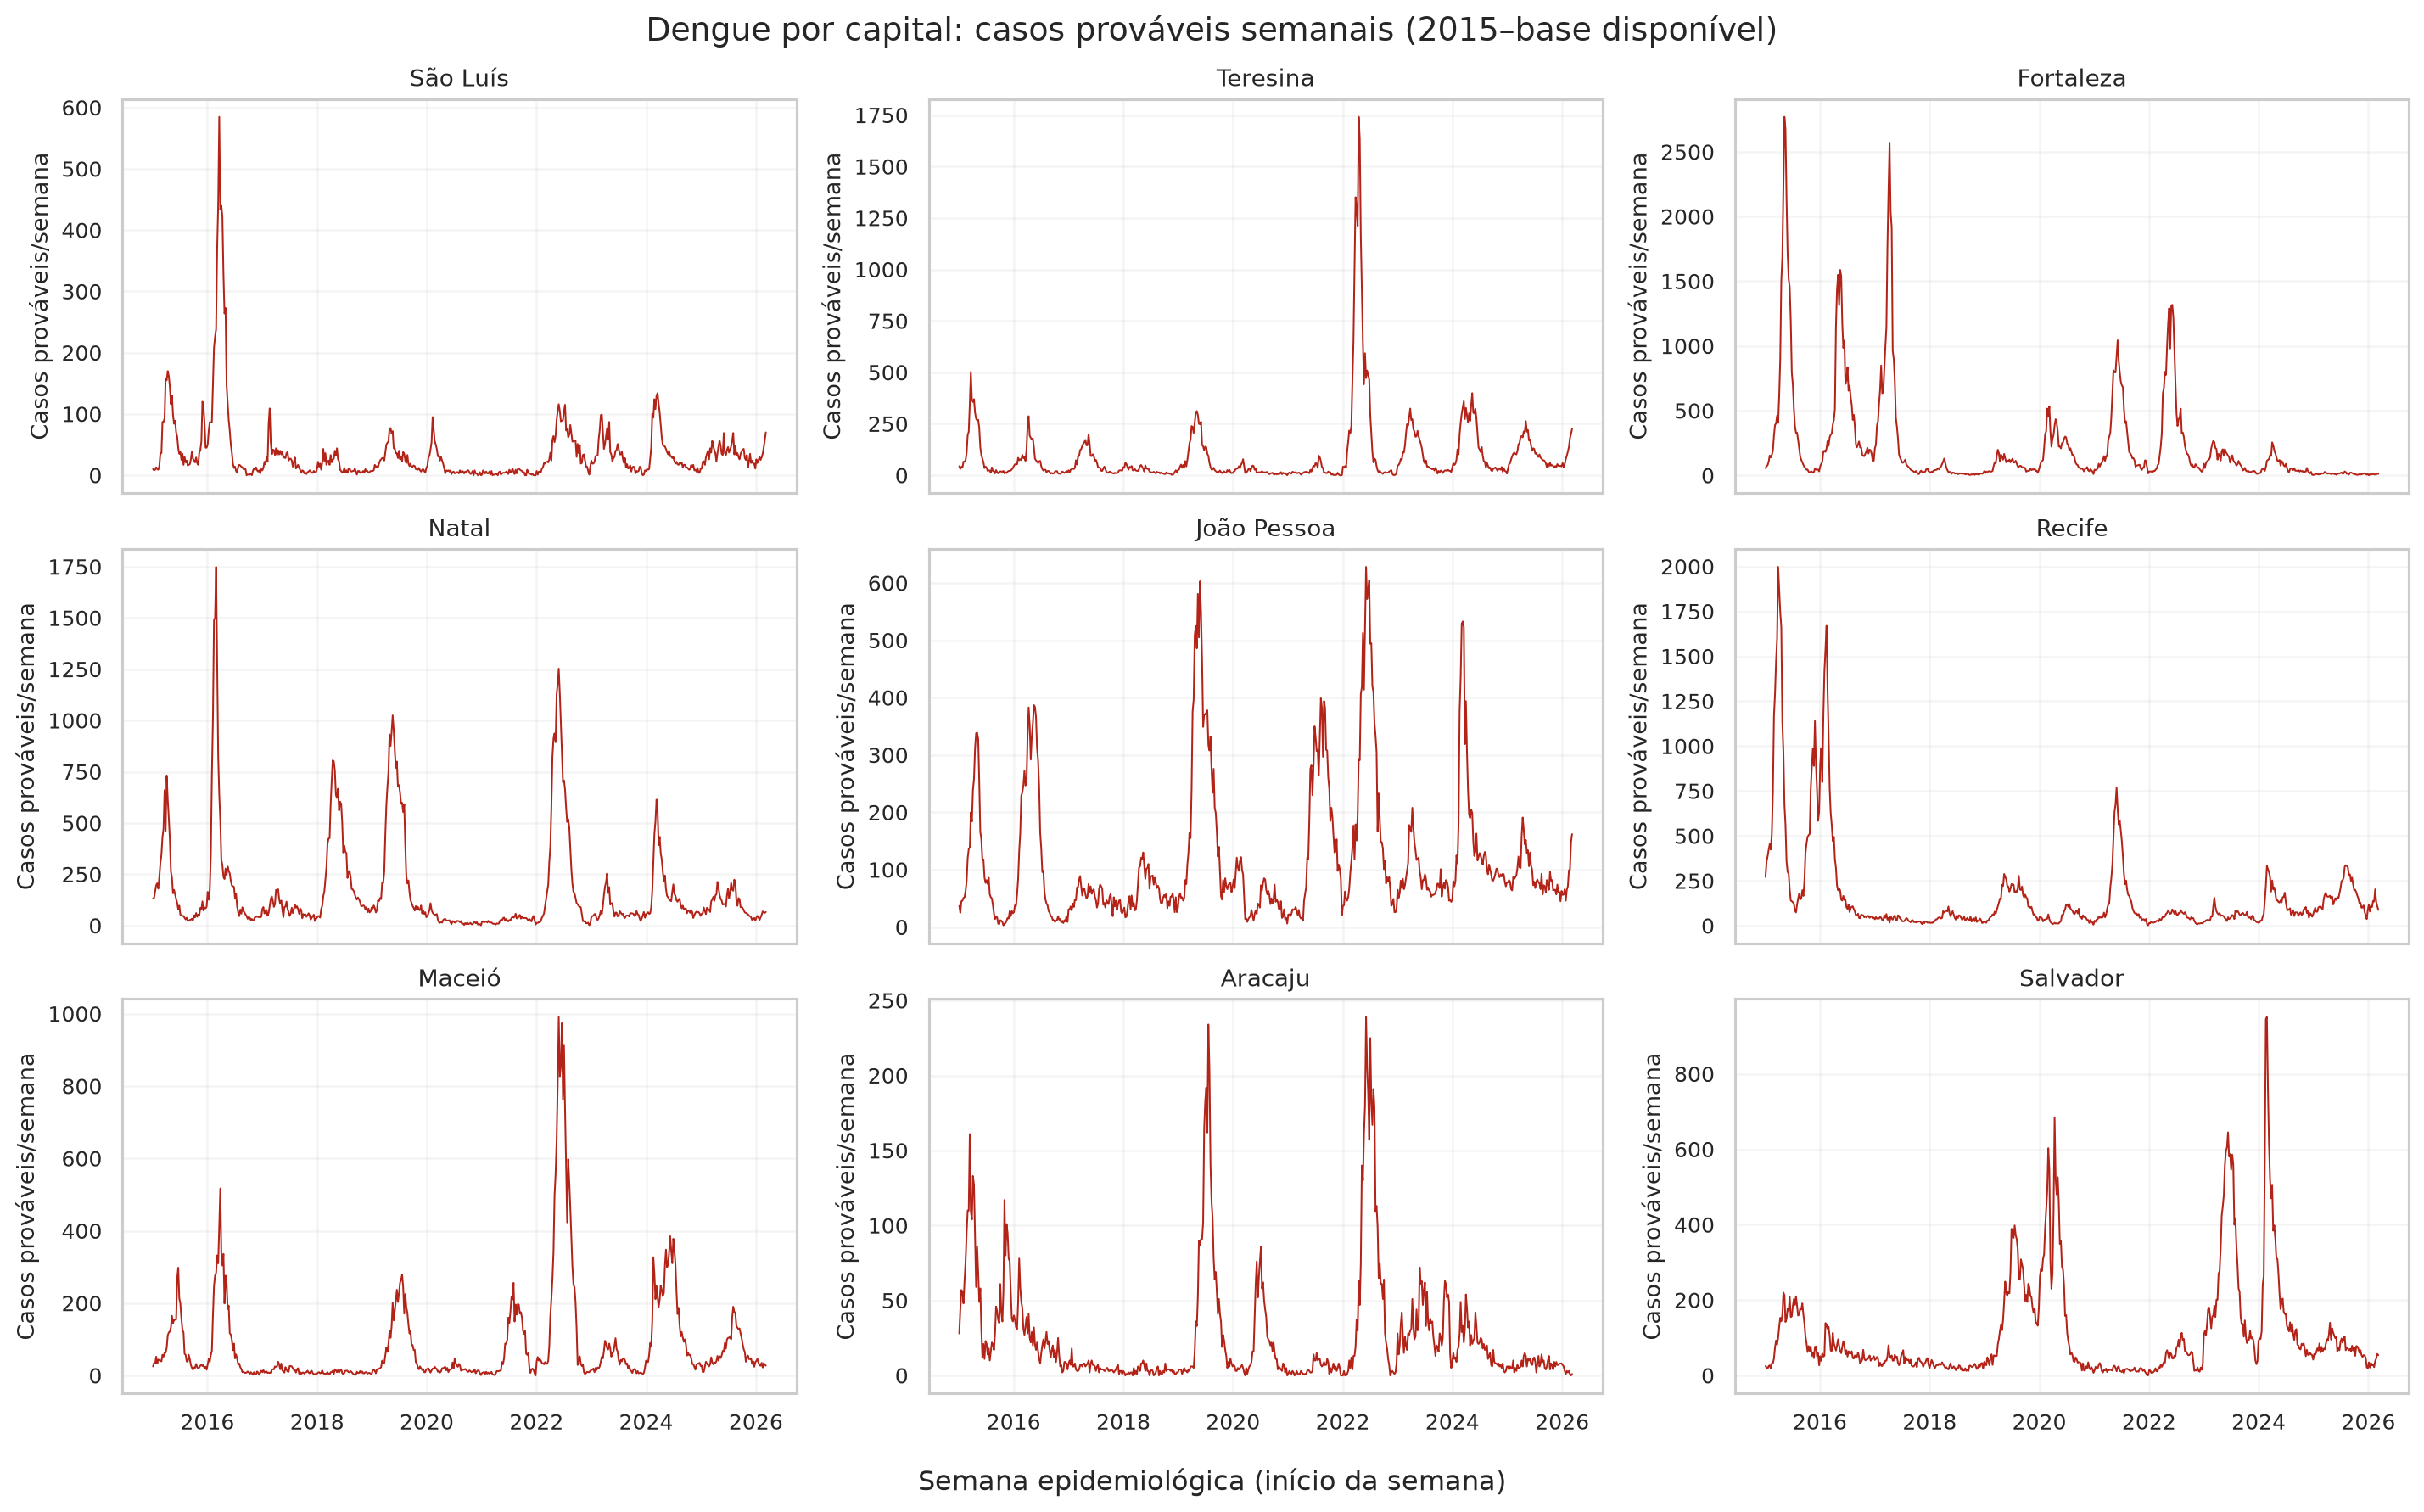

### 02_agregado_casos_incidencia.png

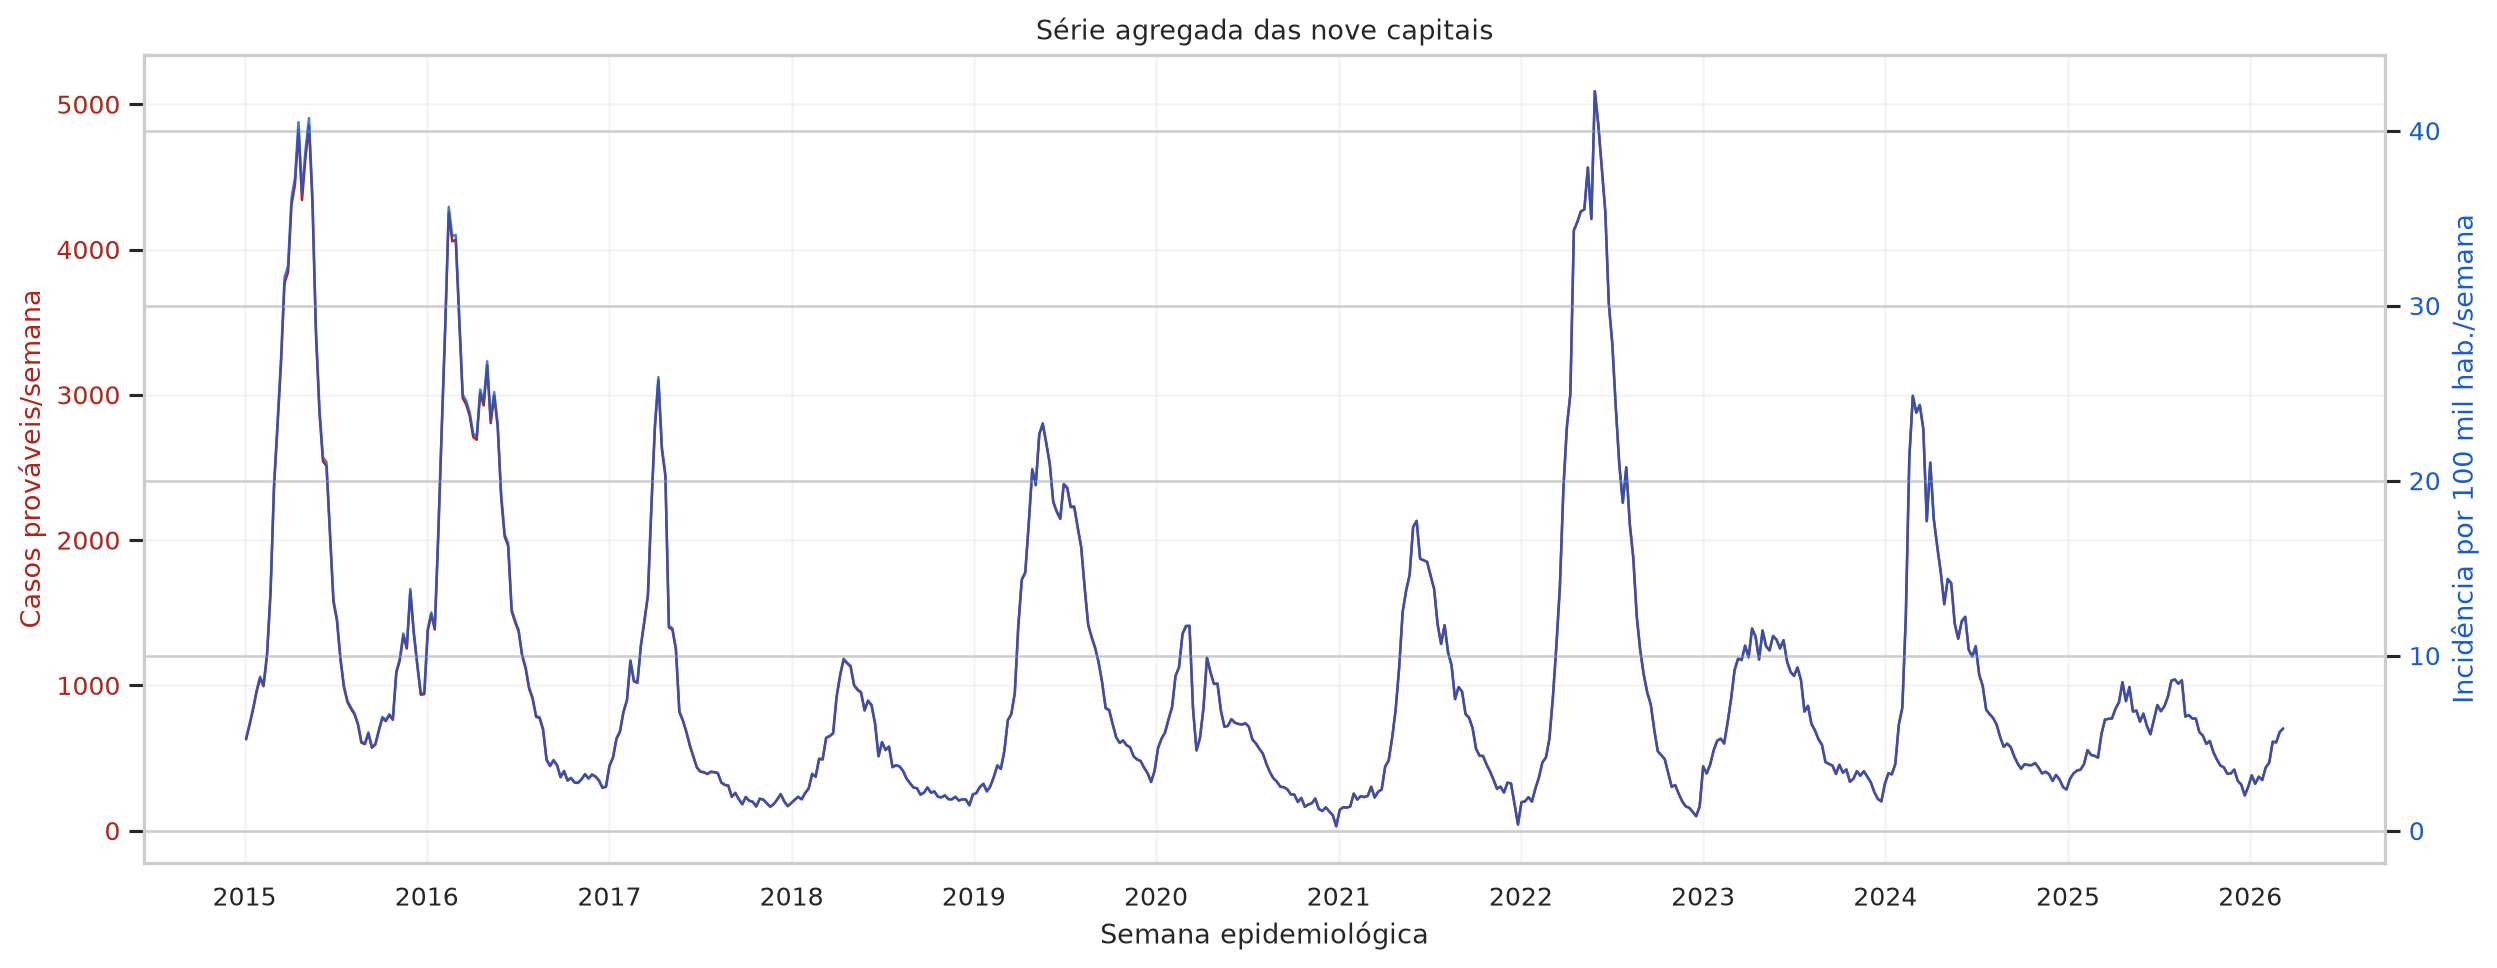

### 03_sazonalidade_ano_capital.png

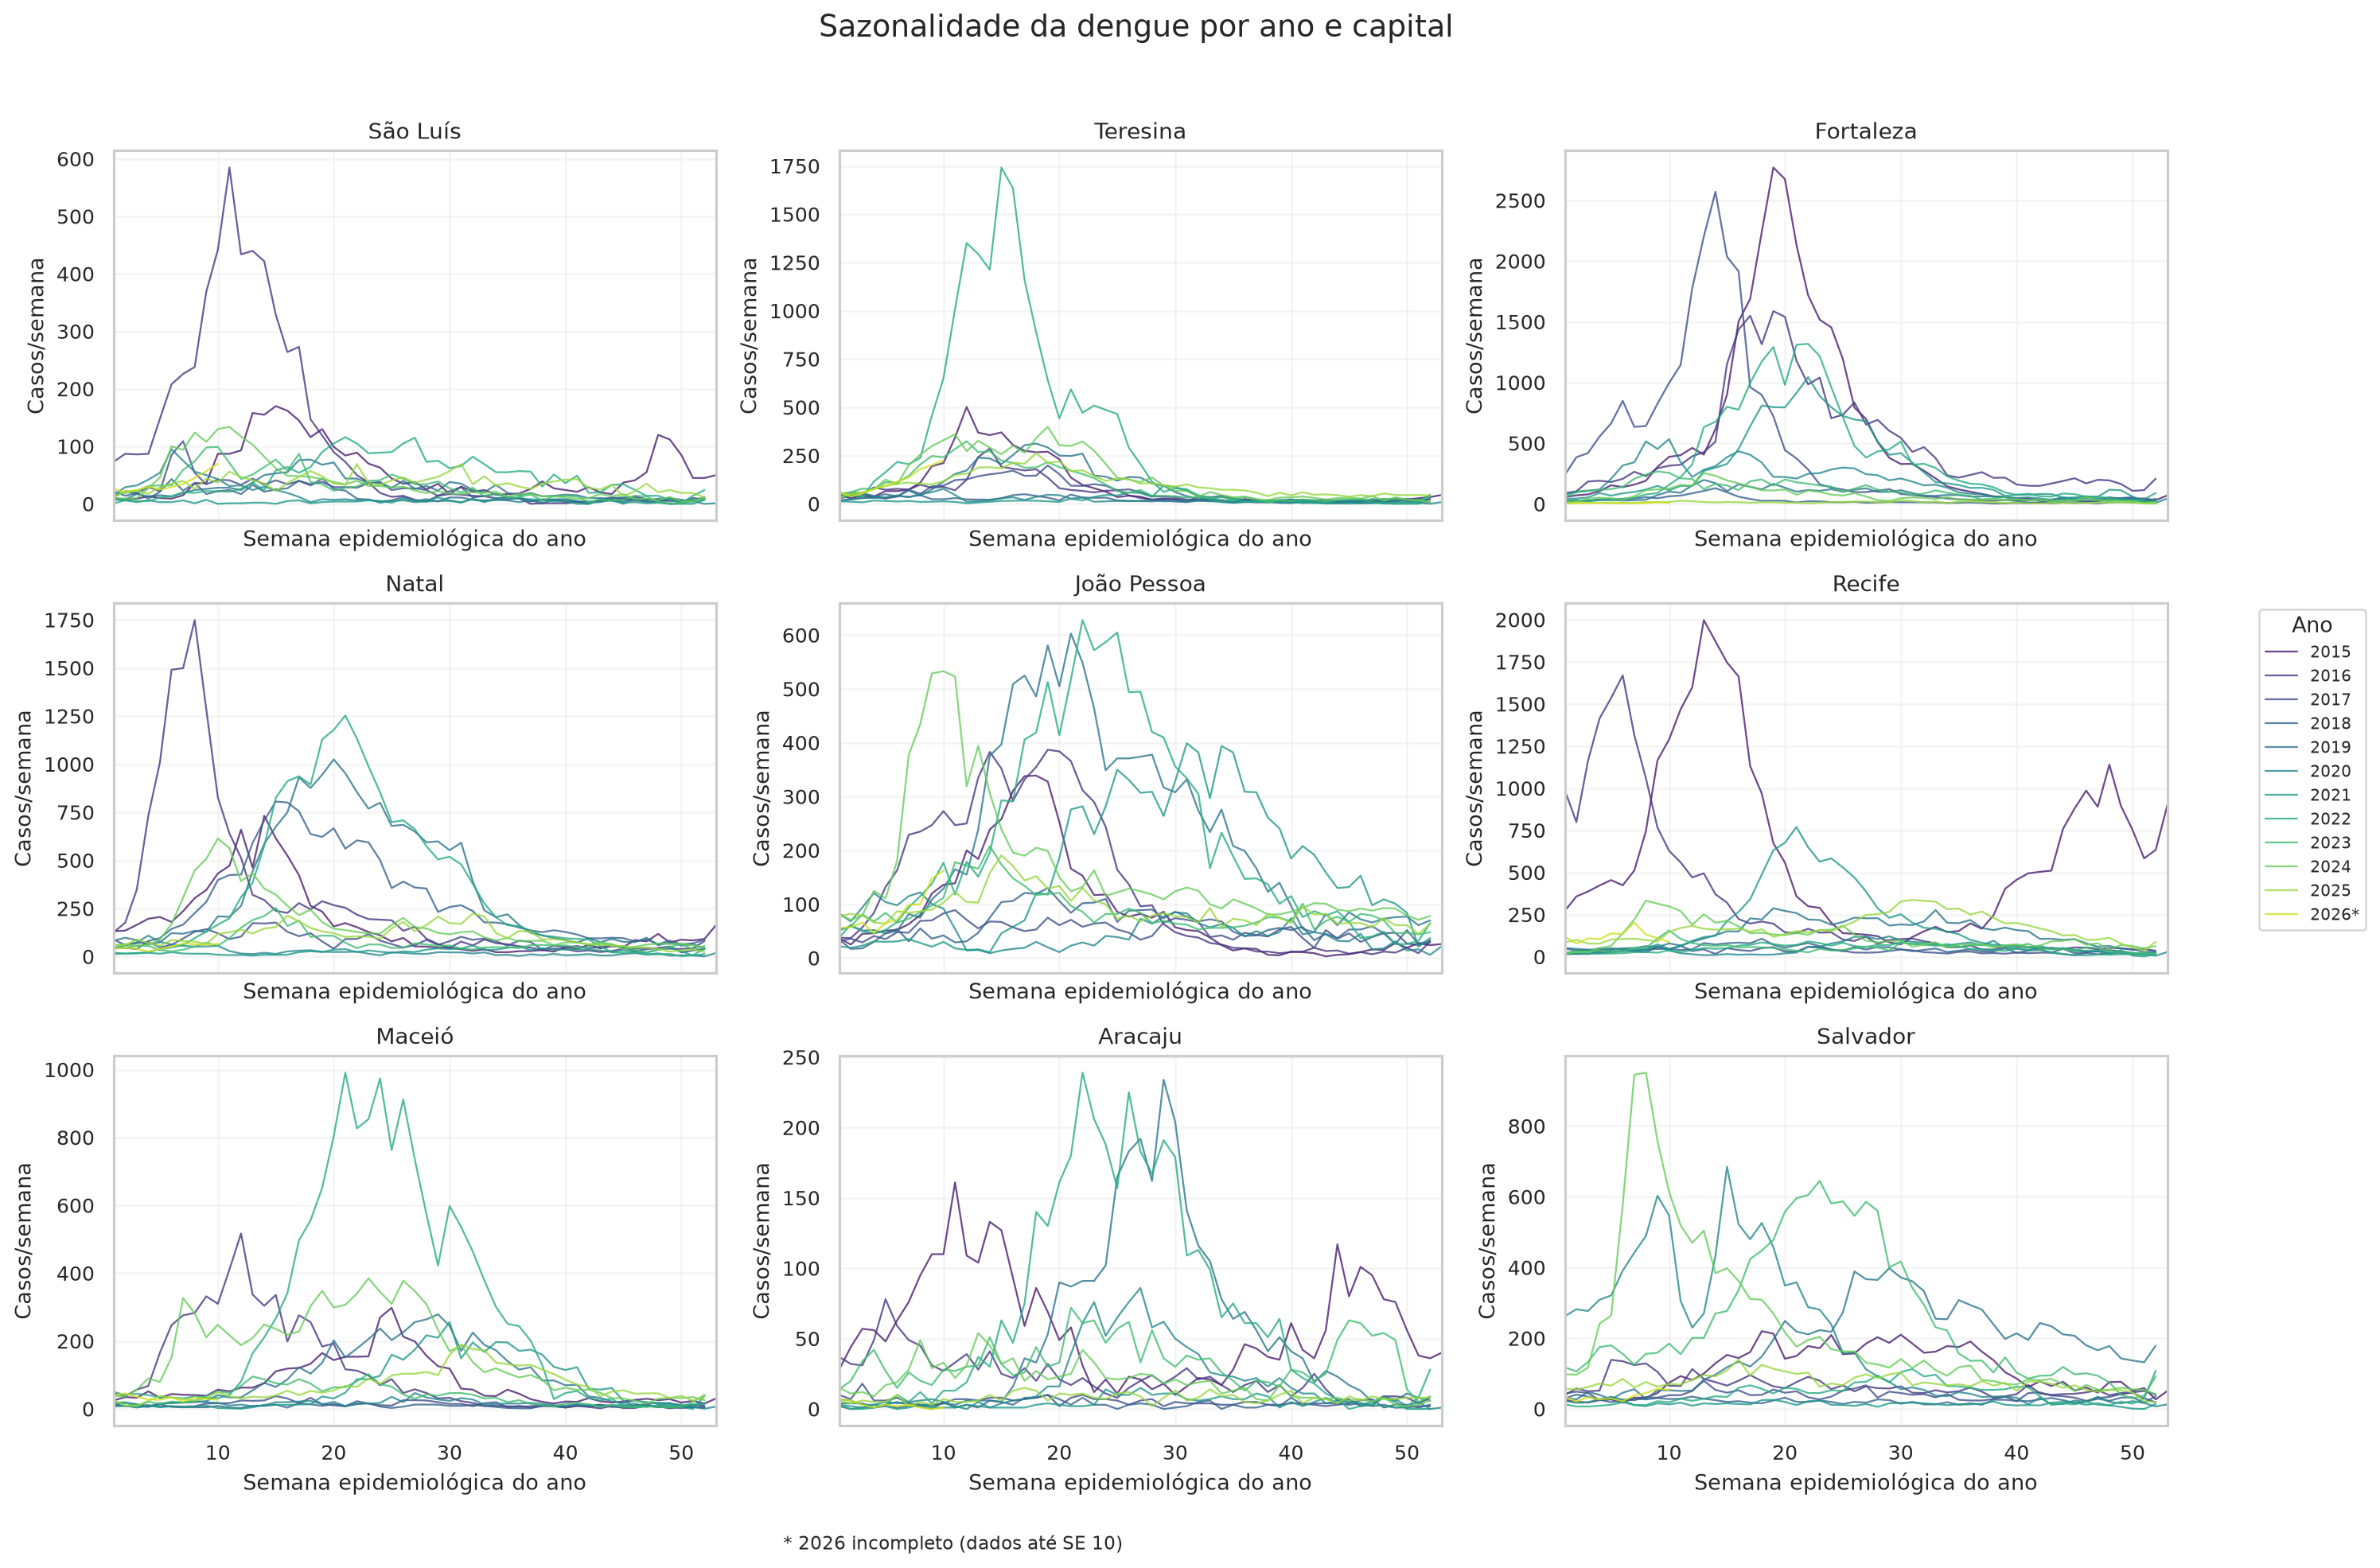

### 04_faltantes_heatmap.png

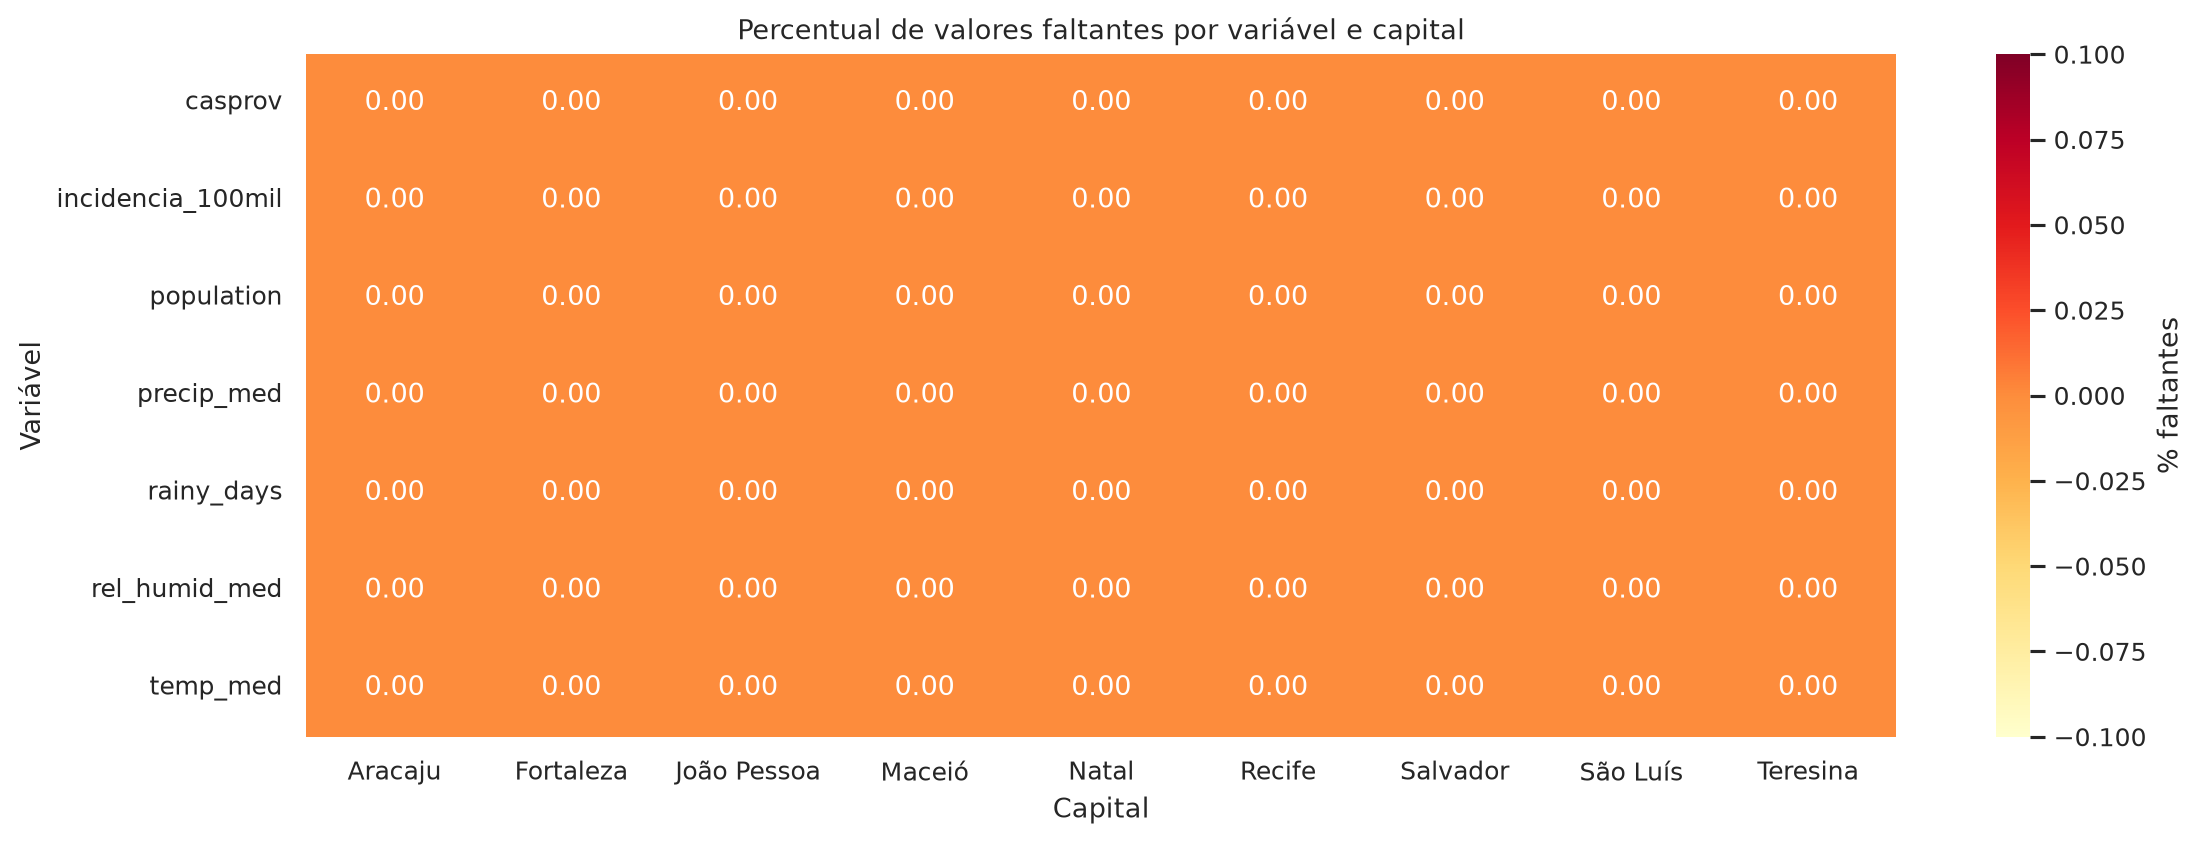

### 05_picos_para_revisao.png

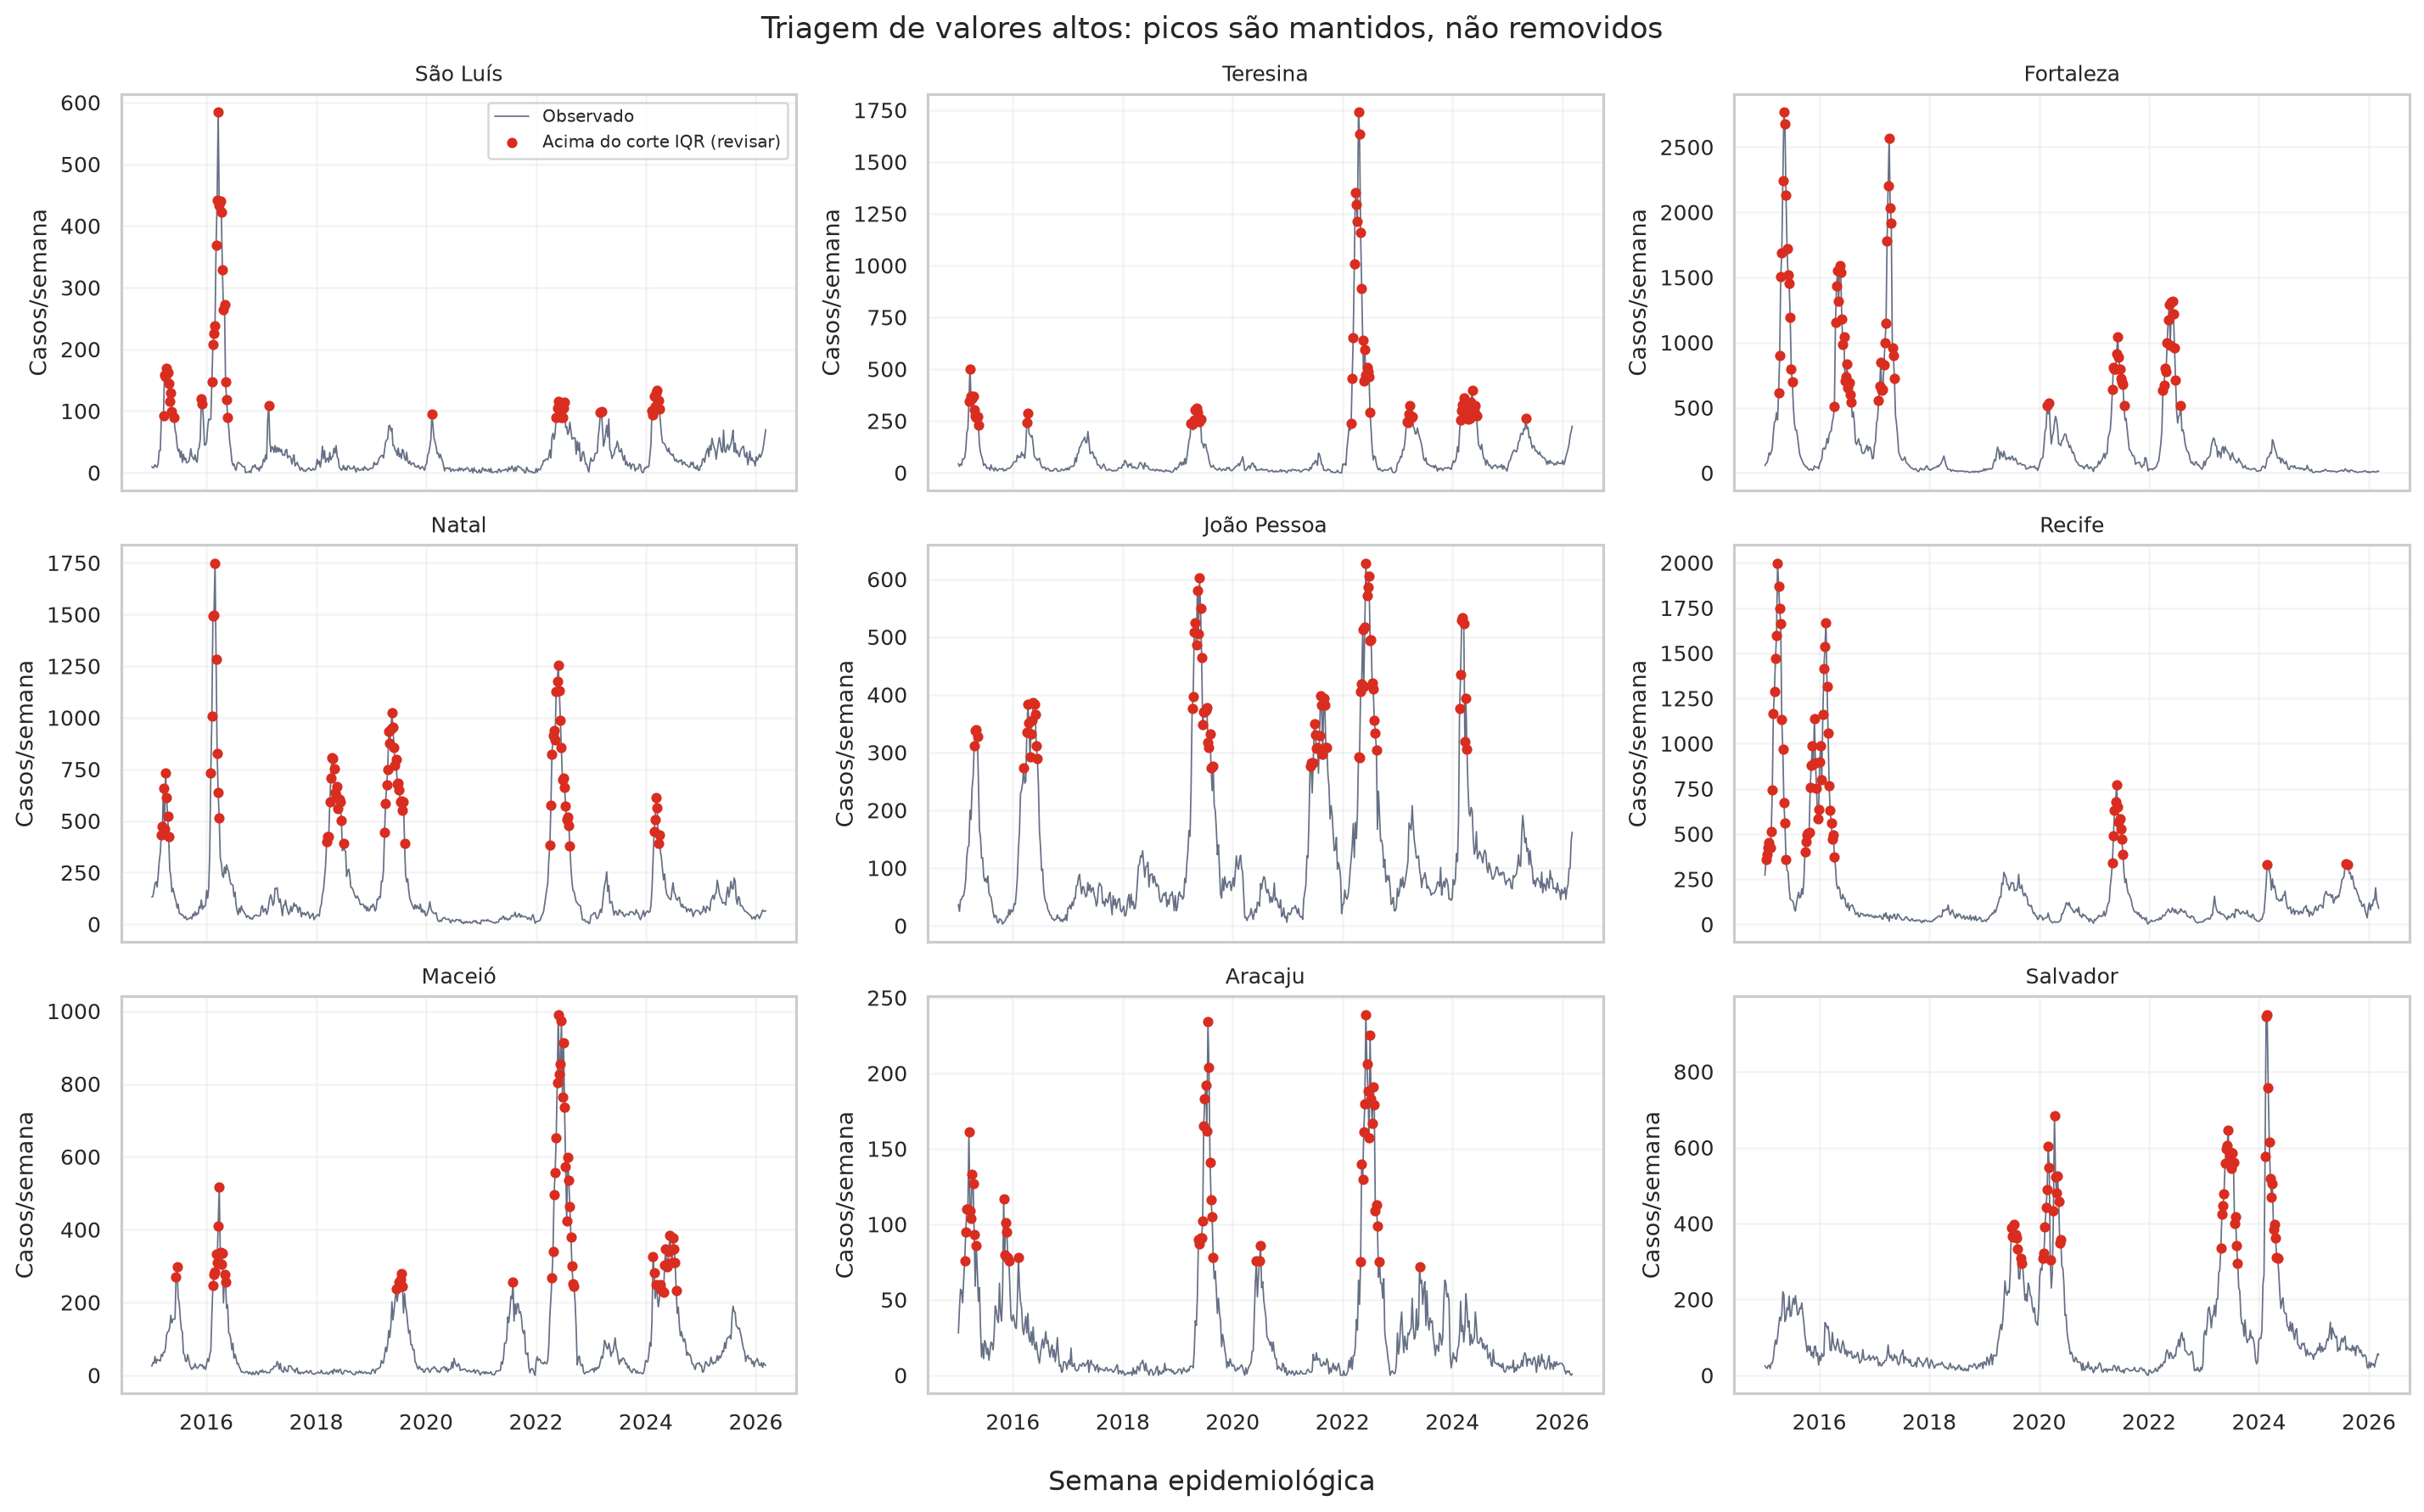

### 06_matriz_pearson.png

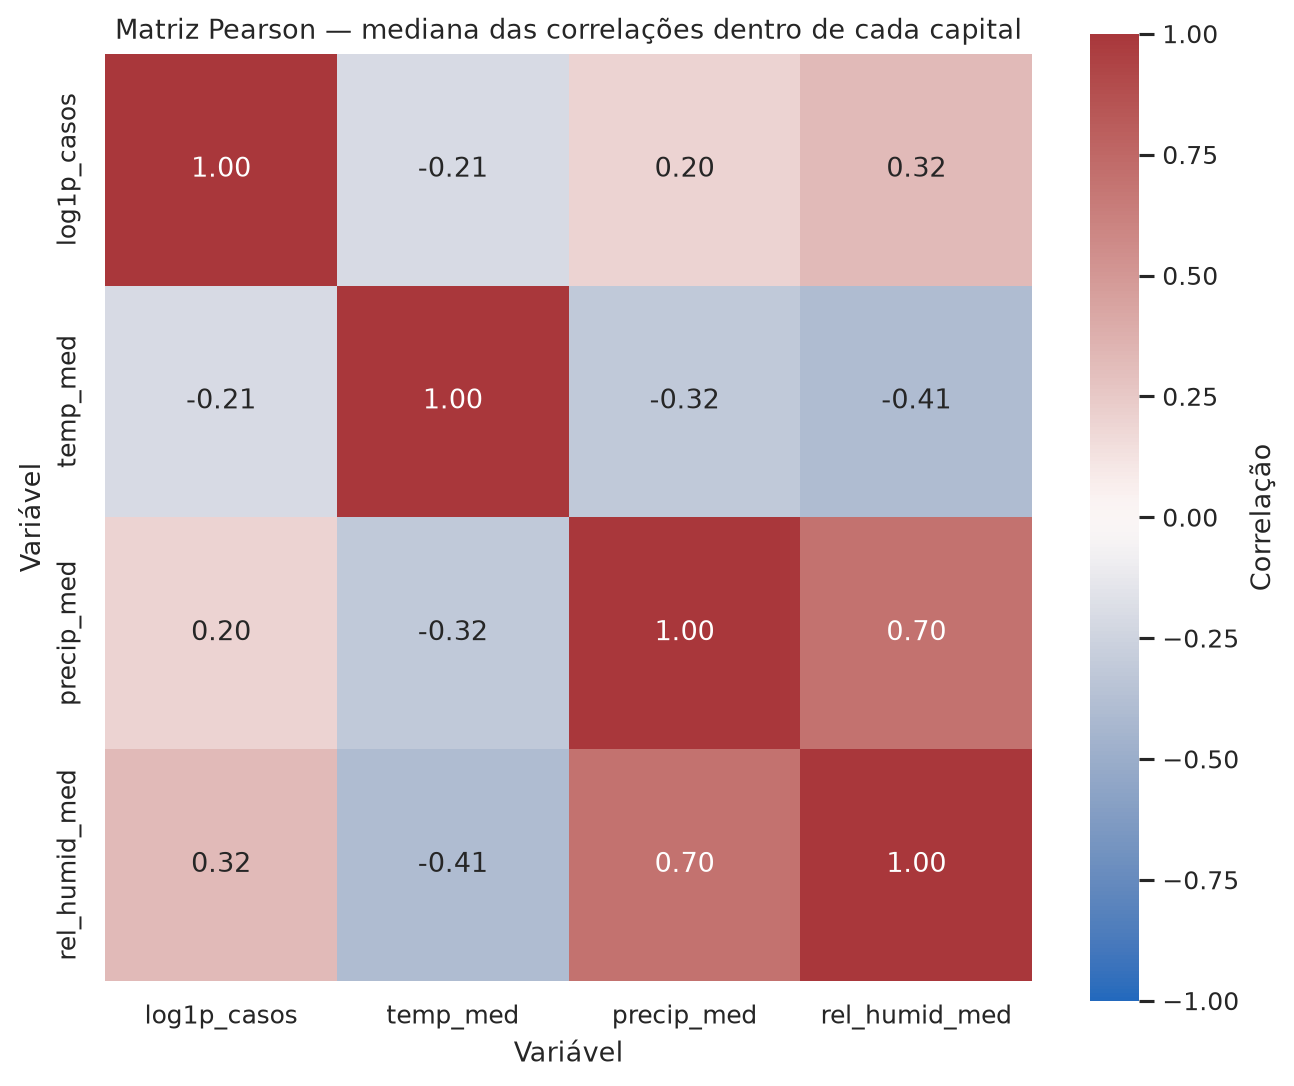

### 06_matriz_spearman.png

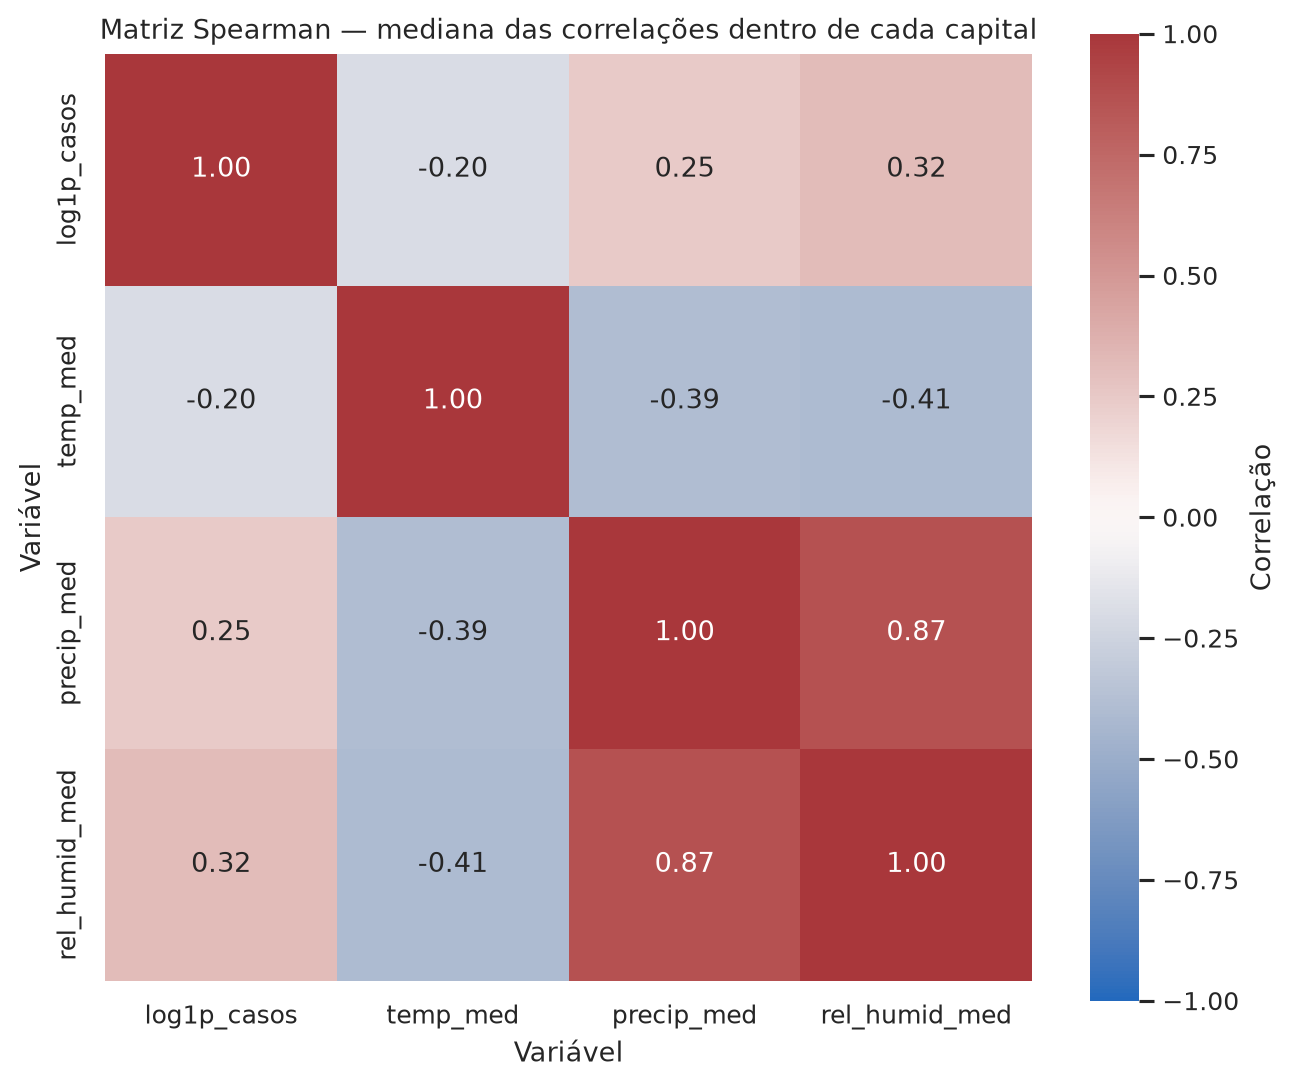

### 07_ccf_clima_defasagens.png

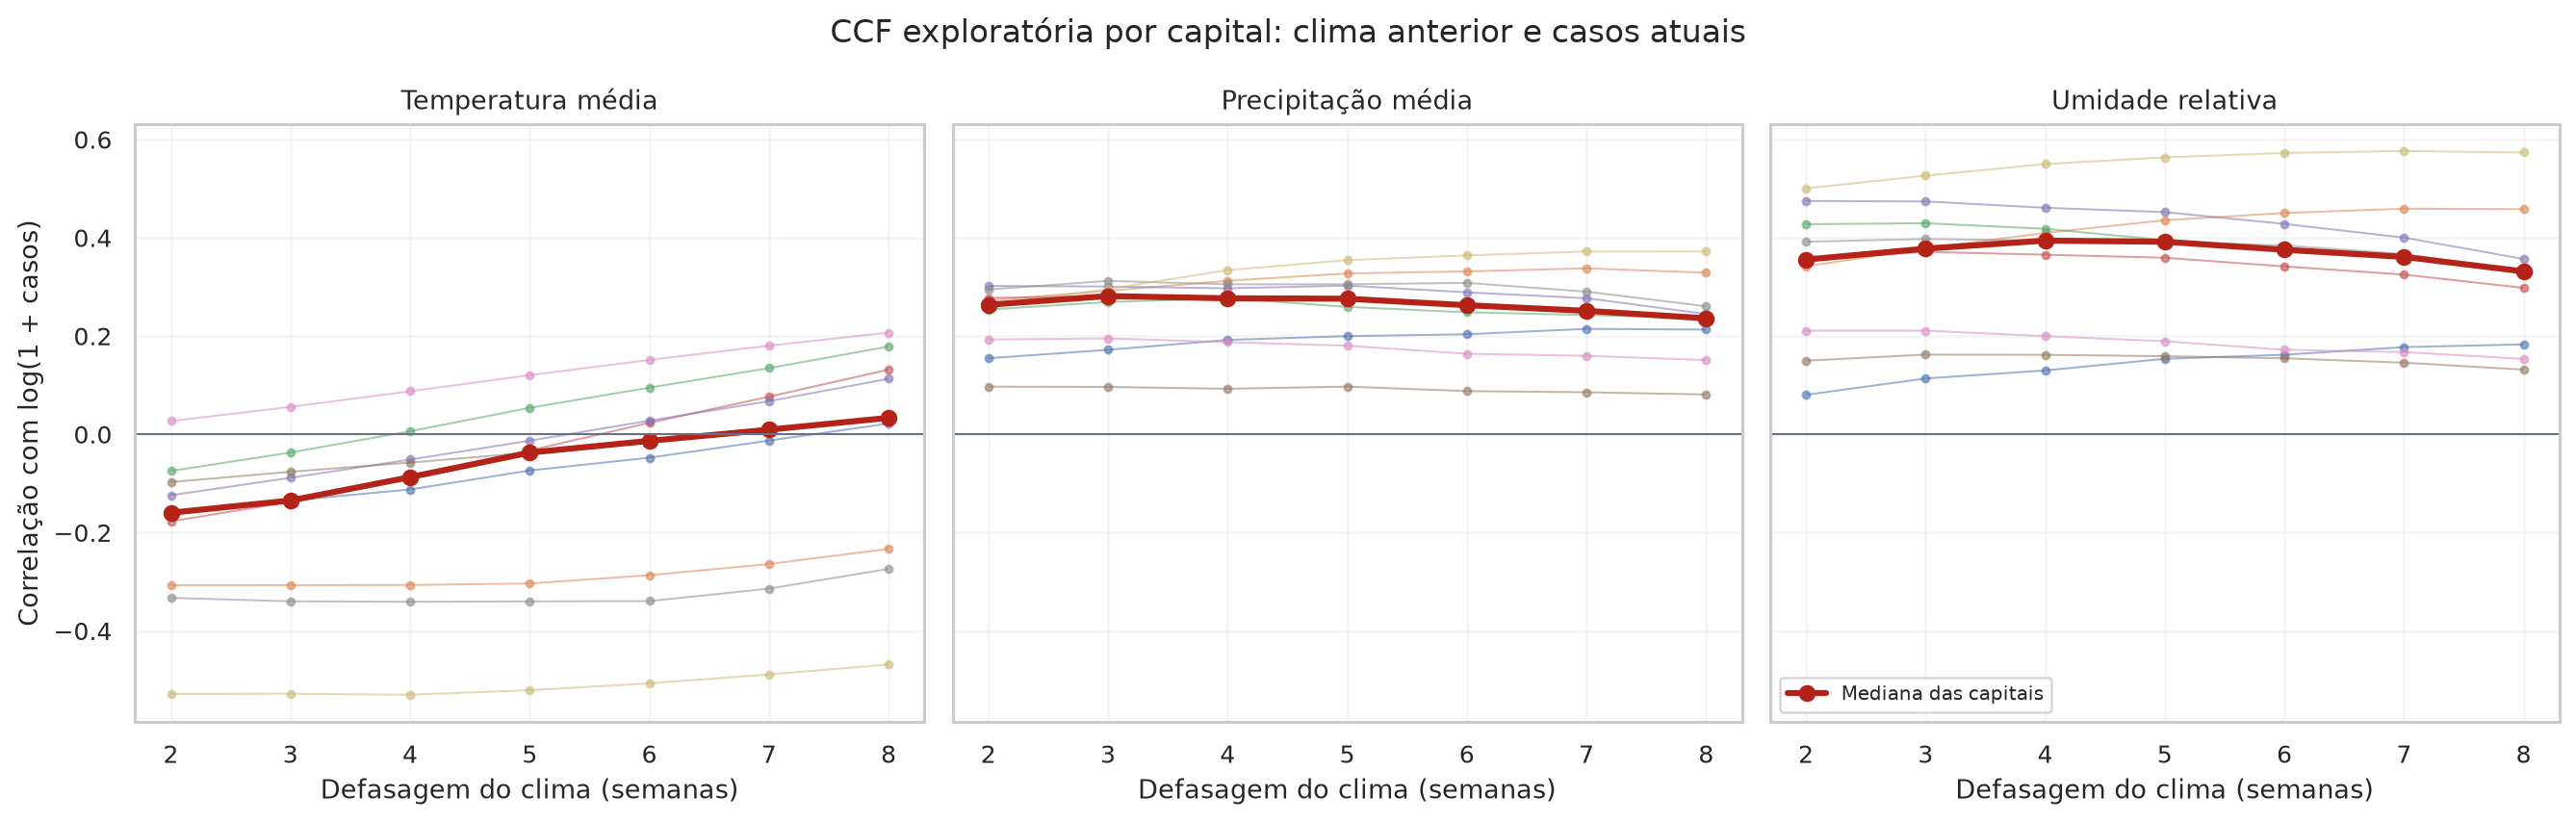

### 08_vif_clima.png

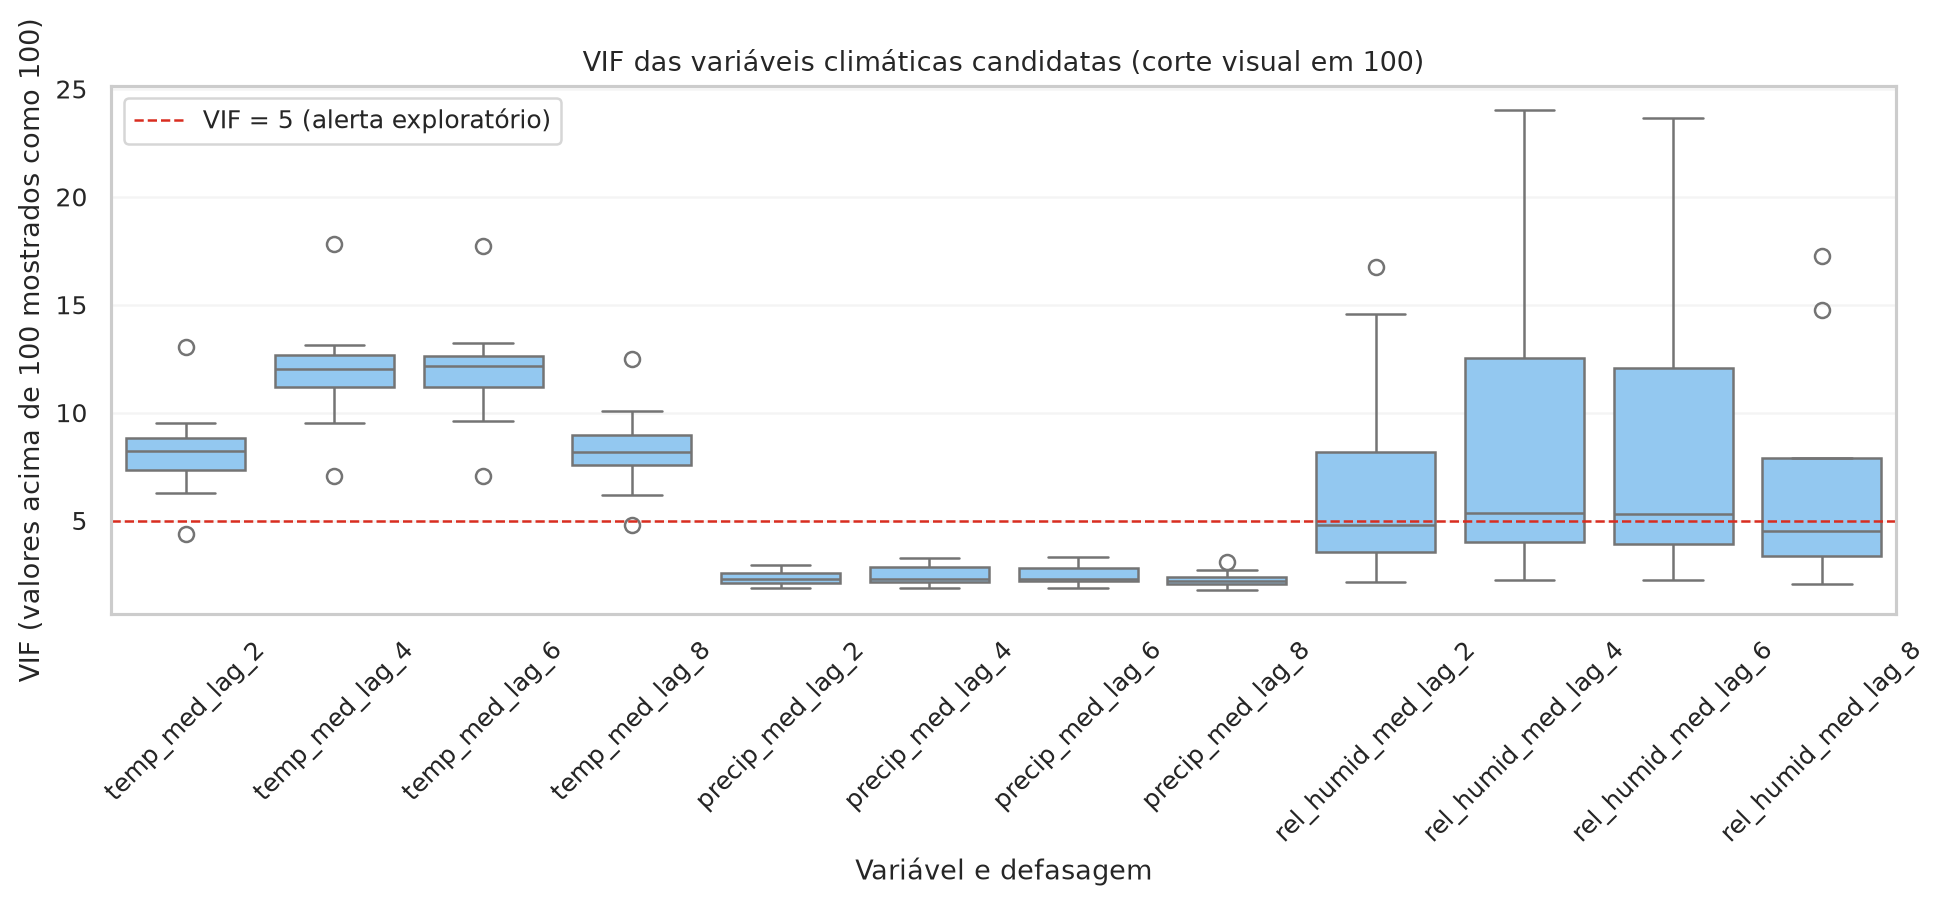

### acf_pacf_2111300.png

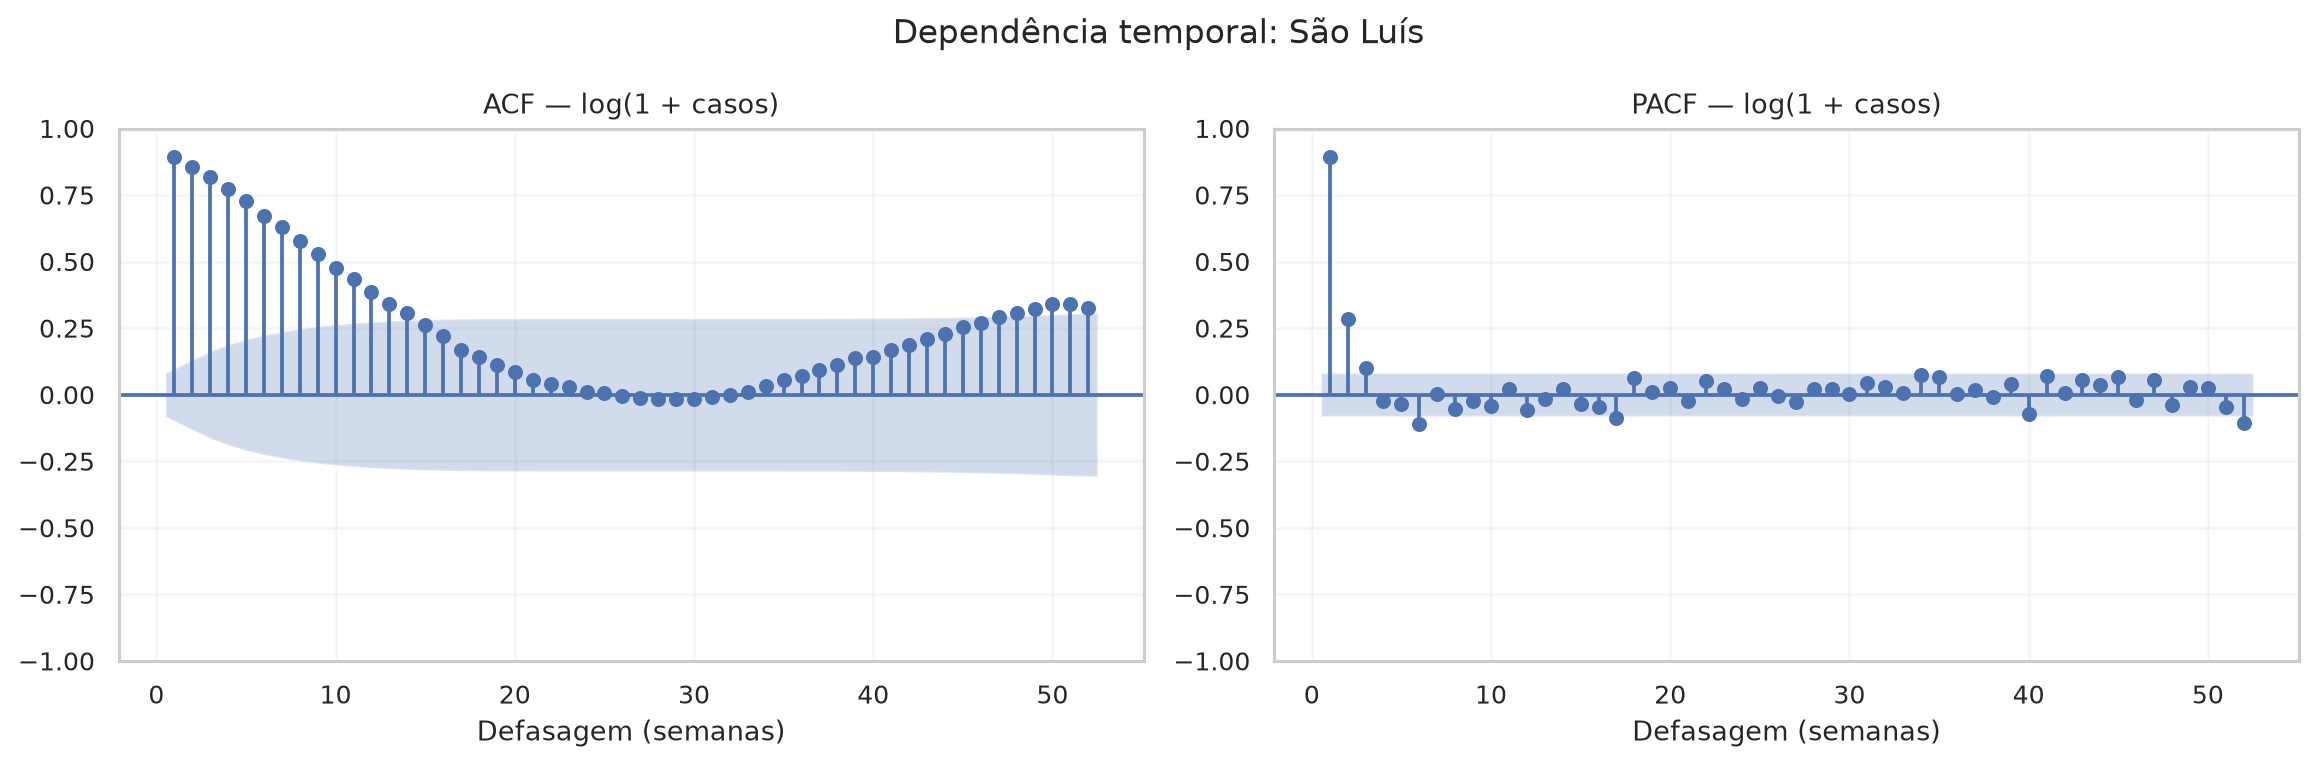

### acf_pacf_2211001.png

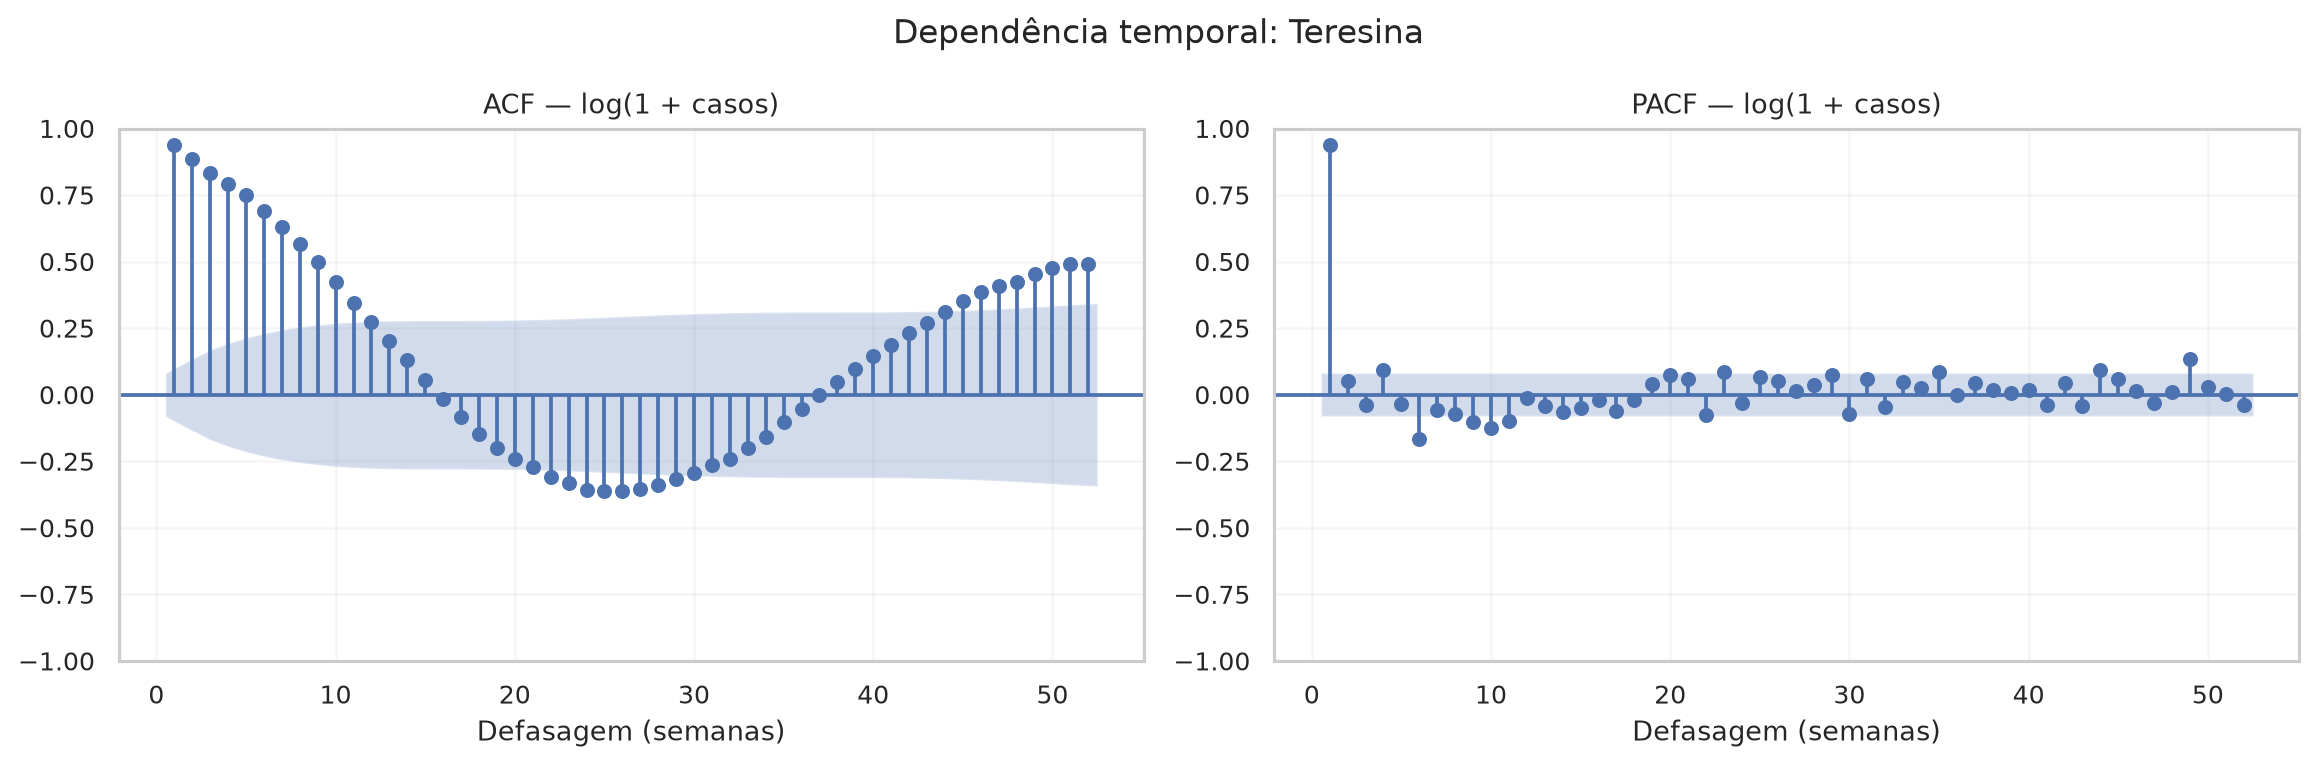

### acf_pacf_2304400.png

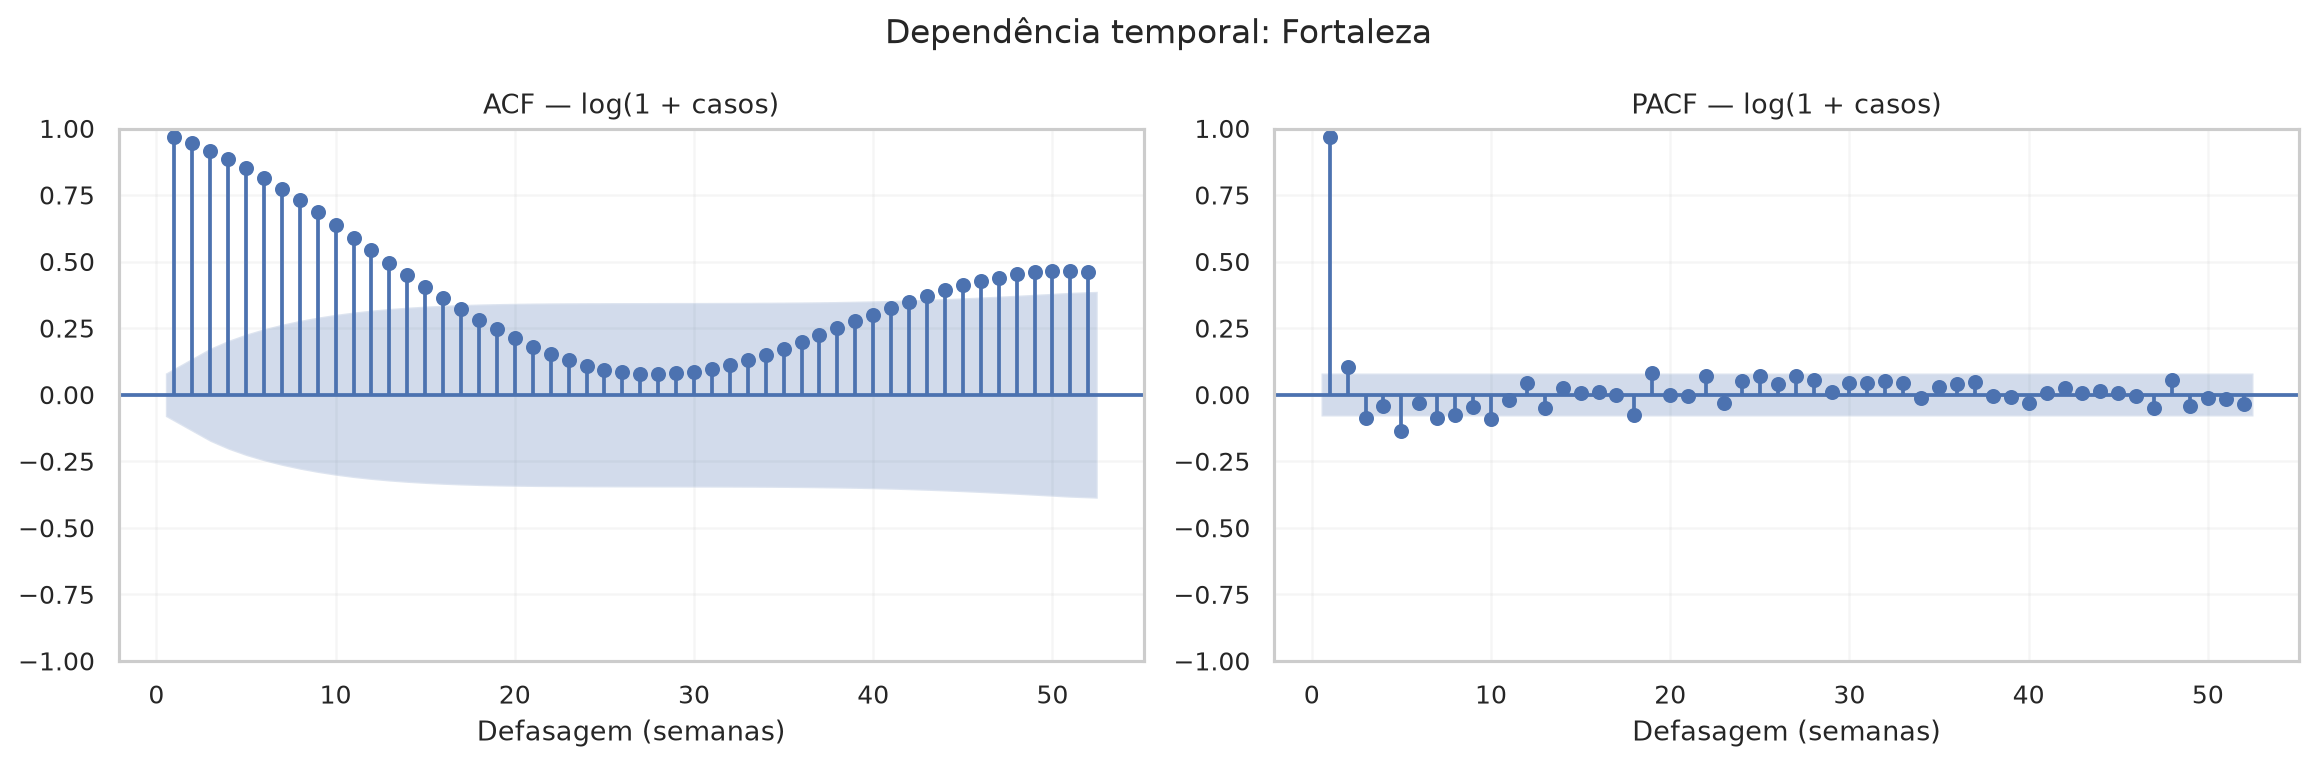

### acf_pacf_2408102.png

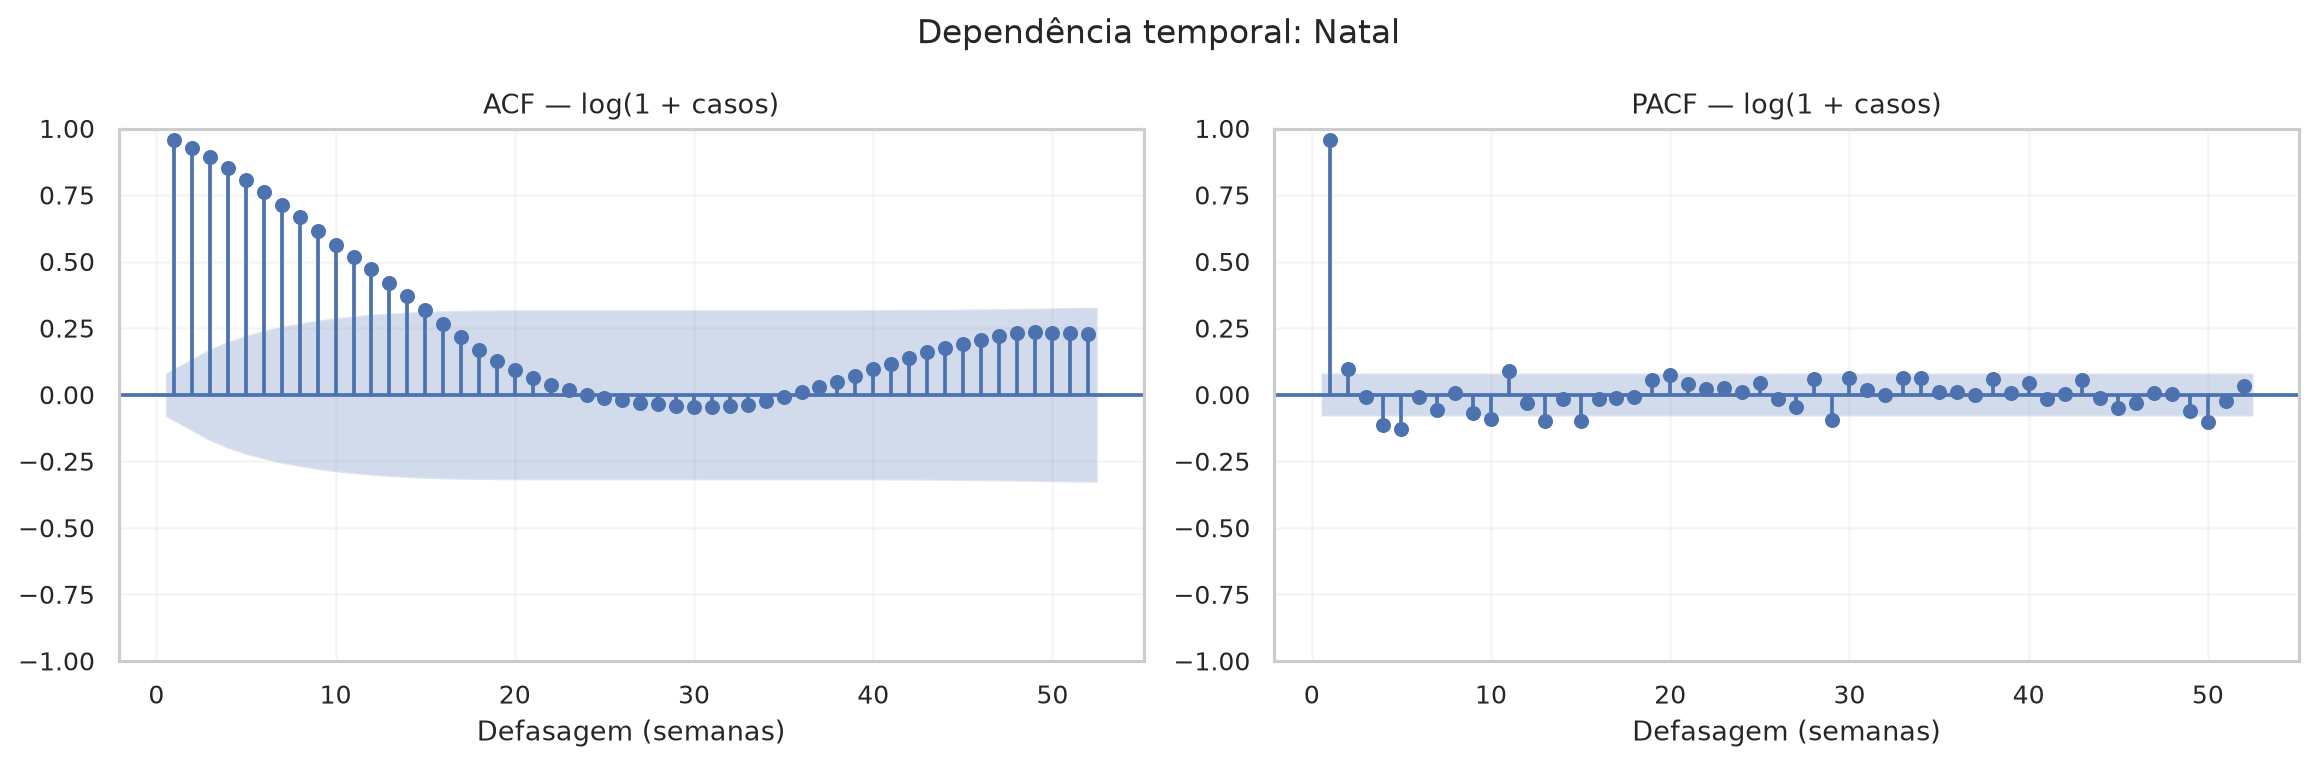

### acf_pacf_2507507.png

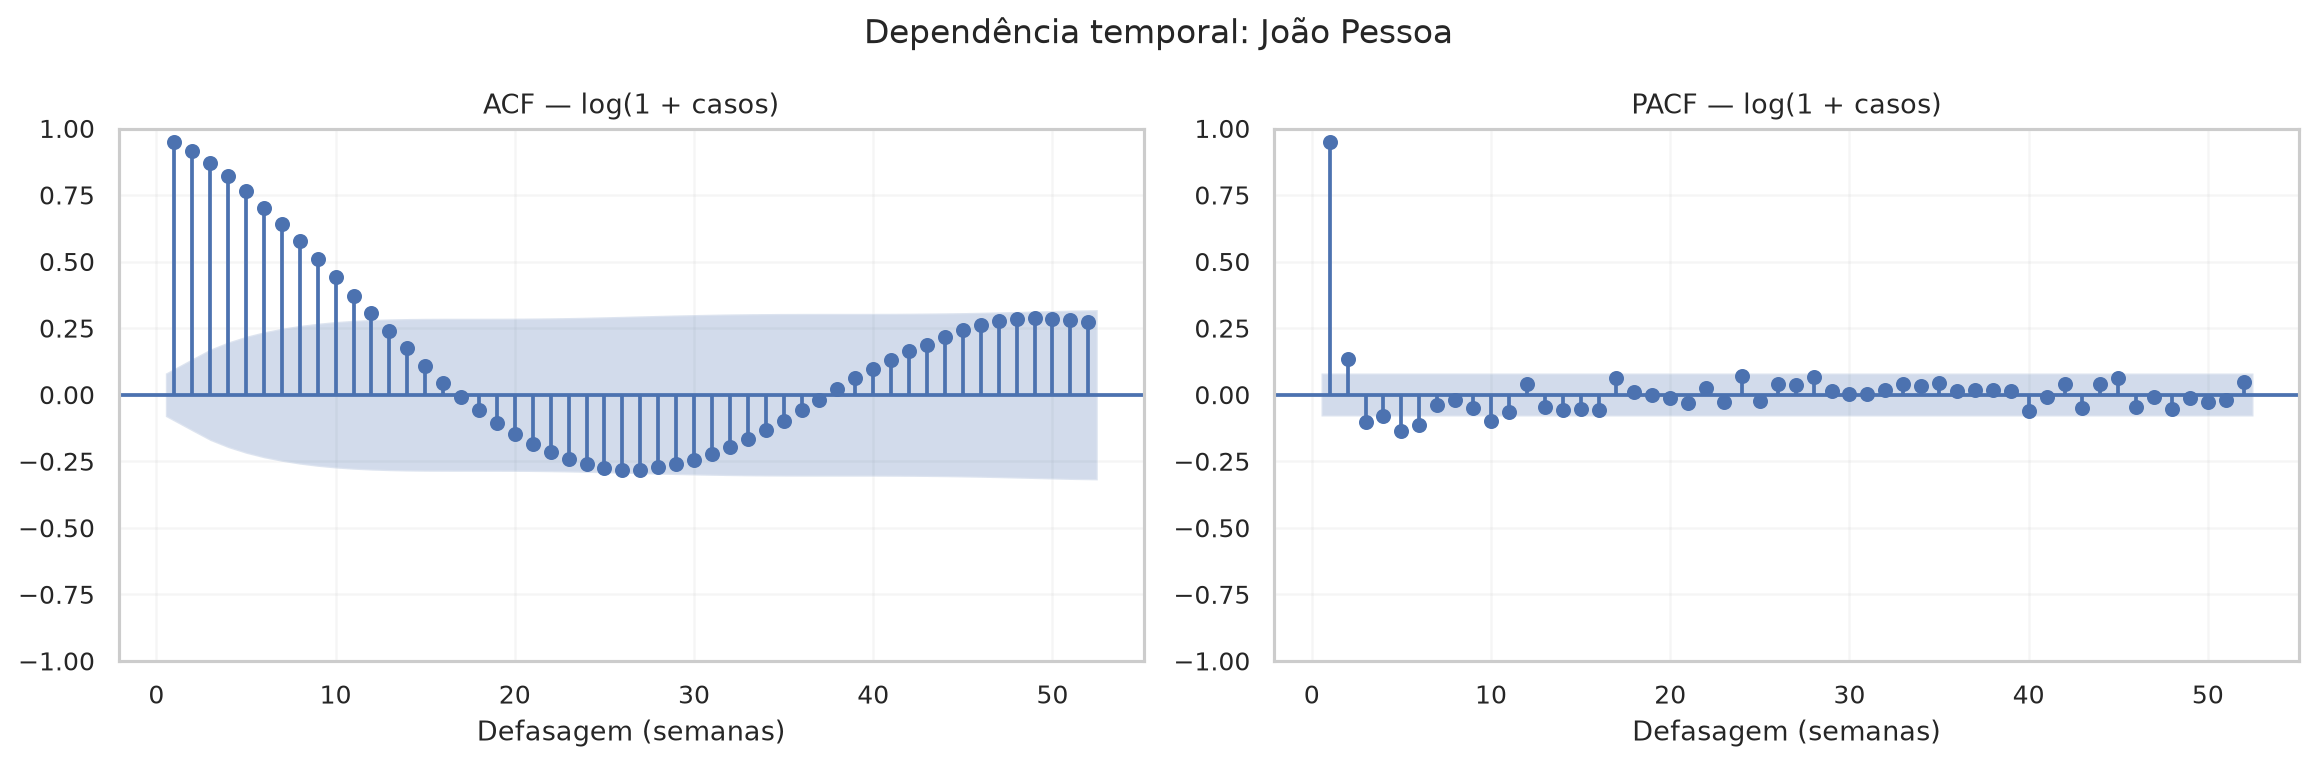

### acf_pacf_2611606.png

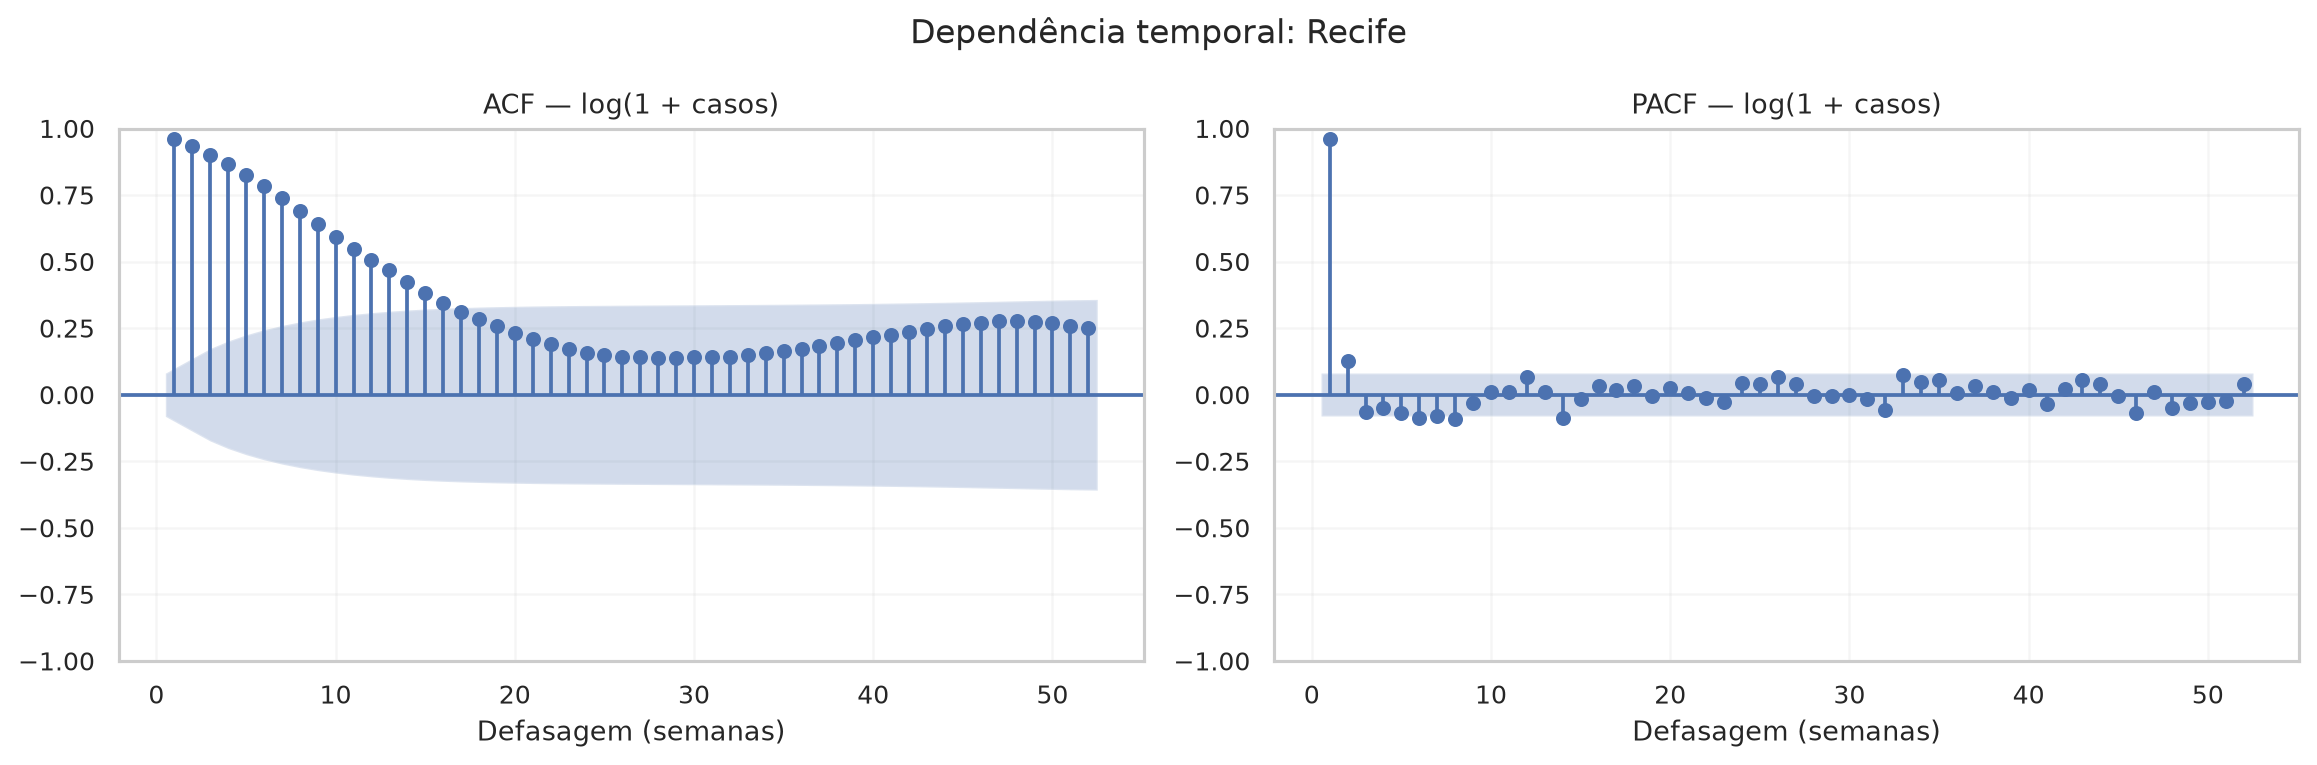

### acf_pacf_2704302.png

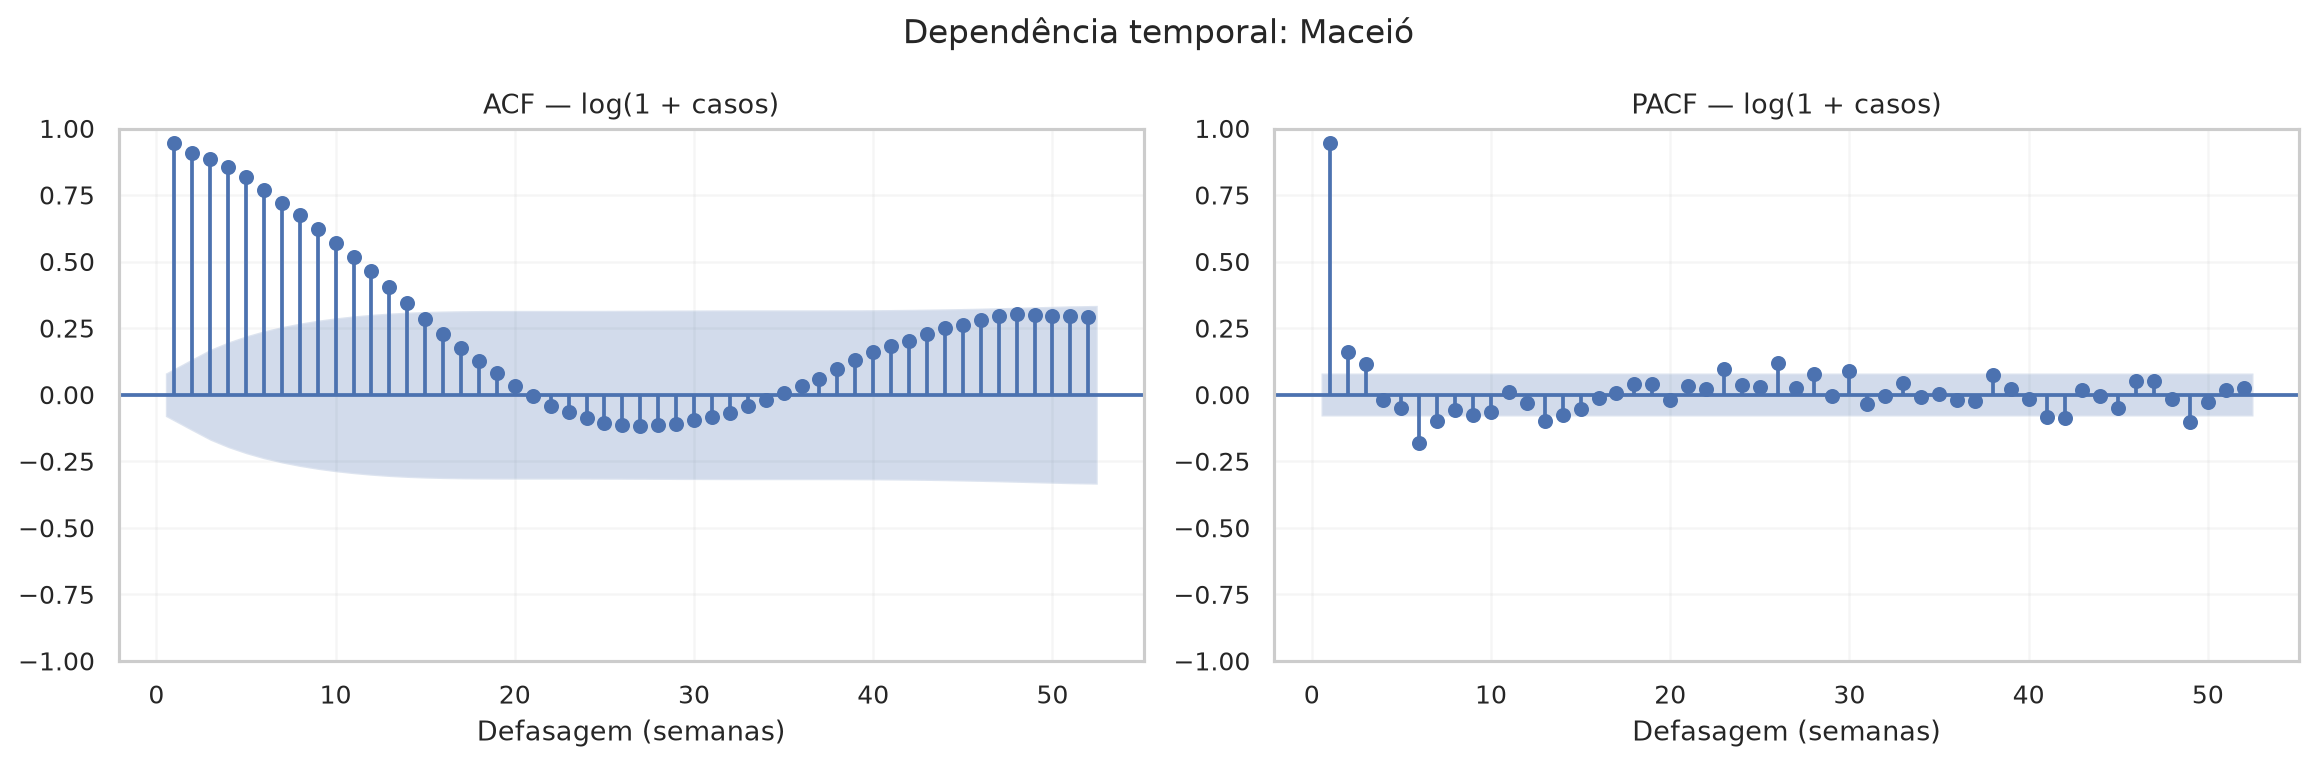

### acf_pacf_2800308.png

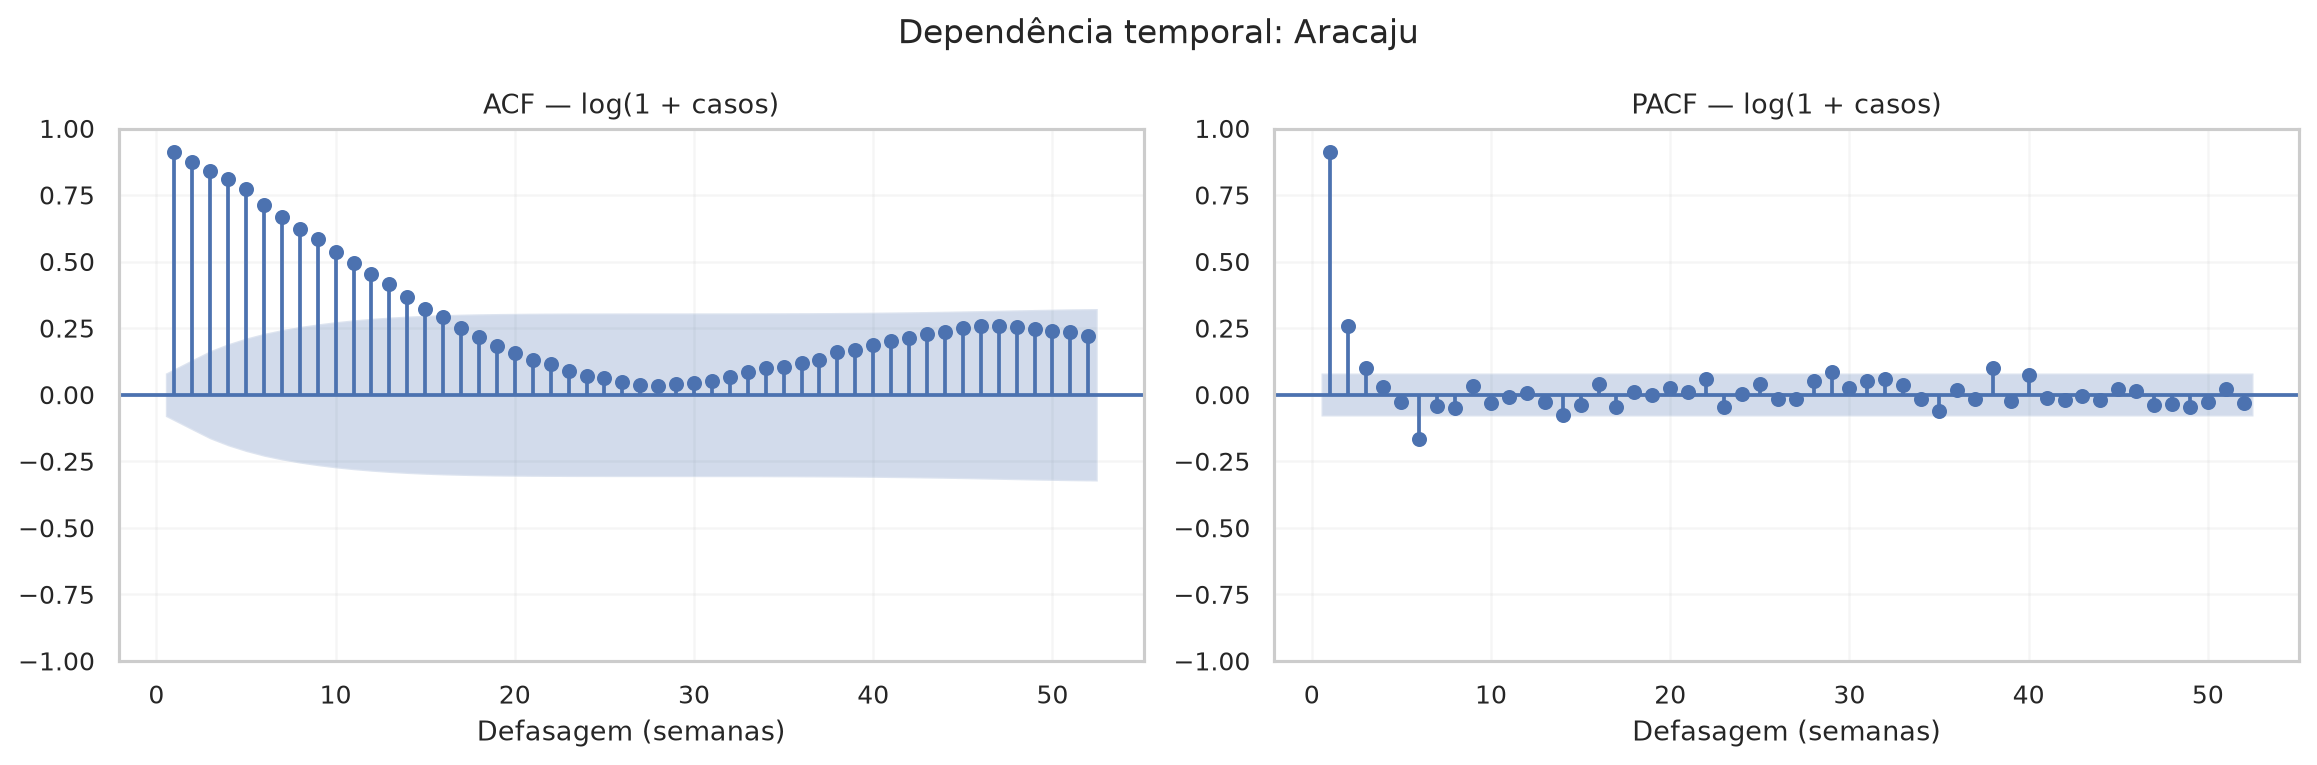

### acf_pacf_2927408.png

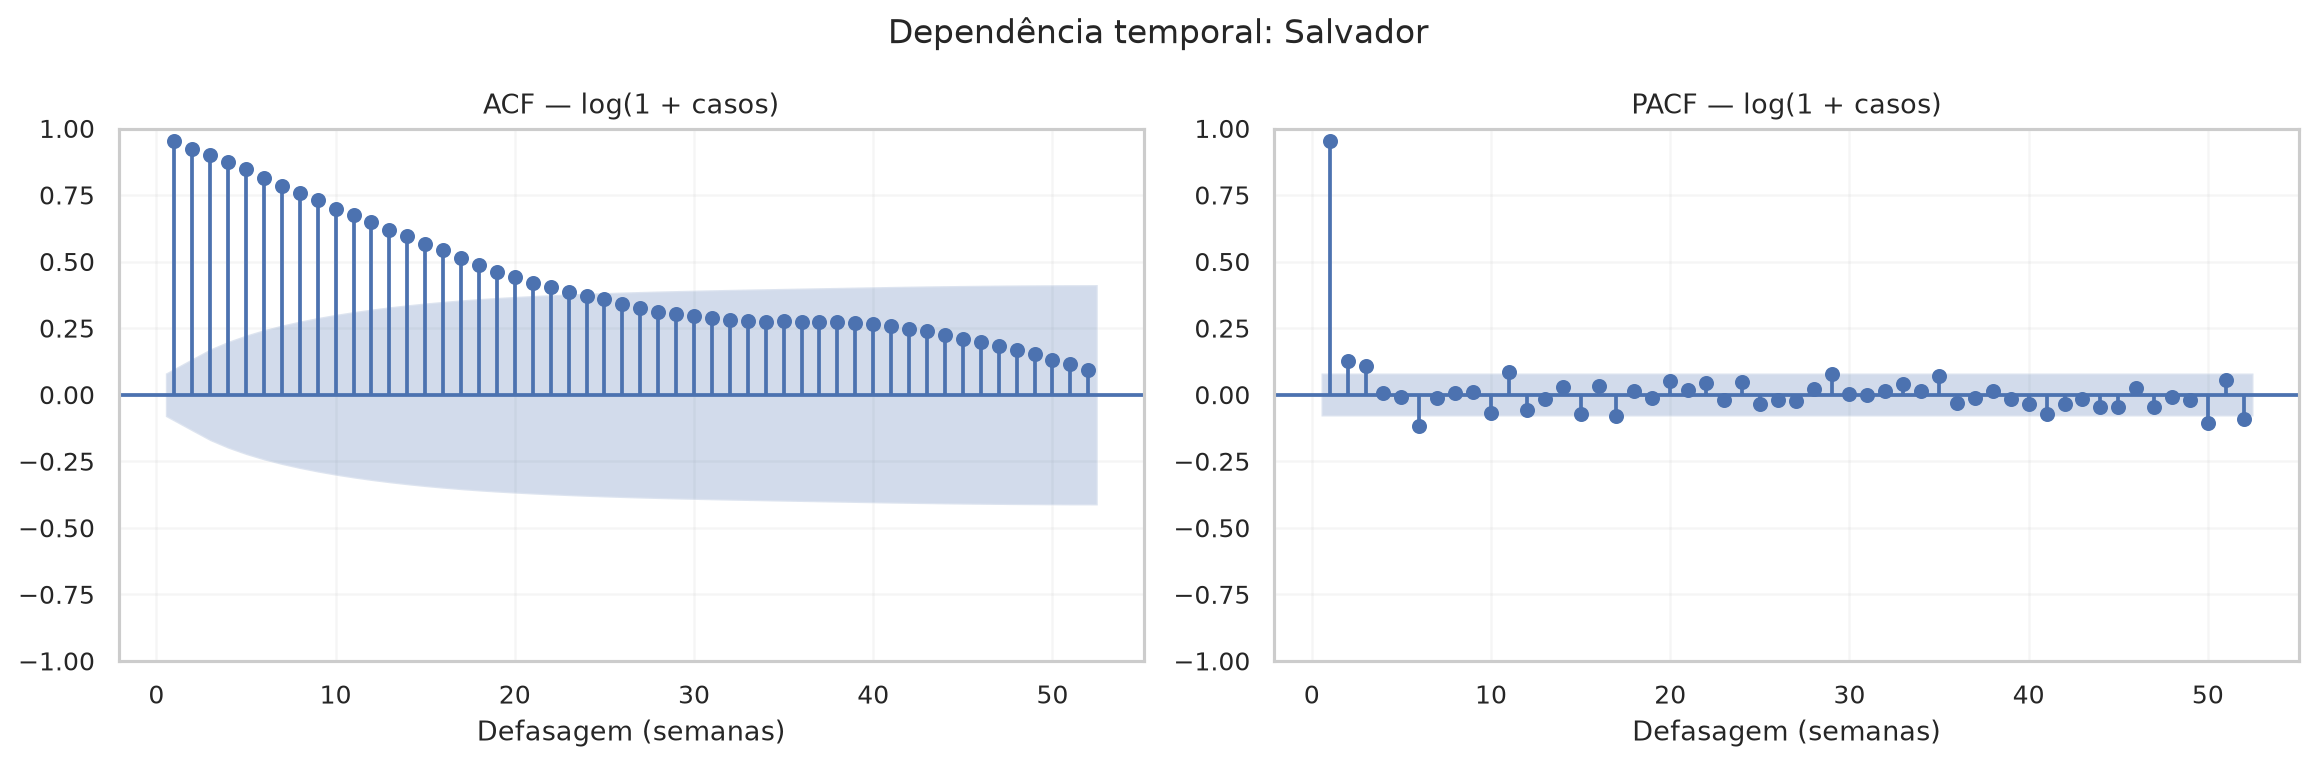

### stl_2111300.png

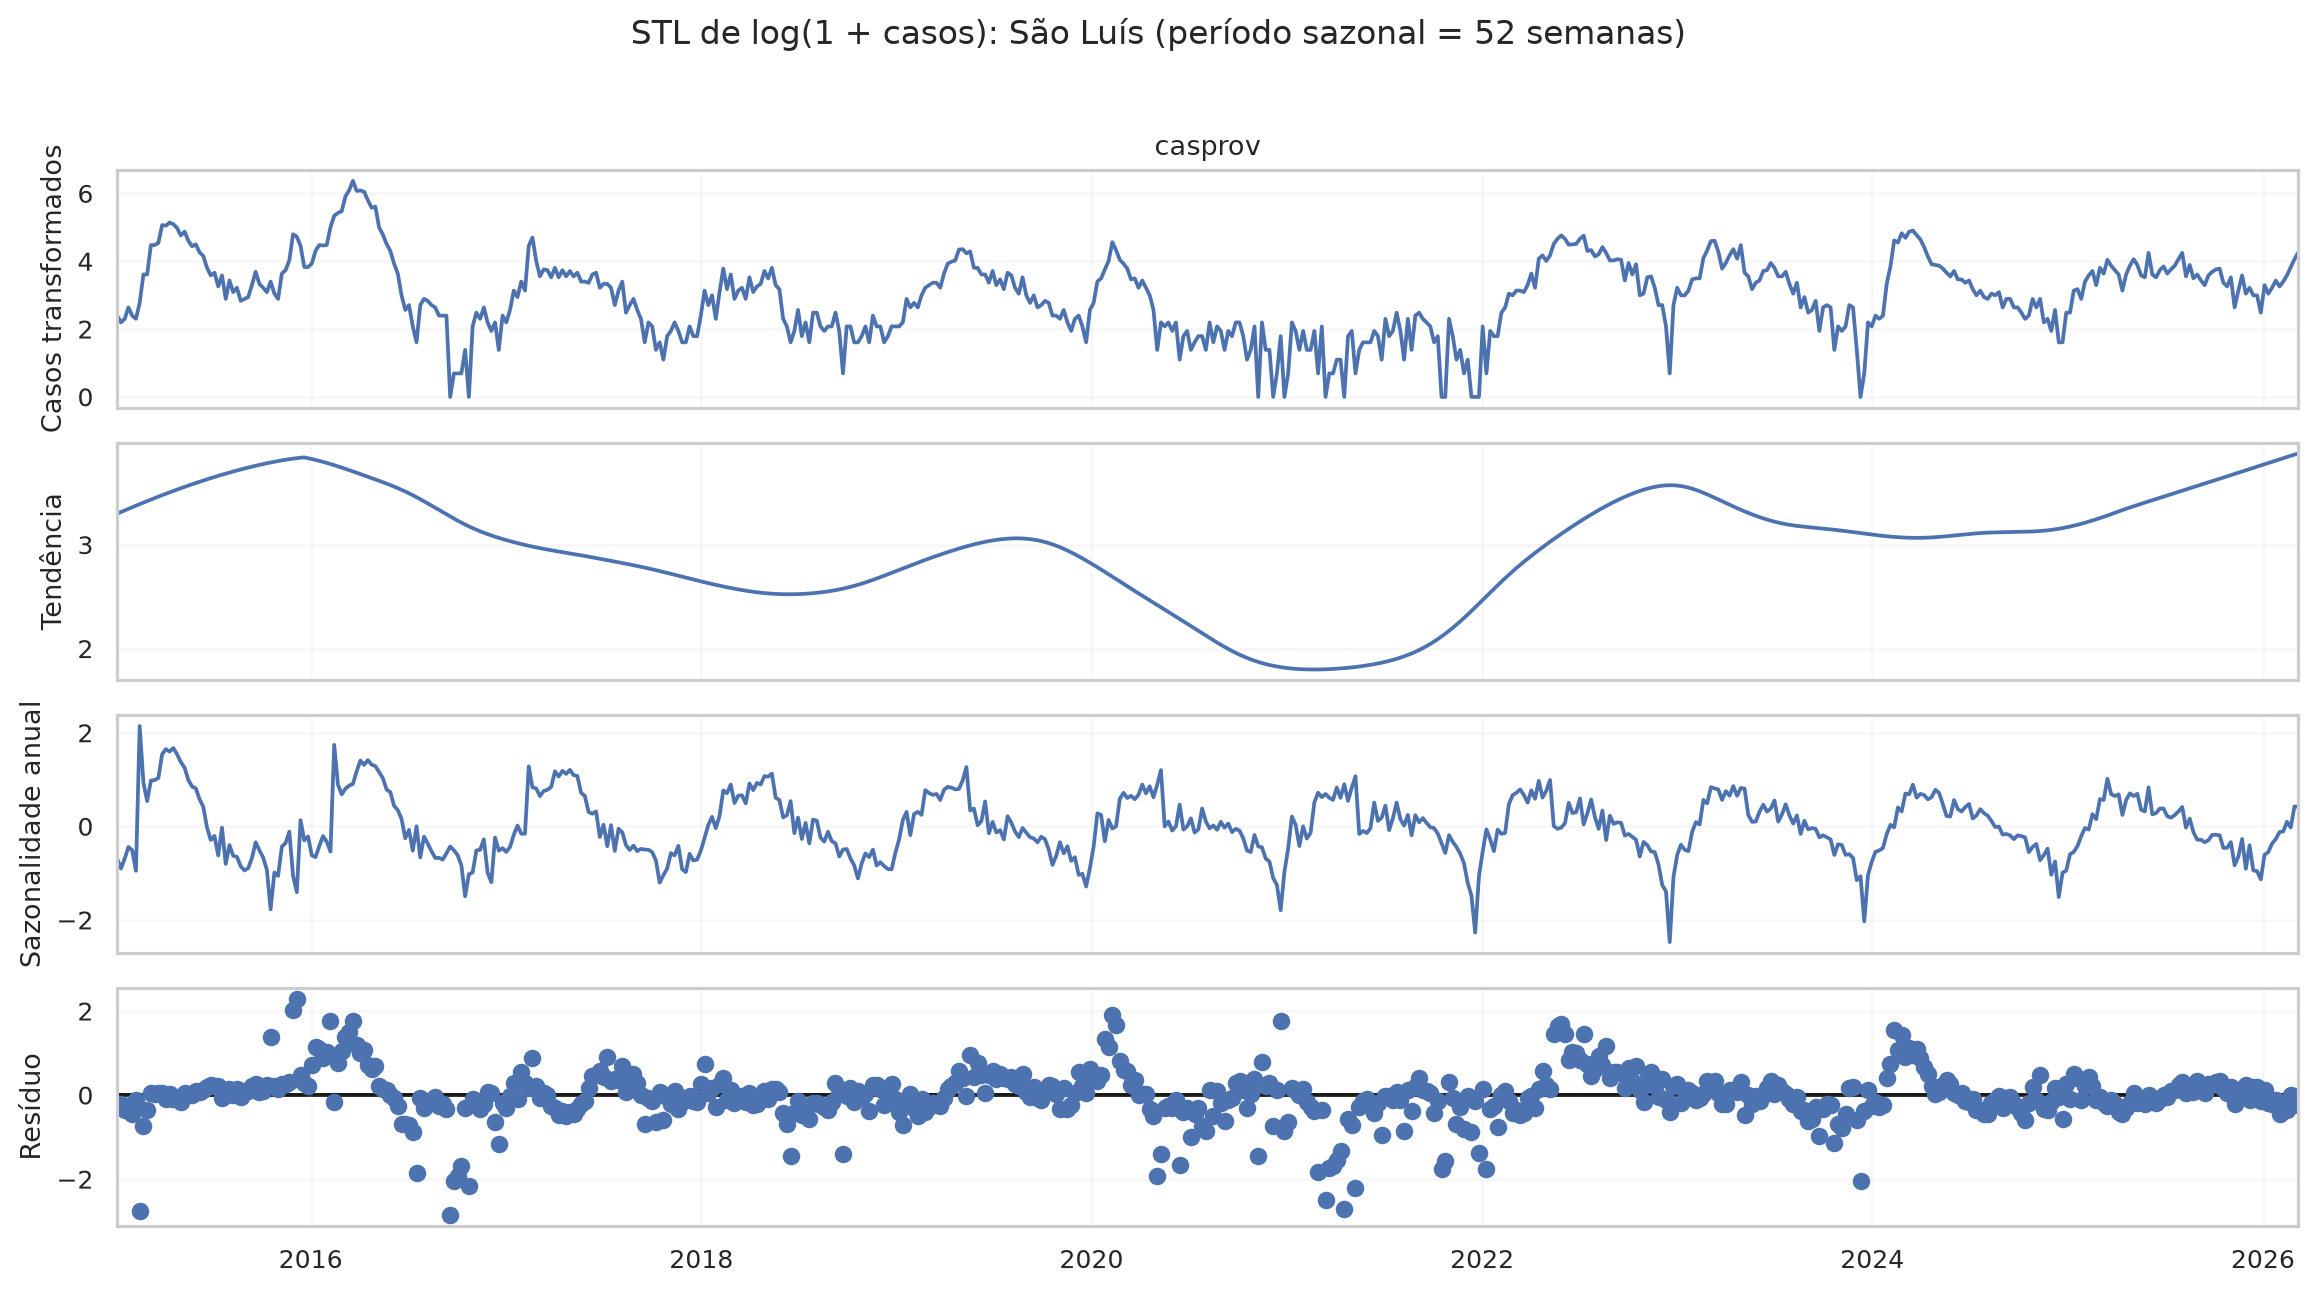

### stl_2211001.png

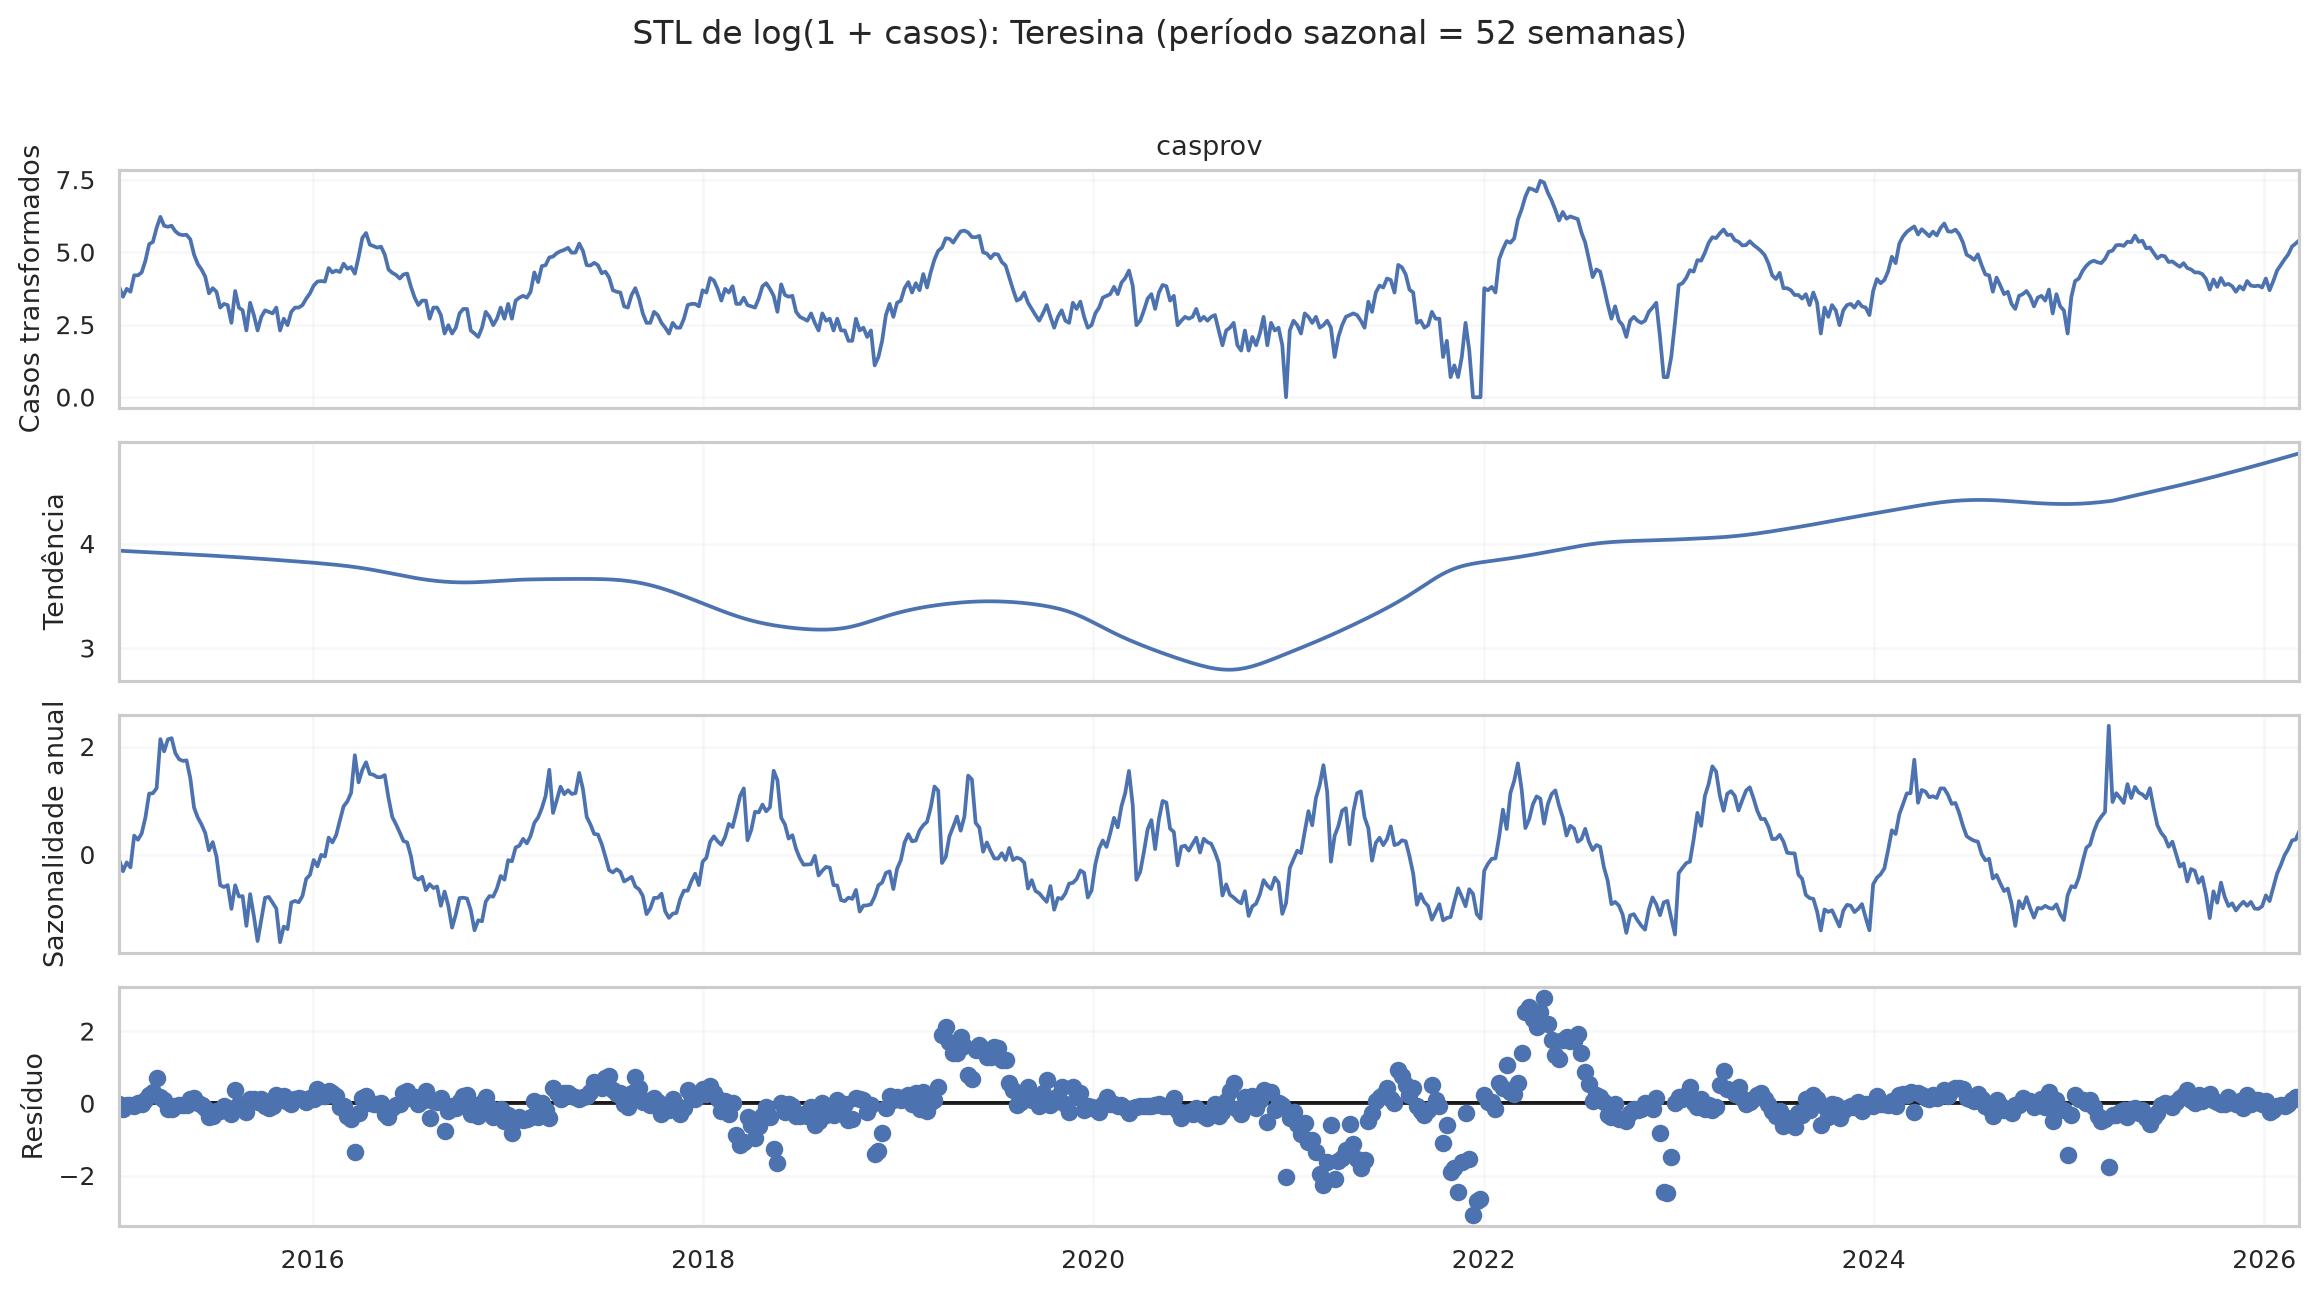

### stl_2304400.png

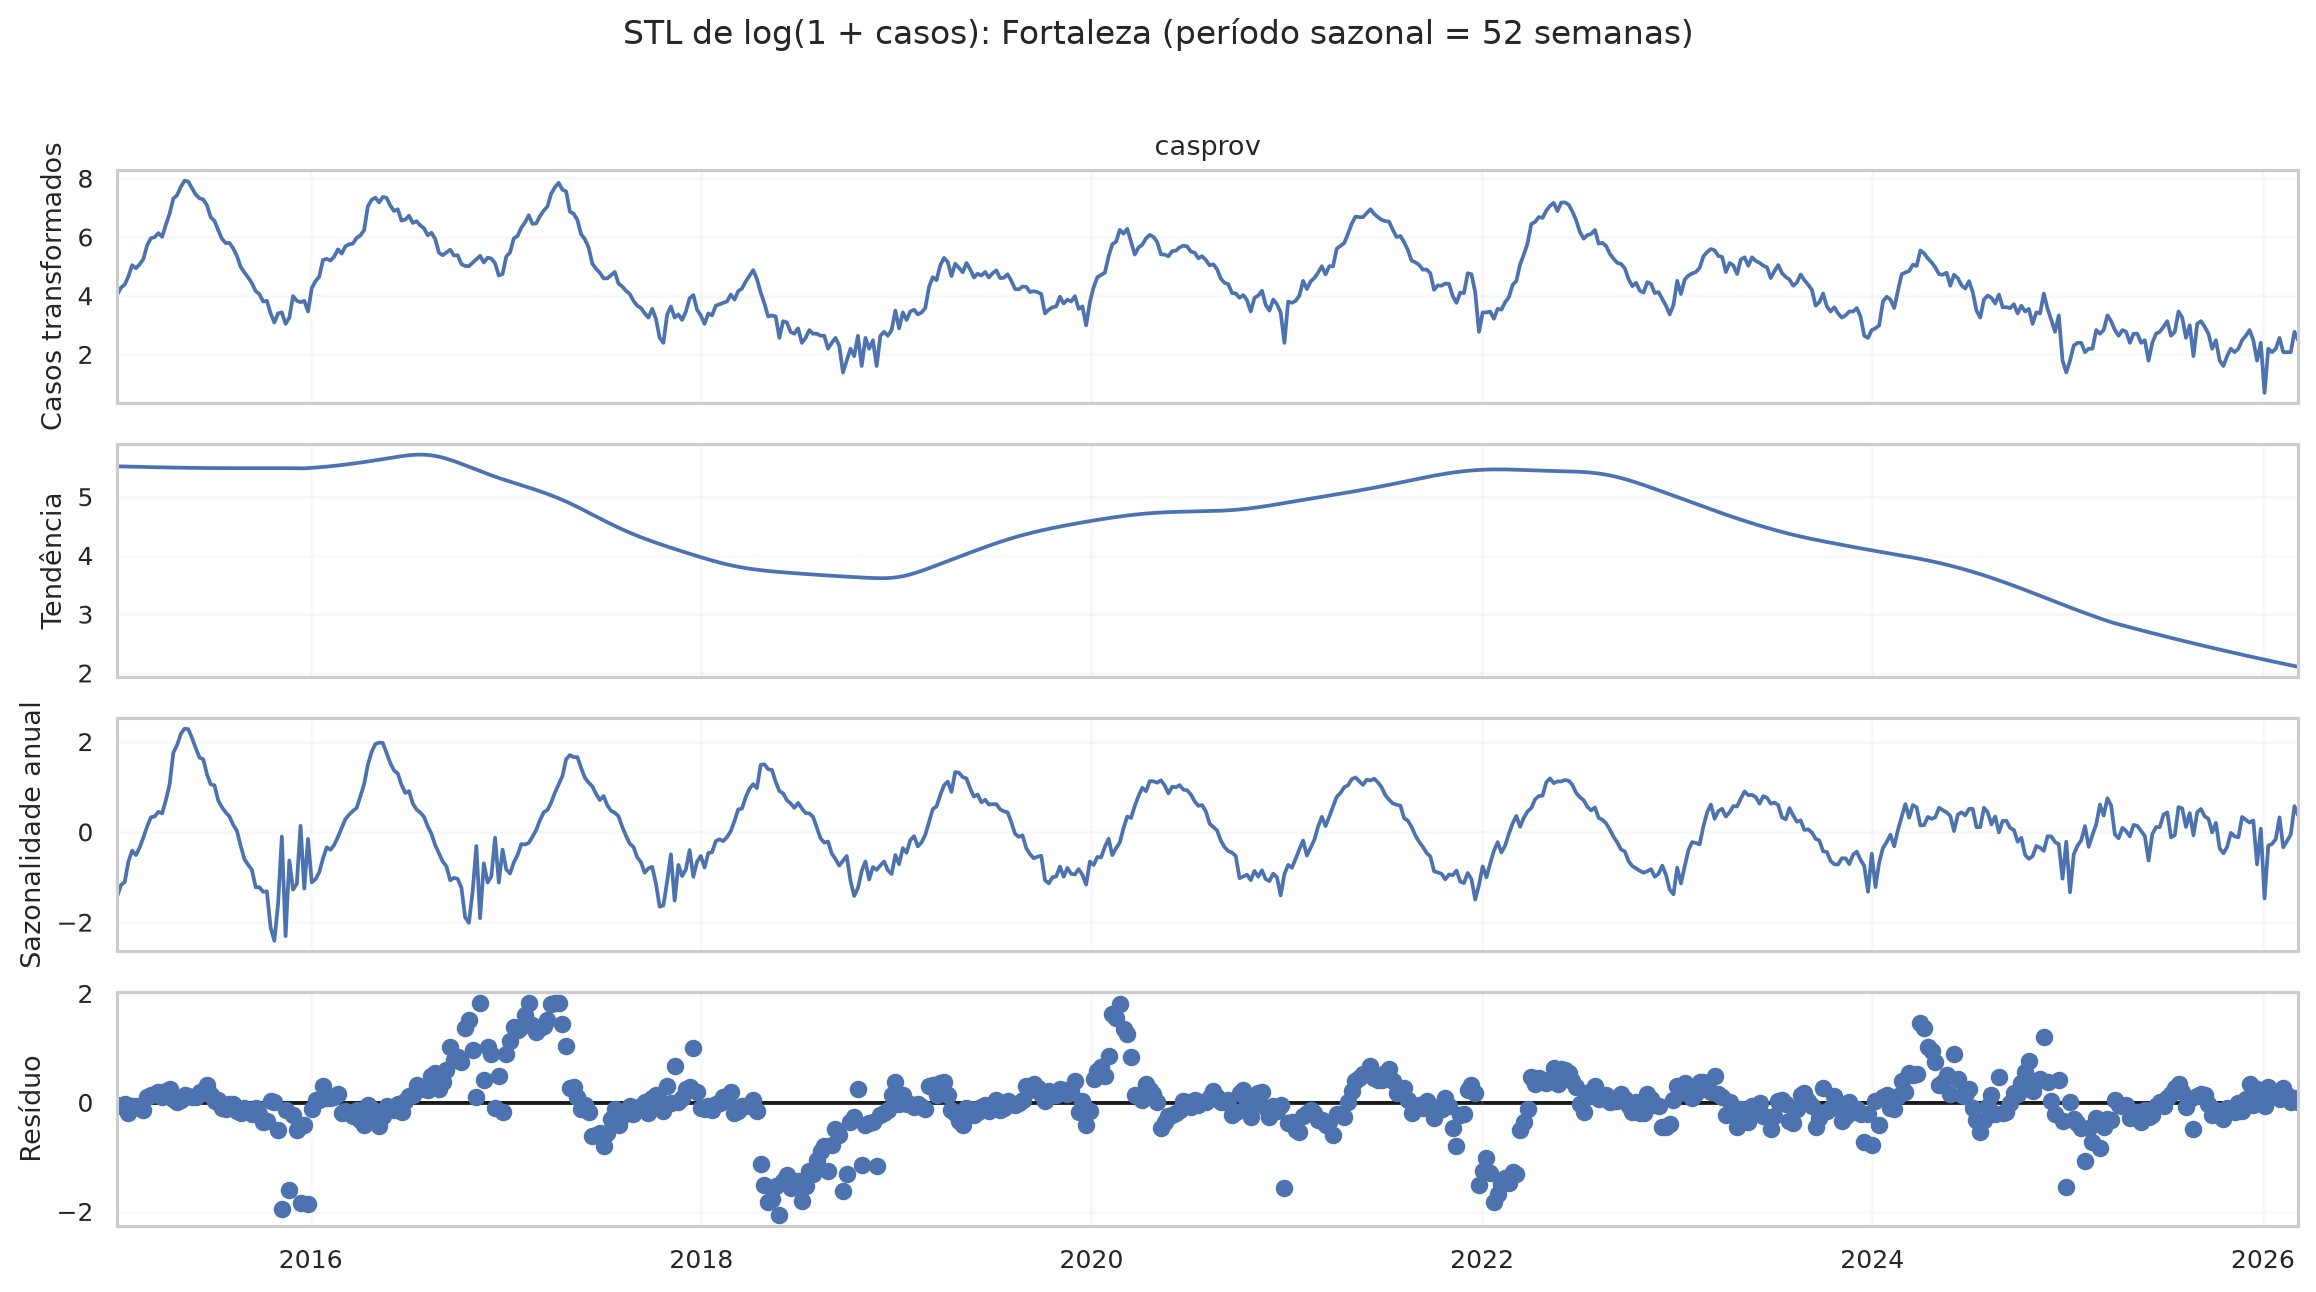

### stl_2408102.png

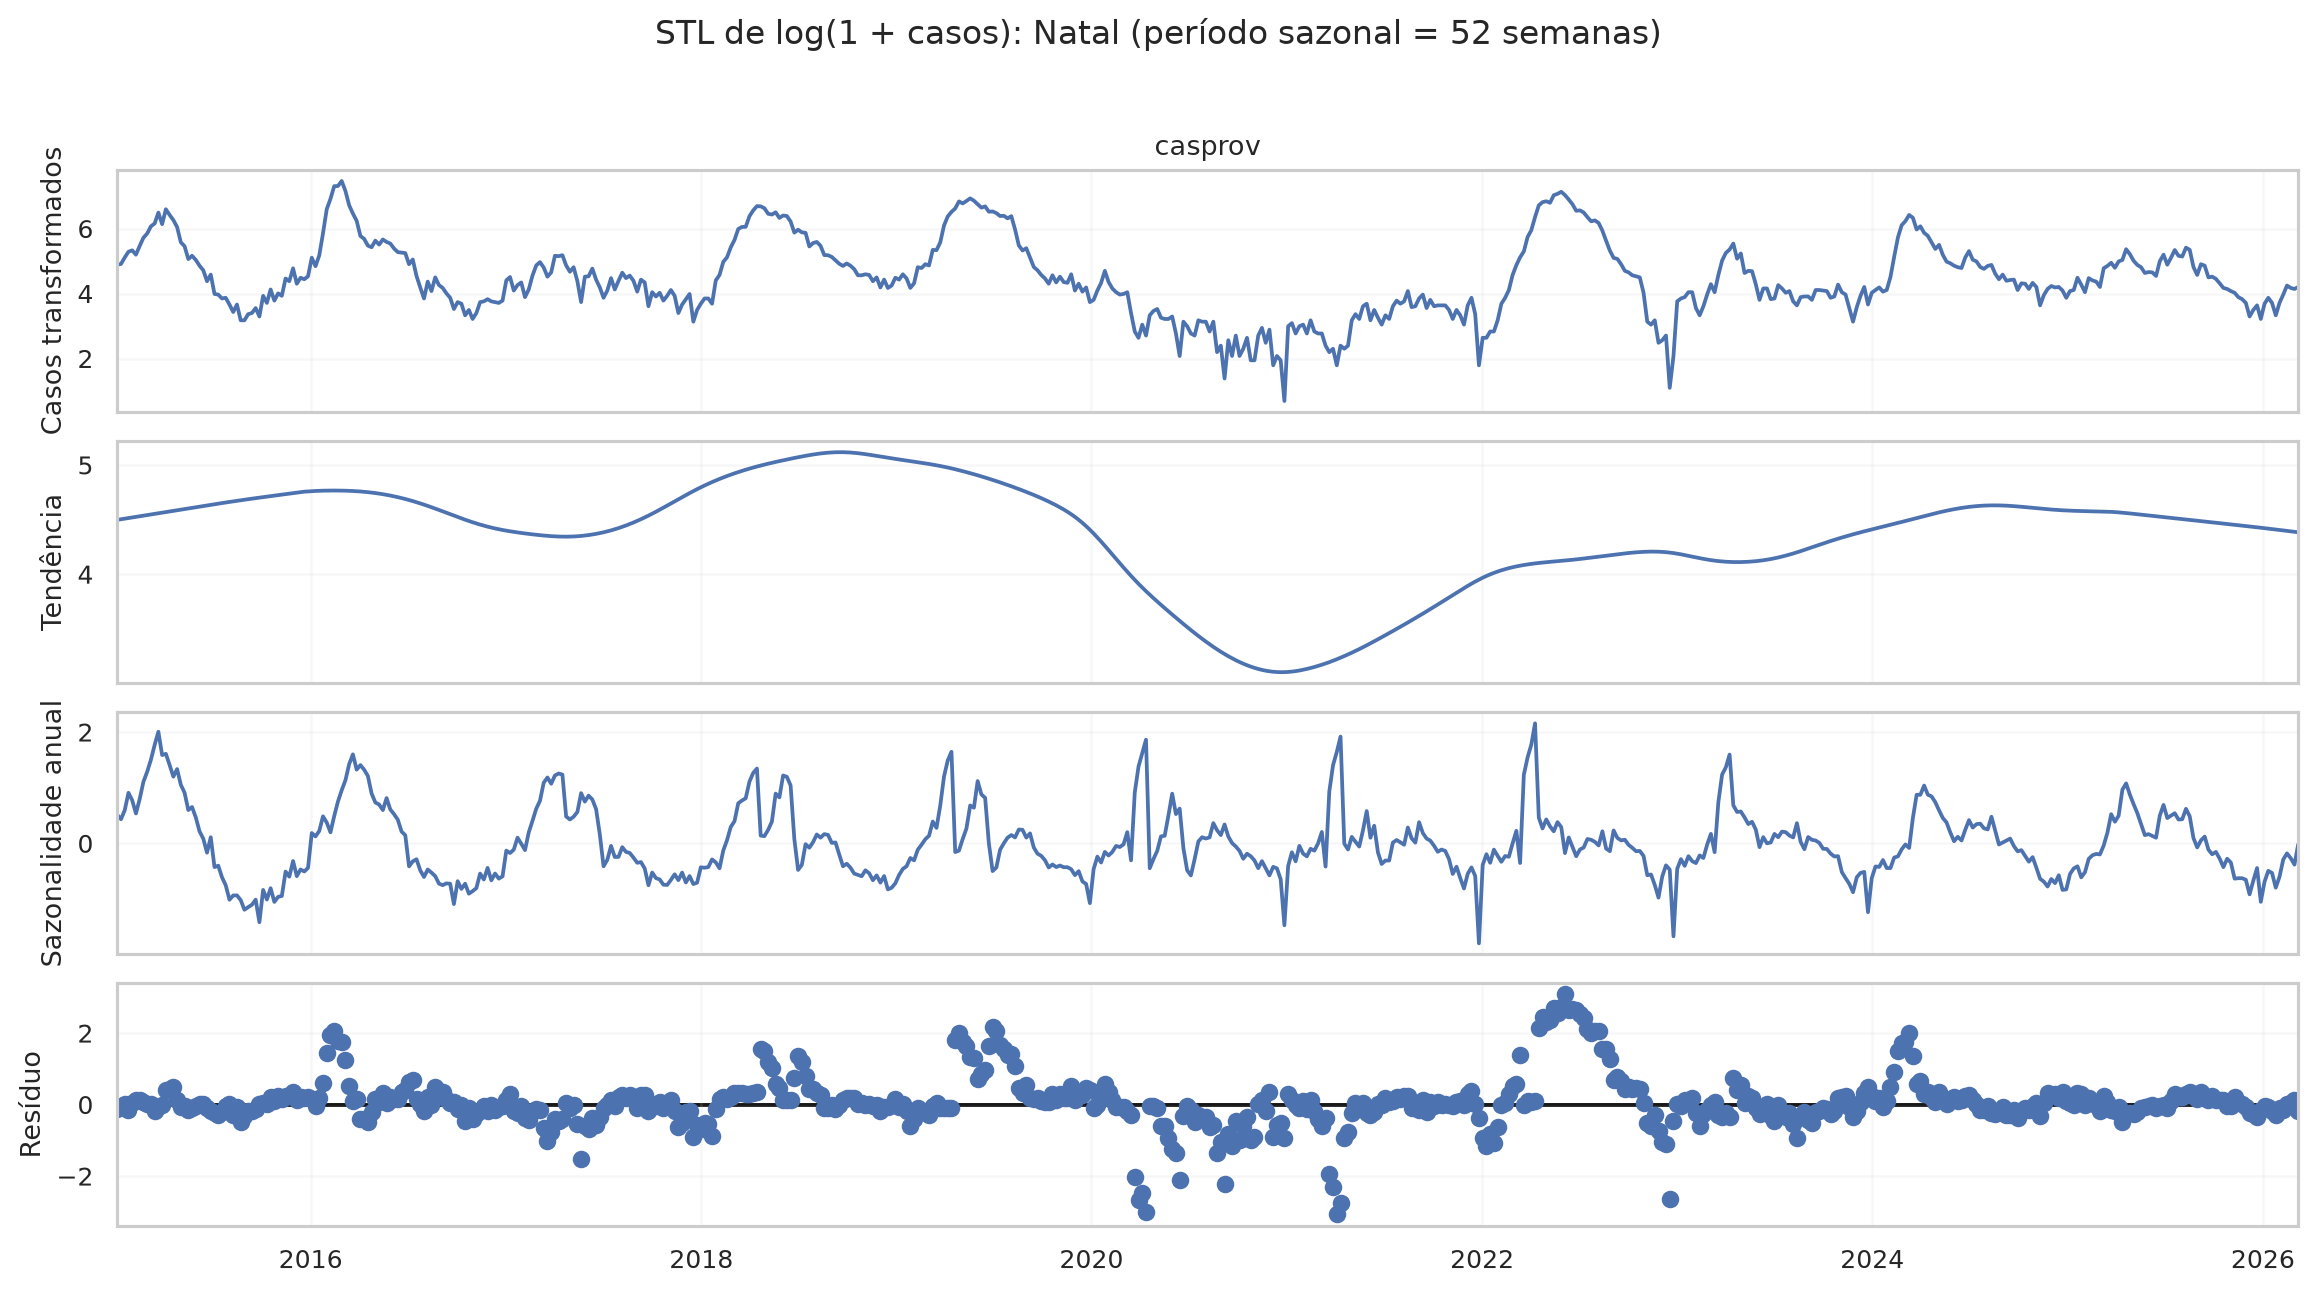

### stl_2507507.png

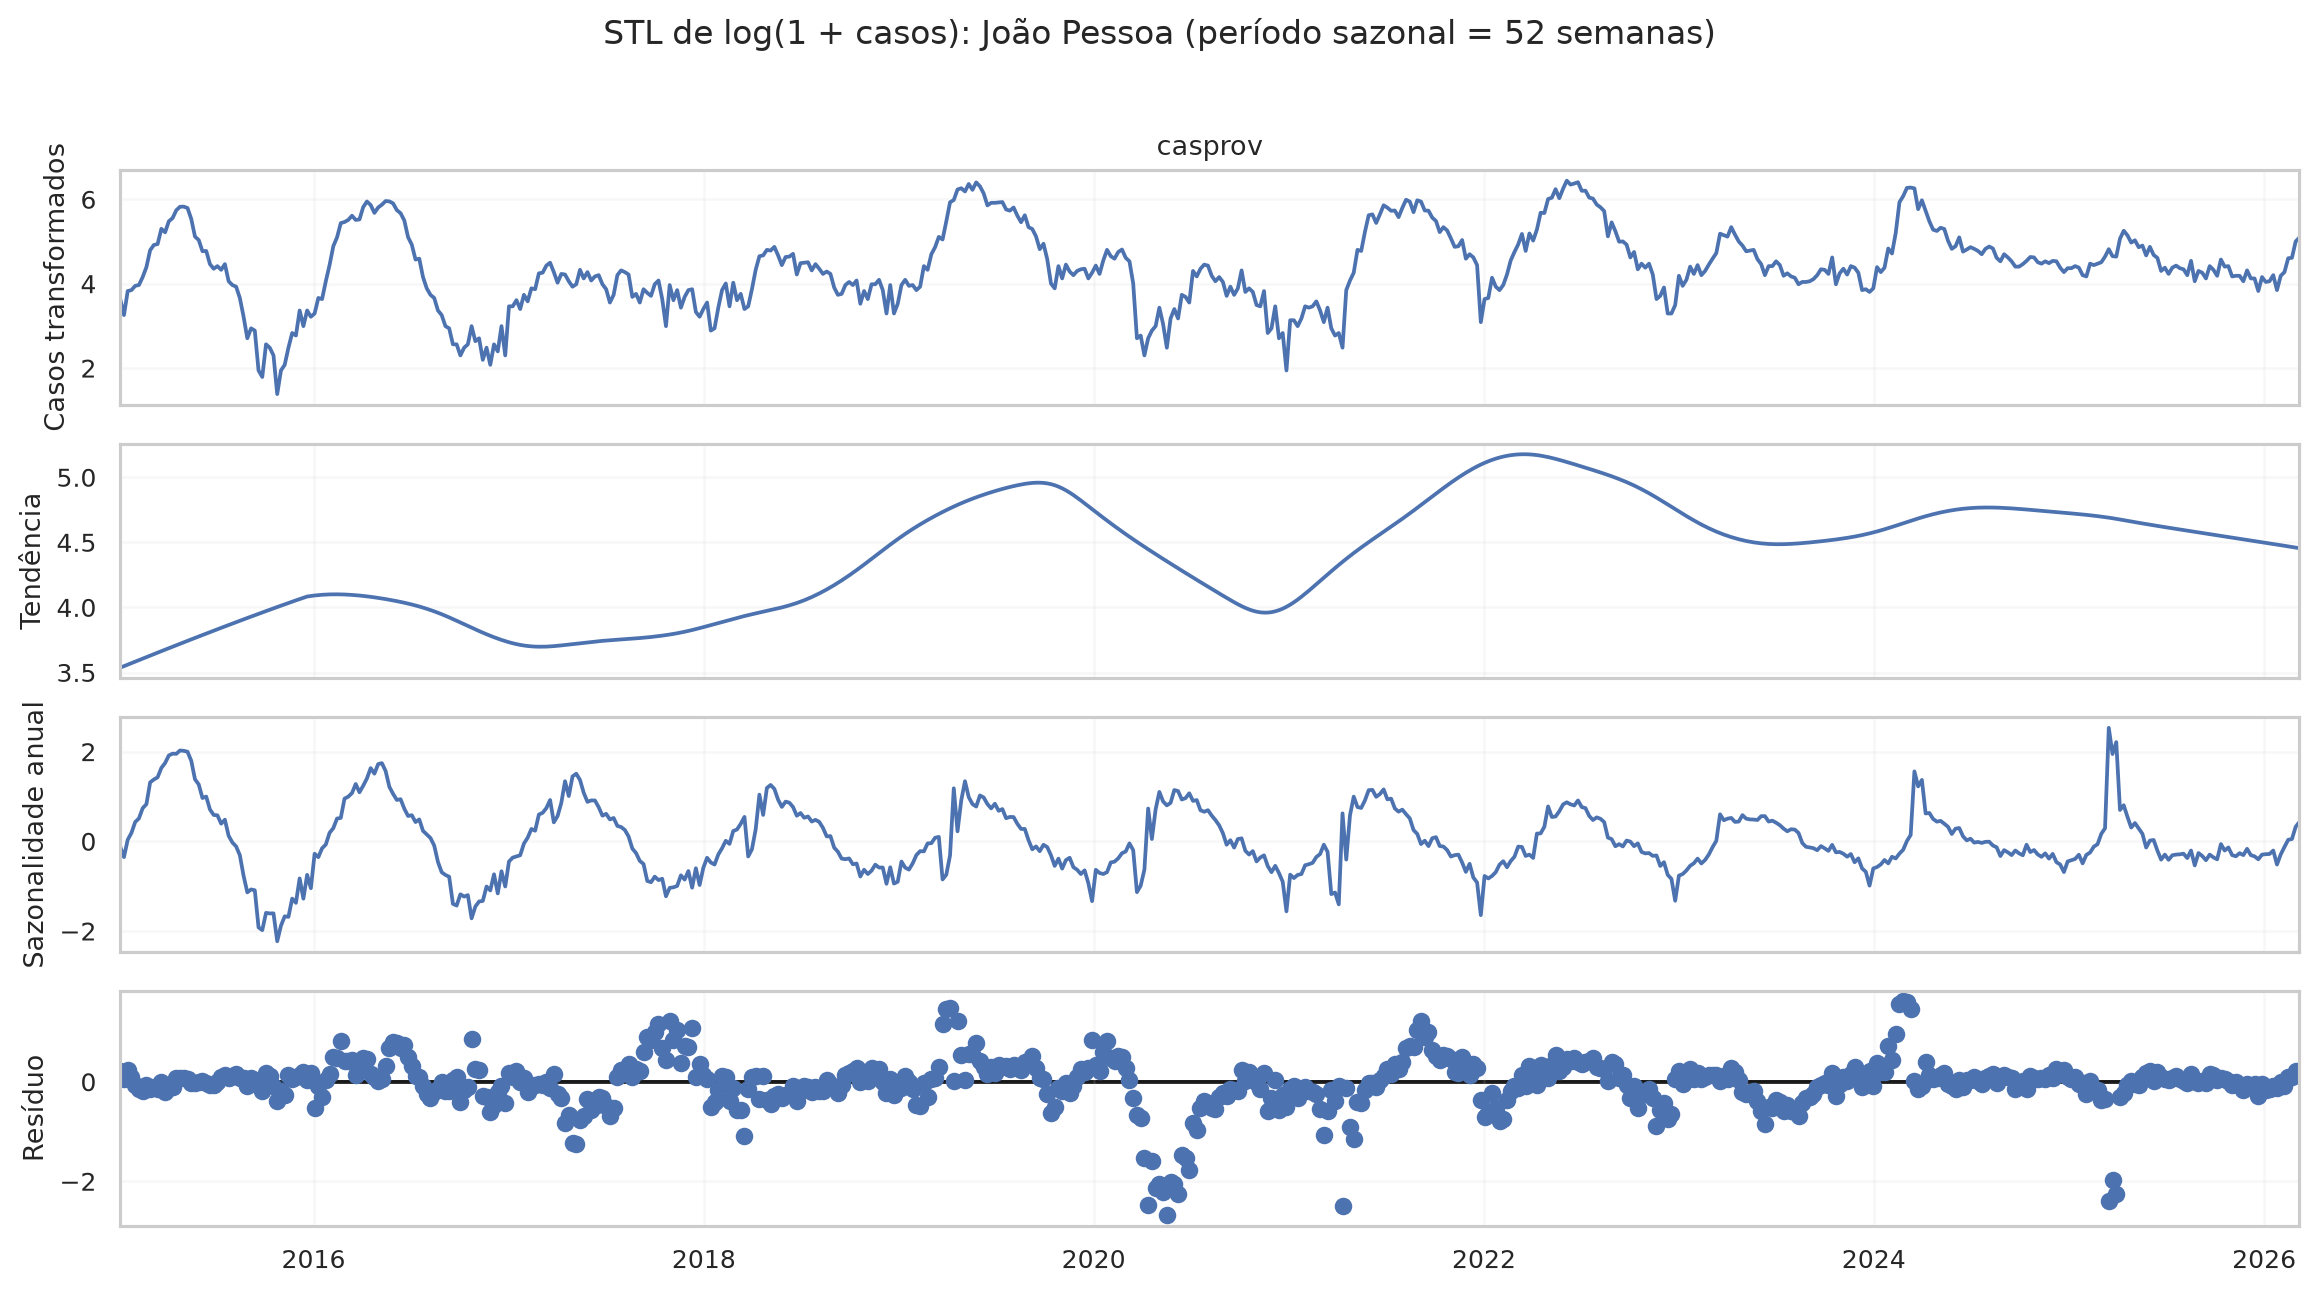

### stl_2611606.png

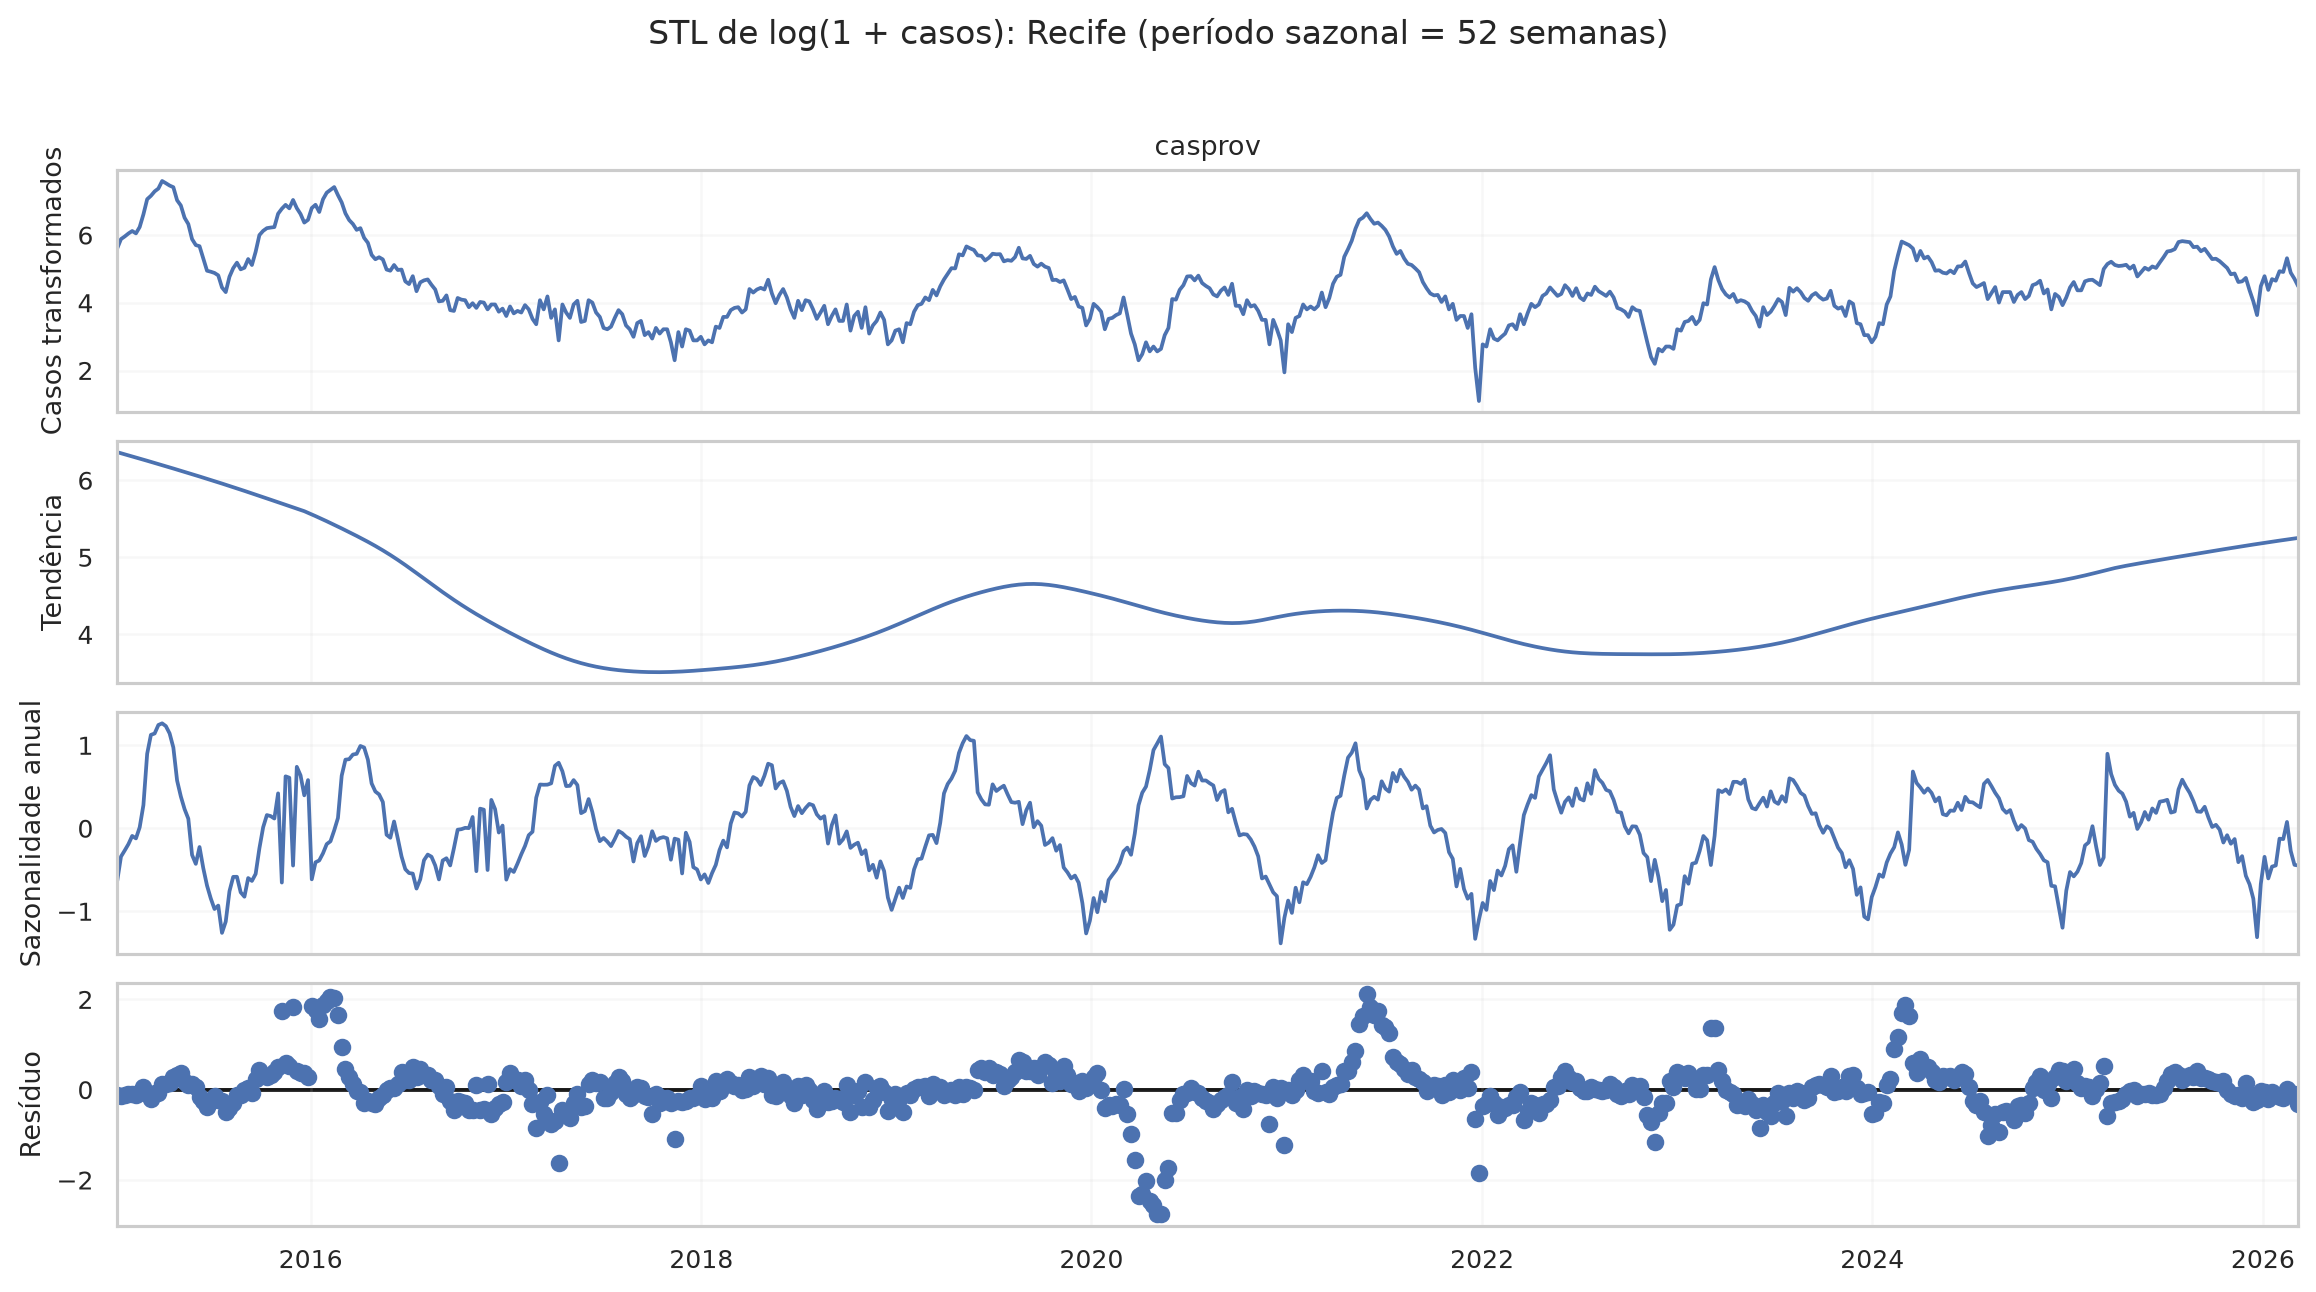

### stl_2704302.png

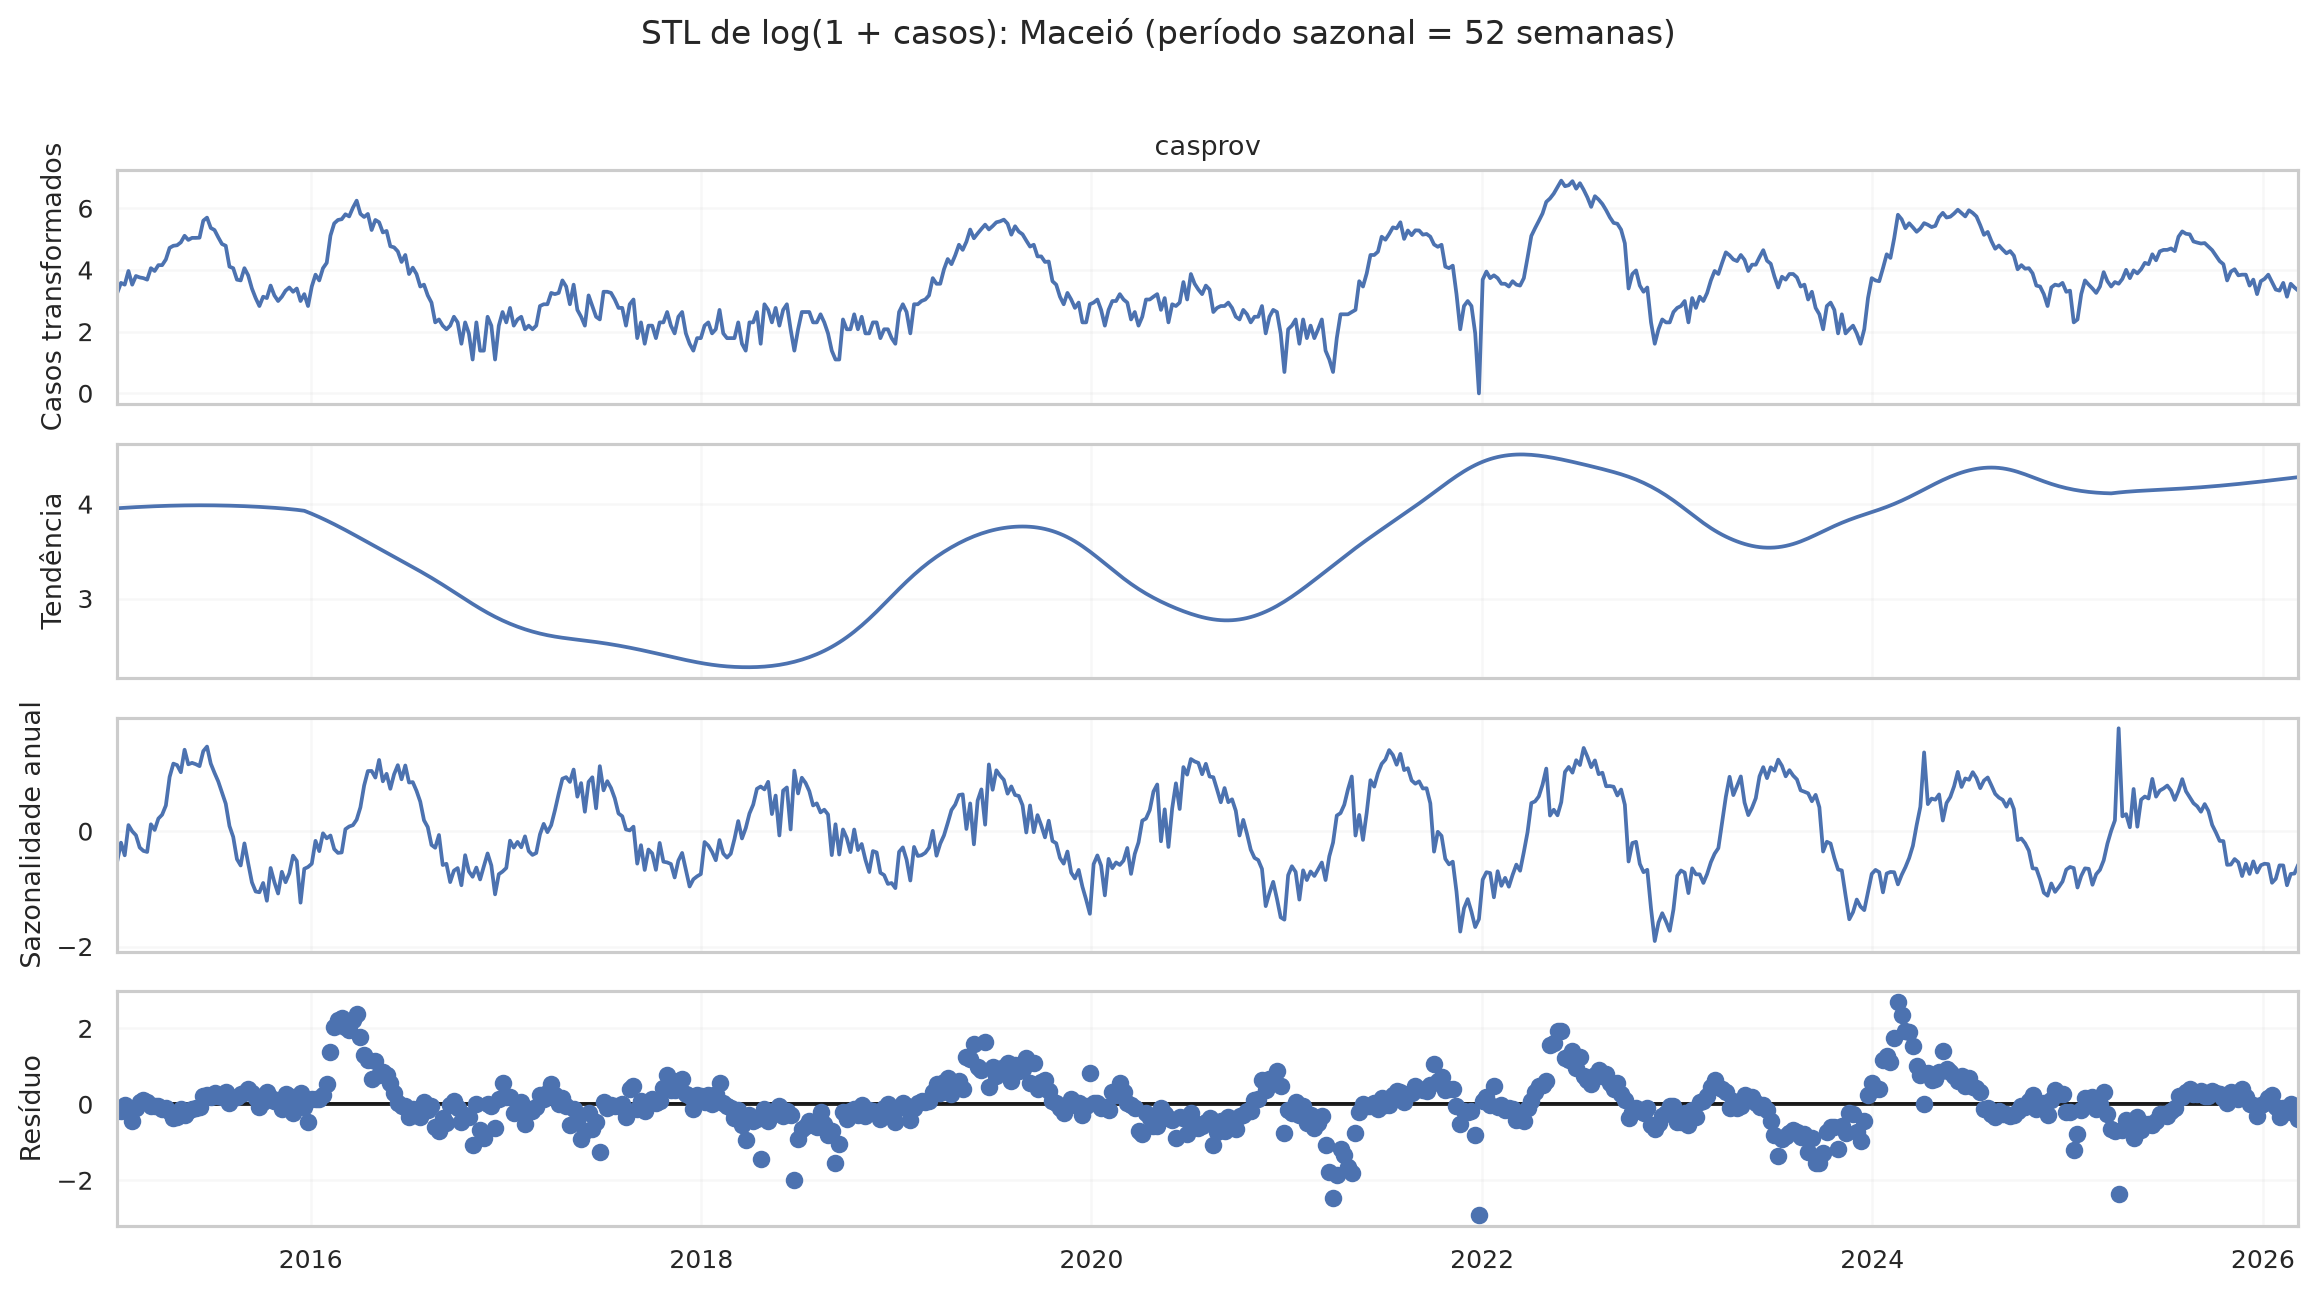

### stl_2800308.png

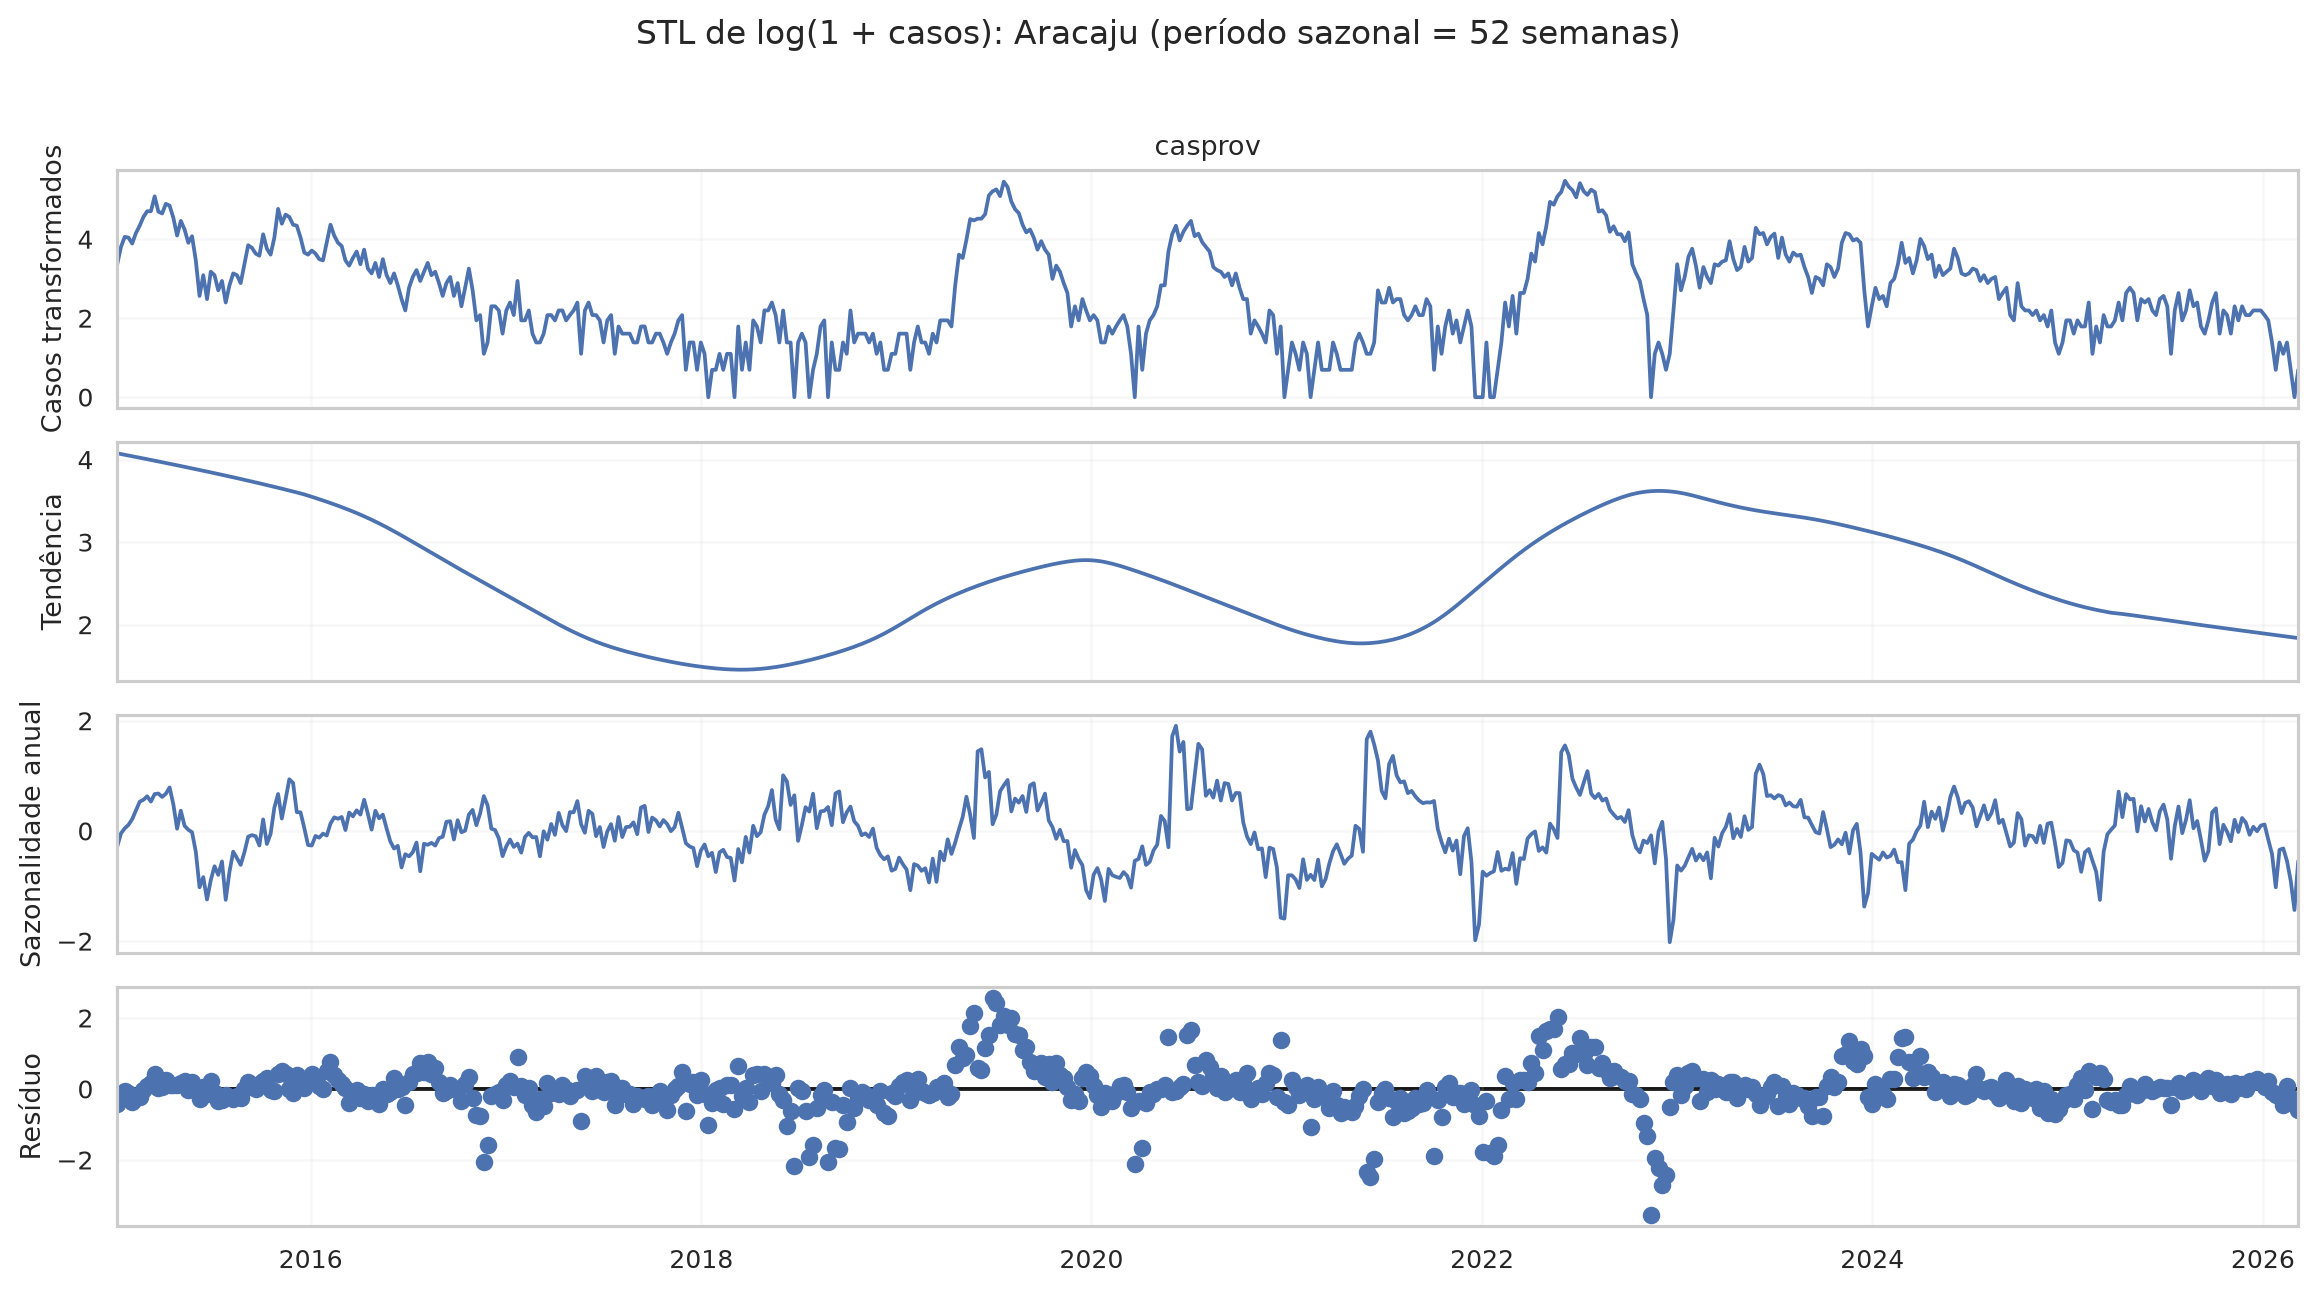

### stl_2927408.png

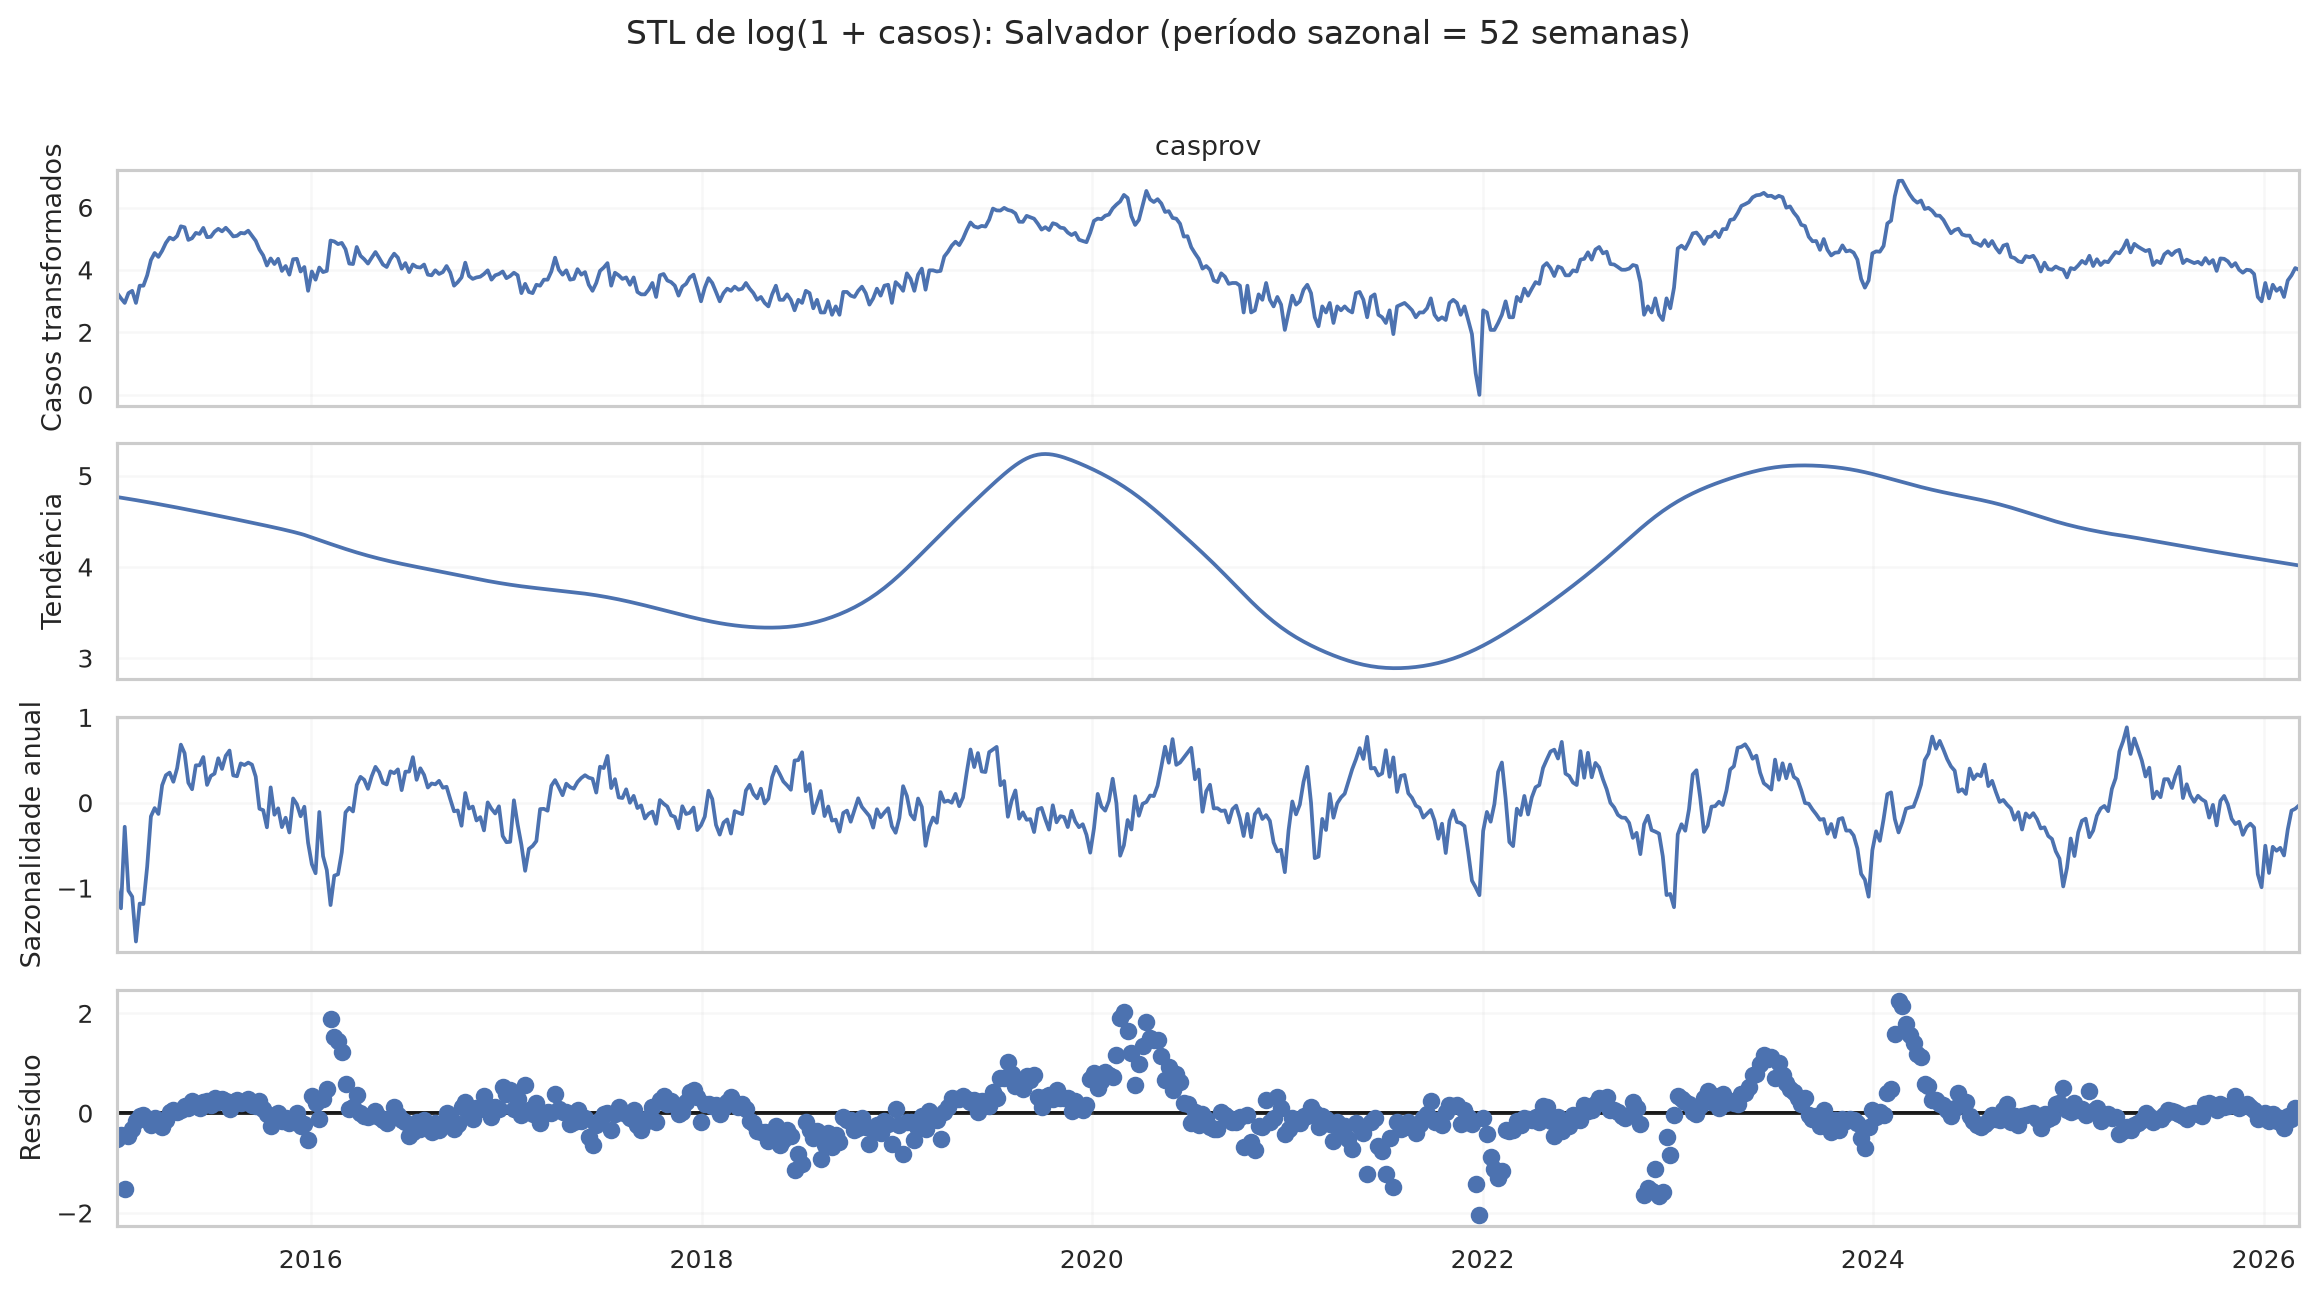

In [2]:
display(Markdown((OUT / 'interpretacao_eda.md').read_text(encoding='utf-8')))

for path in sorted((OUT / 'figures').glob('*.png')):
    display(Markdown(f'### {path.name}'))
    display(Image(filename=str(path), width=950))

## Tabelas para slides e relatório

Os CSVs usam UTF-8 com BOM para abrir com acentos corretamente em planilhas. São mostradas as principais linhas; todos os resultados ficam salvos na pasta `reports/eda_capitais/tables`.

In [3]:
tables = [
    'fontes_e_periodos.csv', 'dicionario_variaveis.csv', 'estatisticas_por_capital.csv', 'faltantes_por_variavel_capital.csv',
    'testes_estacionariedade.csv', 'stl_interpretacao.csv', 'interpretacao_graficos.csv',
    'correlacoes_por_capital.csv', 'ccf_resumo_medianas.csv', 'granger_por_capital.csv',
    'vif_por_capital.csv', 'decisao_variaveis_defasagens.csv', 'auditoria_versoes_casos.csv',
    'picos_sinalizados_para_revisao.csv'
]
for filename in tables:
    display(Markdown(f'### {filename}'))
    display(pd.read_csv(OUT / 'tables' / filename).head(30))

### fontes_e_periodos.csv

,conjunto,origem,frequencia,periodo,documentacao_acesso,observacoes
0,casos e atributos epidemiológicos,"SINAN/IBGE, organizado por InfoDengue/Mosqlimate",semanal por município,2010–2026 (base do pacote); esta análise 2015-...,https://sprint.mosqlimate.org/data/,Pacote público 3rd IMDC 2026; `casprov` usado ...
1,casos prováveis e níveis MEM,InfoDengue,semanal por município,2015–2026 na extração local,https://info.dengue.mat.br/services/api,Consulta pública por código IBGE; `nivel_inc =...
2,variáveis climáticas,"ERA5/Copernicus, organizado por Mosqlimate",semanal por município,1999–2026 (pacote); recorte da análise 2015-01...,https://sprint.mosqlimate.org/data/,Reanálise horária agregada por dia e depois po...
3,população,DATASUS/SVS,anual por município,2001–2025; último ano conhecido carregado para...,https://sprint.mosqlimate.org/data/,Usada para calcular incidência sem recorrer a ...
4,API datastore,Mosqlimate,consulta paginada,acesso verificado em 2026-11-09,https://api.mosqlimate.org/docs/uid-key,Exige chave de usuário; não foi necessária par...


### dicionario_variaveis.csv

,variavel,descricao,fonte,unidade,frequencia,uso_observacoes
0,geocode,Código municipal IBGE,IBGE/InfoDengue,código municipal,município,Identificador da capital
1,date,Início da semana epidemiológica (domingo),InfoDengue/Mosqlimate,data,semanal,Chave temporal
2,casprov,Casos prováveis semanais; suspeitos menos desc...,InfoDengue (SINAN/IBGE),casos,semanal,Alvo principal
3,casos_arquivo,Casos prováveis da série histórica pública par...,"InfoDengue/Mosqlimate, dengue.csv.gz",casos,semanal,"Comparação de versões, não substitui silencios..."
4,incidencia_100mil,Casos por 100 mil habitantes,Calculada: casos/população × 100.000,casos/100 mil hab.,semanal,Medida auxiliar para pergunta de limiar
5,nivel_inc_mem,Nível MEM de incidência; 2 acima do limiar epi...,InfoDengue/MEM,nível categórico,semanal,Indicador de contexto/evento
6,surto_mem,Indicador de incidência acima do limiar MEM,InfoDengue/MEM,0/1,semanal,1 quando nível MEM é 2
7,population,"População municipal estimada, último ano conhe...","DATASUS/SVS, pacote público 3rd IMDC",habitantes,"anual, carregada para frente",Não usa população futura
8,temp_med,Temperatura média semanal,"ERA5/Copernicus, organizada por Mosqlimate",°C,semanal,Média de dados horários resumidos por semana
9,precip_med,Taxa média semanal de precipitação,"ERA5/Copernicus, organizada por Mosqlimate",mm/h,semanal,Não é precipitação total semanal


### estatisticas_por_capital.csv

,geocode_ibge,municipio,inicio,fim,n_semanas,casos_media,casos_mediana,casos_desvio_padrao,casos_p90,casos_p95,...,incidencia_media_100mil,populacao_mediana,temp_med_media,temp_med_desvio_padrao,precip_med_media,precip_med_desvio_padrao,rel_humid_med_media,rel_humid_med_desvio_padrao,rainy_days_media,rainy_days_desvio_padrao
0,2111300,São Luís,2015-01-04,2026-03-08,584,35.989726,21.0,57.129985,82.0,111.55,...,3.351756,1080699.0,27.128049,0.854767,21.126674,26.449809,79.406201,5.886983,6.984589,0.148528
1,2211001,Teresina,2015-01-04,2026-03-08,584,95.352740,37.0,175.895598,240.4,310.95,...,10.716665,887077.0,28.096886,1.901991,12.807478,21.480486,65.841346,16.723107,5.351027,2.279388
2,2304400,Fortaleza,2015-01-04,2026-03-08,584,232.926370,84.0,397.010259,680.2,1034.40,...,9.090919,2574412.0,26.809008,0.625400,12.740968,17.070969,76.668838,6.858330,6.717466,0.820390
3,2408102,Natal,2015-01-04,2026-03-08,584,172.592466,77.0,246.875171,517.2,728.40,...,21.460317,804510.0,26.154292,0.878157,13.371509,13.661634,77.484790,4.477375,6.986301,0.116336
4,2507507,João Pessoa,2015-01-04,2026-03-08,584,120.436644,76.0,122.042801,310.4,386.55,...,14.179262,848076.0,25.945786,1.030418,11.286950,10.313481,78.845891,4.306070,6.989726,0.100925
5,2611606,Recife,2015-01-04,2026-03-08,584,163.491438,68.5,273.881107,352.9,676.55,...,10.266919,1593191.0,25.843642,1.149538,11.648262,10.974188,77.227988,5.038168,6.988014,0.108917
6,2704302,Maceió,2015-01-04,2026-03-08,584,84.731164,31.0,137.078228,231.5,324.45,...,8.606184,984548.0,25.233894,1.225674,13.889937,13.711159,79.039480,4.163432,6.981164,0.159291
7,2800308,Aracaju,2015-01-04,2026-03-08,584,26.434932,10.0,39.018391,64.7,108.40,...,4.276461,621129.0,25.732158,1.180112,13.340954,11.545222,78.085449,3.357091,6.979452,0.174505
8,2927408,Salvador,2015-01-04,2026-03-08,584,111.559932,58.0,138.817105,279.8,422.95,...,4.260074,2636986.0,25.597325,1.330724,14.487508,15.656793,78.045723,4.063251,6.967466,0.186977


... (18 outputs left out)

### auditoria_versoes_casos.csv

,geocode_ibge,municipio,n_comparavel,linhas_diferentes,pct_linhas_diferentes,diferenca_absoluta_maxima,soma_casprov_api,soma_arquivo_historico,decisao
0,2111300,São Luís,584,15,2.568493,70,21018,21003,manter casprov como alvo; registrar que versõe...
1,2211001,Teresina,584,20,3.424658,159,55686,55328,manter casprov como alvo; registrar que versõe...
2,2304400,Fortaleza,584,18,3.082192,35,136029,136250,manter casprov como alvo; registrar que versõe...
3,2408102,Natal,584,12,2.054795,37,100794,100780,manter casprov como alvo; registrar que versõe...
4,2507507,João Pessoa,584,13,2.226027,45,70335,70347,manter casprov como alvo; registrar que versõe...
5,2611606,Recife,584,34,5.821918,73,95479,95921,manter casprov como alvo; registrar que versõe...
6,2704302,Maceió,584,26,4.452055,27,49483,49281,manter casprov como alvo; registrar que versõe...
7,2800308,Aracaju,584,9,1.541096,18,15438,15492,manter casprov como alvo; registrar que versõe...
8,2927408,Salvador,584,36,6.164384,44,65151,65168,manter casprov como alvo; registrar que versõe...


### picos_sinalizados_para_revisao.csv

,geocode_ibge,municipio,data_semana,casos_provaveis,limite_superior_iqr_apenas_triagem,nivel_inc_mem,surto_mem,decisao
0,2111300,São Luís,2015-03-22,93,88.0,2,1,"manter; valor sinalizado para conferência, não..."
1,2111300,São Luís,2015-03-29,158,88.0,2,1,"manter; valor sinalizado para conferência, não..."
2,2111300,São Luís,2015-04-05,155,88.0,2,1,"manter; valor sinalizado para conferência, não..."
3,2111300,São Luís,2015-04-12,170,88.0,2,1,"manter; valor sinalizado para conferência, não..."
4,2111300,São Luís,2015-04-19,162,88.0,2,1,"manter; valor sinalizado para conferência, não..."
5,2111300,São Luís,2015-04-26,145,88.0,2,1,"manter; valor sinalizado para conferência, não..."
6,2111300,São Luís,2015-05-03,116,88.0,2,1,"manter; valor sinalizado para conferência, não..."
7,2111300,São Luís,2015-05-10,130,88.0,2,1,"manter; valor sinalizado para conferência, não..."
8,2111300,São Luís,2015-05-17,99,88.0,2,1,"manter; valor sinalizado para conferência, não..."
9,2111300,São Luís,2015-05-31,89,88.0,2,1,"manter; valor sinalizado para conferência, não..."
